In [ ]:
# ===== CELL C: SANITY CHECK OF THE FINAL MODEL (no GPU needed) =====
import os, random, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
from ultralytics import YOLO
import matplotlib.pyplot as plt, cv2

MODEL_PATH = IMG_DIR = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "final_model_all.pt" in files and MODEL_PATH is None:
        MODEL_PATH = os.path.join(root, "final_model_all.pt")
    if "Testing Data" in dirs and IMG_DIR is None:
        IMG_DIR = os.path.join(root, "Testing Data", "Images")
assert MODEL_PATH, "Add the uas-models dataset (Add Input) first"
assert IMG_DIR, "Add the uas-aerial dataset first"

model = YOLO(MODEL_PATH)
print("Classes stored in the model:", model.names)

random.seed(1)
picks = random.sample(sorted(os.listdir(IMG_DIR)), 6)
fig, axs = plt.subplots(2, 3, figsize=(18, 9))
for ax, f in zip(axs.ravel(), picks):
    r = model.predict(os.path.join(IMG_DIR, f), conf=0.25, imgsz=640, device="cpu", verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.set_title(f[:28]); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# ===== CELL D1: SETUP (data, detector, patch-train / patch-test pools) =====
import os, re, json, time, random, shutil, subprocess, sys, collections, math
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import numpy as np, cv2, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2, then re-run"
dev = torch.device("cuda")
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]

DATA_ROOT = MODEL_PATH = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs and DATA_ROOT is None:
        DATA_ROOT = root
    if "final_model_all.pt" in files and MODEL_PATH is None:
        MODEL_PATH = os.path.join(root, "final_model_all.pt")
assert DATA_ROOT, "Add the uas-aerial dataset (Add Input)"
assert MODEL_PATH, "Add the dataset containing final_model_all.pt (Add Input or Upload)"
print("data :", DATA_ROOT); print("model:", MODEL_PATH)

# ---- copy data into one folder tree ----
OUT = "/kaggle/working/yolo_data"
if not os.path.exists(f"{OUT}/images/test"):
    for key, folder in {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}.items():
        os.makedirs(f"{OUT}/images/{key}"); os.makedirs(f"{OUT}/labels/{key}")
        for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
            shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
        for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
            shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

# ---- clean labels (same cleaning the detector was trained with) ----
def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys); changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

for split in ["train", "val", "test"]:
    d = f"{OUT}/labels/{split}"
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            open(f"{d}/{f}", "w").write("\n".join(rows) + ("\n" if rows else ""))

# ---- detector ----
det = YOLO(MODEL_PATH)
yolo = det.model.float().to(dev).eval()
for p in yolo.parameters():
    p.requires_grad_(False)
print("classes:", det.names)

# ---- scenes (original photos) and the patch-train / patch-test split ----
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

scenes, photos = [], collections.defaultdict(list)
for f in sorted(os.listdir(f"{OUT}/images/train")):
    photos[source_key(f)].append(f)
for k, files in photos.items():
    taken, tr = collections.Counter(), []
    for f in files:
        t = aug_type(f)
        if t in ALL_TYPES and taken[t] < 1:
            tr.append(("train", f)); taken[t] += 1
    flips = [f for f in files if aug_type(f) == "flip"]
    scenes.append(dict(cls=k.split("-")[0].lower(), files=tr, eval=("train", (flips or files)[0])))
for split in ["val", "test"]:
    for f in sorted(os.listdir(f"{OUT}/images/{split}")):
        scenes.append(dict(cls=f.split("-")[0].lower(), files=[(split, f)], eval=(split, f)))

rng, by = random.Random(7), collections.defaultdict(list)
for s in scenes:
    by[s["cls"]].append(s)
train_sc, test_sc = [], []
for c, lst in by.items():
    lst = lst[:]; rng.shuffle(lst)
    test_sc += lst[:6]; train_sc += lst[6:]

def load_item(split, fname):
    img = cv2.cvtColor(cv2.imread(f"{OUT}/images/{split}/{fname}"), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    r = min(640 / H, 640 / W)
    nw, nh = int(round(W * r)), int(round(H * r))
    if (nw, nh) != (W, H):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    dw, dh = (640 - nw) / 2, (640 - nh) / 2
    left, top = int(round(dw - 0.1)), int(round(dh - 0.1))
    canvas = np.full((640, 640, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = img
    objs = []
    for line in open(f"{OUT}/labels/{split}/{os.path.splitext(fname)[0]}.txt"):
        p = line.split()
        if len(p) != 5:
            continue
        c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:]]
        objs.append((c, (xc - w/2) * W * r + left, (yc - h/2) * H * r + top,
                        (xc + w/2) * W * r + left, (yc + h/2) * H * r + top))
    return torch.from_numpy(canvas).permute(2, 0, 1).contiguous(), objs

train_pool = [load_item(sp, f) for sc in train_sc for (sp, f) in sc["files"]]
train_pool = [it for it in train_pool if it[1]]
test_pool = [load_item(*sc["eval"]) for sc in test_sc]
def count(pool):
    c = collections.Counter(o[0] for it in pool for o in it[1])
    return {NAMES[k]: c[k] for k in NAMES}
print(f"patch-train: {len(train_pool)} images | objects {count(train_pool)}")
print(f"patch-test : {len(test_pool)} images | objects {count(test_pool)}")
print("READY")

In [ ]:
# ===== CELL D2: EOT PATCH MACHINERY + SANITY CHECKS =====
def rand_params(n):
    U = lambda lo, hi: torch.empty(n, device=dev).uniform_(lo, hi)
    return dict(angle=U(-25, 25), scale=U(0.7, 1.1), shear=U(-0.15, 0.15), bright=U(-0.15, 0.15), contrast=U(0.8, 1.2))

def fixed_params(n, angle=0., scale=1., shear=0., bright=0., contrast=1.):
    f = lambda v: torch.full((n,), float(v), device=dev)
    return dict(angle=f(angle), scale=f(scale), shear=f(shear), bright=f(bright), contrast=f(contrast))

def warp_patch(patch, angle, scale, shear, bright, contrast):
    n = angle.shape[0]
    rgba = torch.cat([patch, torch.ones_like(patch[:, :1])], 1).expand(n, -1, -1, -1).contiguous()
    a = angle * math.pi / 180
    cos, sin = torch.cos(a), torch.sin(a)
    theta = torch.zeros(n, 2, 3, device=patch.device)
    theta[:, 0, 0] = cos / scale;  theta[:, 0, 1] = (-sin + shear) / scale
    theta[:, 1, 0] = sin / scale;  theta[:, 1, 1] = cos / scale
    grid = F.affine_grid(theta, rgba.shape, align_corners=False)
    out = F.grid_sample(rgba, grid, align_corners=False, padding_mode="zeros")
    rgb = (out[:, :3] * contrast.view(n, 1, 1, 1) + bright.view(n, 1, 1, 1)).clamp(0, 1)
    return torch.cat([rgb, out[:, 3:4]], 1)          # 4th channel = alpha, so rotated corners stay transparent

def paste_patches(img, objs, patch, frac, params=None):
    if not objs:
        return img
    rgba = warp_patch(patch, **(params or rand_params(len(objs))))
    out = img.clone()
    for i, (c, x1, y1, x2, y2) in enumerate(objs):
        s = int(min(max(frac * min(x2 - x1, y2 - y1), 6), 128))
        cx, cy = int((x1 + x2) / 2), int((y1 + y2) / 2)
        px = min(max(cx - s // 2, 0), 640 - s)
        py = min(max(cy - s // 2, 0), 640 - s)
        p = F.interpolate(rgba[i:i + 1], size=(s, s), mode="bilinear", align_corners=False)[0]
        region = out[:, py:py + s, px:px + s].clone()
        out[:, py:py + s, px:px + s] = region * (1 - p[3:4]) + p[:3] * p[3:4]
    return out

@torch.no_grad()
def apply_eval(img, objs, patch, frac, **fixed):
    return paste_patches(img, objs, patch, frac, params=fixed_params(len(objs), **fixed))

def xywh2xyxy(b):
    return torch.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], 1)

def box_iou_1(g, boxes):
    x1 = torch.maximum(g[0], boxes[:, 0]); y1 = torch.maximum(g[1], boxes[:, 1])
    x2 = torch.minimum(g[2], boxes[:, 2]); y2 = torch.minimum(g[3], boxes[:, 3])
    inter = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
    ag = (g[2] - g[0]) * (g[3] - g[1])
    ab = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (ag + ab - inter + 1e-9)

def get_pred(x):
    out = yolo(x)
    pred = out[0] if isinstance(out, (tuple, list)) else out
    assert pred.shape[1] == 8, f"unexpected YOLO output shape {tuple(pred.shape)}"
    return pred                                       # [B, 4 box + 4 class scores, 8400]

def suppression_loss(pred, objs, b, k=3, iou_t=0.3):
    boxes = xywh2xyxy(pred[b, :4, :].T)
    losses = []
    for (c, x1, y1, x2, y2) in objs:
        g = torch.tensor([x1, y1, x2, y2], device=pred.device, dtype=pred.dtype)
        near = (box_iou_1(g, boxes) > iou_t).to(pred.dtype)
        losses.append(torch.topk(pred[b, 4 + c, :] * near, k).values.mean())
    return torch.stack(losses)

def tv_loss(p):
    return (p[:, :, 1:, :] - p[:, :, :-1, :]).abs().mean() + (p[:, :, :, 1:] - p[:, :, :, :-1]).abs().mean()

def train_patch(iters=800, B=4, maxobj=10, frac=0.5, lr=0.03, tv=0.05, seed=0):
    torch.manual_seed(seed); random.seed(seed)
    patch = (torch.rand(1, 3, 128, 128, device=dev) * 0.5 + 0.25).requires_grad_(True)
    opt = torch.optim.Adam([patch], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=iters, eta_min=lr * 0.05)
    hist, t0 = [], time.time()
    for it in range(1, iters + 1):
        imgs, objl = [], []
        for (timg, objs) in random.sample(train_pool, B):
            o = objs if len(objs) <= maxobj else random.sample(objs, maxobj)
            im = paste_patches(timg.to(dev).float() / 255, o, patch, frac)
            imgs.append((im * random.uniform(0.7, 1.3)).clamp(0, 1)); objl.append(o)   # random scene lighting
        pred = get_pred(torch.stack(imgs))
        det_loss = torch.cat([suppression_loss(pred, objl[b], b) for b in range(B)]).mean()
        loss = det_loss + tv * tv_loss(patch)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        with torch.no_grad():
            patch.clamp_(0, 1)
        hist.append(det_loss.item())
        if it % 50 == 0:
            print(f"iter {it}/{iters} | detection loss (last 50) {np.mean(hist[-50:]):.4f} | {(time.time()-t0)/60:.1f} min")
        if it % 200 == 0:
            torch.save({"patch": patch.detach().cpu()}, "/kaggle/working/patch_ckpt.pt")
    return patch.detach(), hist

# ---------------- sanity checks (no training yet) ----------------
test_patch = torch.rand(1, 3, 128, 128, device=dev, requires_grad=True)
timg, objs = train_pool[0]
img = timg.to(dev).float() / 255
adv = paste_patches(img, objs[:10], test_patch, 0.5)
pred = get_pred(adv[None])
l = suppression_loss(pred, objs[:10], 0)
l.mean().backward()
print("objects used:", len(objs[:10]), "| mean loss:", round(l.mean().item(), 4))
print("patch gradient exists:", test_patch.grad is not None,
      "| mean |grad|:", test_patch.grad.abs().mean().item())

with torch.no_grad():
    per = collections.defaultdict(list)
    for (timg, objs) in random.sample(train_pool, 40):
        im = timg.to(dev).float()[None] / 255
        ls = suppression_loss(get_pred(im), objs, 0)
        for (c, *_), v in zip(objs, ls.tolist()):
            per[c].append(v)
print("starting 'detectability' (clean image, no patch) per class:")
for c in NAMES:
    if per[c]:
        print(f"  {NAMES[c]:15s} mean score {np.mean(per[c]):.3f} over {len(per[c])} objects")

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(img.permute(1, 2, 0).cpu()); ax[0].set_title("clean"); ax[0].axis("off")
ax[1].imshow(adv.detach().permute(1, 2, 0).cpu()); ax[1].set_title("random patch on each object"); ax[1].axis("off")
plt.show()

In [ ]:
# ===== CELL D3: TRAIN THE EOT PATCH (about 5-8 min) =====
FRAC = 0.5          # patch side = 50% of the object's shorter side (capped at 128 px)
ITERS = 800
PATCH_DIR = "/kaggle/working/patches"; os.makedirs(PATCH_DIR, exist_ok=True)
patch, hist = train_patch(iters=ITERS, frac=FRAC)
torch.save({"patch": patch.cpu(), "frac": FRAC, "loss_history": hist}, f"{PATCH_DIR}/eot_patch.pt")
plt.imsave(f"{PATCH_DIR}/eot_patch.png", patch[0].permute(1, 2, 0).cpu().numpy())
plt.figure(figsize=(9, 3)); plt.plot(hist); plt.xlabel("iteration"); plt.ylabel("detection loss"); plt.show()
print("saved:", PATCH_DIR)

In [ ]:
# ===== CELL D4: CLEAN vs RANDOM-PATCH CONTROL vs TRAINED PATCH, ON THE 24 HELD-OUT PHOTOS =====
FRAC = torch.load(f"{PATCH_DIR}/eot_patch.pt")["frac"]
patch_adv = torch.load(f"{PATCH_DIR}/eot_patch.pt")["patch"].to(dev)
torch.manual_seed(123)
patch_rand = torch.rand_like(patch_adv)

clean_imgs = [it[0].to(dev).float() / 255 for it in test_pool]
objs_list = [it[1] for it in test_pool]

def iou_np(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0

def get_dets(res):
    b = res.boxes
    return list(zip(b.cls.int().tolist(), b.conf.tolist(), b.xyxy.tolist()))

def detected_flags(dets, objs):
    return [any(pc == c and cf >= 0.25 and iou_np((x1, y1, x2, y2), pb) >= 0.5 for (pc, cf, pb) in dets)
            for (c, x1, y1, x2, y2) in objs]

def predict_batch(imgs):
    return det.predict(source=torch.stack(imgs), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)

def asr_eval(clean_list, adv_list, verbose=True):
    rc, ra = predict_batch(clean_list), predict_batch(adv_list)
    st = {c: [0, 0] for c in NAMES}                      # [detected on clean, still detected after patch]
    for objs, a, b in zip(objs_list, rc, ra):
        fa, fb = detected_flags(get_dets(a), objs), detected_flags(get_dets(b), objs)
        for o, x, y in zip(objs, fa, fb):
            if x:
                st[o[0]][0] += 1; st[o[0]][1] += int(y)
    n = sum(v[0] for v in st.values()); kept = sum(v[1] for v in st.values())
    out = dict(overall=(1 - kept / n) if n else float("nan"), n=n,
               per_class={NAMES[c]: ((1 - v[1] / v[0]) if v[0] else float("nan")) for c, v in st.items()},
               n_class={NAMES[c]: v[0] for c, v in st.items()})
    if verbose:
        print("   ASR overall %.2f (over %d clean-detected objects)" % (out["overall"], n))
        for k_, v_ in out["per_class"].items():
            print(f"      {k_:15s} ASR {v_:.2f}  (n={out['n_class'][k_]})")
    return out

def write_eval_set(name, imgs):
    D = f"/kaggle/working/atk_eval/{name}"
    shutil.rmtree(D, ignore_errors=True)
    os.makedirs(f"{D}/images/val"); os.makedirs(f"{D}/labels/val")
    for i, (img, objs) in enumerate(zip(imgs, objs_list)):
        arr = (img.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy()
        cv2.imwrite(f"{D}/images/val/{i:03d}.png", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
        with open(f"{D}/labels/val/{i:03d}.txt", "w") as fh:
            for (c, x1, y1, x2, y2) in objs:
                fh.write(f"{c} {(x1+x2)/2/640:.6f} {(y1+y2)/2/640:.6f} {(x2-x1)/640:.6f} {(y2-y1)/640:.6f}\n")
    open(f"{D}/data.yaml", "w").write(f"path: {D}\ntrain: images/val\nval: images/val\n\n"
        "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    return f"{D}/data.yaml"

def map_metrics(name, imgs):
    r = det.val(data=write_eval_set(name, imgs), split="val", imgsz=640, device=0, plots=False, verbose=False)
    ap = {NAMES[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)}
    return dict(P=float(r.box.mp), R=float(r.box.mr), map50=float(r.box.map50), map5095=float(r.box.map), ap50=ap)

conds = {
    "clean": clean_imgs,
    "random_noise_patch": [apply_eval(im, o, patch_rand, FRAC) for im, o in zip(clean_imgs, objs_list)],
    "trained_patch": [apply_eval(im, o, patch_adv, FRAC) for im, o in zip(clean_imgs, objs_list)],
}
results = {}
for name, imgs in conds.items():
    print("\n>>>", name)
    results[name] = map_metrics(name, imgs)
    if name != "clean":
        results[name]["asr"] = asr_eval(clean_imgs, imgs)

print("\n" + "=" * 92)
print(f"{'condition':22s}{'P':>7s}{'R':>7s}{'mAP50':>8s}{'mAP50-95':>10s}" + "".join(f"{NAMES[c][:8]:>10s}" for c in NAMES) + f"{'ASR':>8s}")
for name, m in results.items():
    asr = f"{m['asr']['overall']:.2f}" if "asr" in m else "-"
    print(f"{name:22s}{m['P']:7.3f}{m['R']:7.3f}{m['map50']:8.3f}{m['map5095']:10.3f}" +
          "".join(f"{m['ap50'].get(NAMES[c], float('nan')):10.3f}" for c in NAMES) + f"{asr:>8s}")
json.dump(results, open("/kaggle/working/attack_results.json", "w"), indent=1)

# before / after pictures for the report
rc, ra = predict_batch(clean_imgs[:3]), predict_batch(conds["trained_patch"][:3])
fig, ax = plt.subplots(3, 2, figsize=(14, 21))
for i in range(3):
    ax[i, 0].imshow(cv2.cvtColor(rc[i].plot(), cv2.COLOR_BGR2RGB)); ax[i, 0].set_title("clean"); ax[i, 0].axis("off")
    ax[i, 1].imshow(cv2.cvtColor(ra[i].plot(), cv2.COLOR_BGR2RGB)); ax[i, 1].set_title("trained patch"); ax[i, 1].axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/patches/before_after.png", dpi=110); plt.show()

In [ ]:
# ===== CELL D5: ROBUSTNESS OF THE TRAINED PATCH (ASR under changed conditions) =====
def run_sweep(title, values, build):
    print("\n" + title)
    for v in values:
        cl, ad = build(v)
        r = asr_eval(cl, ad, verbose=False)
        print(f"   {str(v):>6s}: ASR {r['overall']:.2f}   (n={r['n']})")

adv = lambda **kw: [apply_eval(im, o, patch_adv, kw.pop("frac", FRAC) if "frac" in kw else FRAC, **kw)
                    for im, o in zip(clean_imgs, objs_list)]
run_sweep("patch size (fraction of the object's shorter side)", [0.25, 0.4, 0.5, 0.75],
          lambda v: (clean_imgs, [apply_eval(im, o, patch_adv, v) for im, o in zip(clean_imgs, objs_list)]))
run_sweep("viewing angle (patch rotation, degrees)", [-30, -15, 0, 15, 30],
          lambda v: (clean_imgs, adv(angle=v)))
run_sweep("distance (patch appears smaller / larger)", [0.5, 0.7, 0.85, 1.0, 1.1],
          lambda v: (clean_imgs, adv(scale=v)))
run_sweep("scene lighting (whole-image gain)", [0.6, 0.8, 1.0, 1.2, 1.4],
          lambda v: ([(im * v).clamp(0, 1) for im in clean_imgs],
                     [(a * v).clamp(0, 1) for a in adv()]))

In [ ]:

# ============================================================
# SAVE AND DOWNLOAD ALL YOLO + EOT PATCH EXPERIMENT RESULTS
# ============================================================

import os
import json
import zipfile
import base64
from pathlib import Path
from IPython.display import display, HTML

WORK = Path("/kaggle/working")
EXPORT = WORK / "complete_experiment_backup"
EXPORT.mkdir(exist_ok=True)

# 1. Copy the main files and result folders
files_to_copy = [
    WORK / "cv_results.json",
    WORK / "final_model_all.pt",
    WORK / "attack_results.json",
    WORK / "patch_ckpt.pt",
    WORK / "patches" / "eot_patch.pt",
    WORK / "patches" / "eot_patch.png",
    WORK / "patches" / "before_after.png",
]

import shutil

copied = []
missing = []

for src in files_to_copy:
    if src.exists() and src.is_file():
        dest = EXPORT / src.name
        shutil.copy2(src, dest)
        copied.append(str(src))
    else:
        missing.append(str(src))

# Preserve the notebook-independent patch training loss history
patch_file = EXPORT / "eot_patch.pt"
if patch_file.exists():
    try:
        import torch
        checkpoint = torch.load(
            patch_file, map_location="cpu", weights_only=False
        )
        if isinstance(checkpoint, dict) and "loss_history" in checkpoint:
            with open(EXPORT / "patch_loss_history.json", "w") as f:
                json.dump(
                    checkpoint["loss_history"], f, indent=2
                )
    except Exception as e:
        print("Could not extract patch loss history:", e)

# 2. Save the D4 metrics and D5 sweep values reported in your output
reported_results = {
    "D4_metrics": {
        "clean": {
            "precision": 0.973, "recall": 0.961,
            "mAP50": 0.991, "mAP50_95": 0.772
        },
        "random_noise_patch": {
            "precision": 0.508, "recall": 0.491,
            "mAP50": 0.457, "mAP50_95": 0.246,
            "ASR": 0.50
        },
        "trained_patch": {
            "precision": 0.328, "recall": 0.234,
            "mAP50": 0.197, "mAP50_95": 0.089,
            "ASR": 0.84
        },
        "trained_patch_per_class_ASR": {
            "Aircraft": 0.60,
            "Building": 0.90,
            "Military Truck": 0.98,
            "Tank": 0.92
        },
        "clean_detected_objects": 306
    },
    "D5_robustness_sweeps": {
        "patch_size_fraction": {
            "0.25": 0.45, "0.40": 0.72,
            "0.50": 0.84, "0.75": 0.94
        },
        "rotation_degrees": {
            "-30": 0.75, "-15": 0.80,
            "0": 0.84, "15": 0.79, "30": 0.77
        },
        "scale": {
            "0.5": 0.40, "0.7": 0.66,
            "0.85": 0.76, "1.0": 0.84, "1.1": 0.85
        },
        "brightness_gain": {
            "0.6": 0.82, "0.8": 0.83,
            "1.0": 0.84, "1.2": 0.84, "1.4": 0.85
        }
    },
    "note": (
        "D4/D5 values transcribed from the notebook output supplied "
        "by the user. Other saved JSON files are the original outputs."
    )
}

with open(EXPORT / "reported_D4_D5_results.json", "w") as f:
    json.dump(reported_results, f, indent=2)

# 3. Write a readable summary
summary = """
YOLOv8s + EOT PATCH EXPERIMENT
==============================

D2 sanity checks:
- Patch gradient exists: True
- Mean absolute gradient: 0.0001738494902383536
- Patch-train pool: 572 images
- Patch-test pool: 24 images
- Held-out object counts: Aircraft 85, Building 119,
  Military Truck 54, Tank 52

D3:
- EOT patch training iterations: 800
- Final reported detection loss (last 50 iterations): 0.1764

D4:
Condition             Precision  Recall  mAP50  mAP50-95  ASR
Clean                 0.973      0.961   0.991  0.772     -
Random noise patch    0.508      0.491   0.457  0.246     0.50
Trained patch         0.328      0.234   0.197  0.089     0.84

Trained patch class-wise ASR:
Aircraft: 60% (82 clean-detected objects)
Building: 90% (118)
Military Truck: 98% (54)
Tank: 92% (52)

D5:
Patch size: 0.25=45%, 0.40=72%, 0.50=84%, 0.75=94%
Rotation: -30=75%, -15=80%, 0=84%, 15=79%, 30=77%
Scale: 0.5=40%, 0.7=66%, 0.85=76%, 1.0=84%, 1.1=85%
Brightness: 0.6=82%, 0.8=83%, 1.0=84%, 1.2=84%, 1.4=85%

Important:
- D4/D5 figures above are transcribed from the reported notebook output.
- Preserve the notebook itself for full code and reproducibility.
- These results use 24 held-out images and should be reported with that limitation.
"""

with open(EXPORT / "experiment_summary.txt", "w") as f:
    f.write(summary.strip() + "\n")

# 4. Create one ZIP containing everything collected
zip_path = WORK / "complete_yolo_eot_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in EXPORT.rglob("*"):
        if p.is_file():
            z.write(p, arcname=f"complete_experiment_backup/{p.name}")

print("Files included:")
for p in EXPORT.iterdir():
    if p.is_file():
        print(f"  {p.name}: {p.stat().st_size / (1024*1024):.2f} MB")

print("\nMissing optional files:")
for p in missing:
    print("  ", p)

print(f"\nZIP size: {zip_path.stat().st_size / (1024*1024):.2f} MB")

# 5. Generate a direct download link
with open(zip_path, "rb") as f:
    encoded = base64.b64encode(f.read()).decode("ascii")

display(HTML(
    '<a download="complete_yolo_eot_backup.zip" '
    'href="data:application/zip;base64,' + encoded + '" '
    'style="font-size:20px;font-weight:bold;">'
    'Click here to download ALL experiment results</a>'
))


In [ ]:
# ===== CHECK: is the session ready for E1? =====
need = ["os", "shutil", "random", "collections", "json", "time", "cv2", "np", "torch", "plt",
        "YOLO", "dev", "NAMES", "OUT", "train_sc", "test_sc", "train_pool", "test_pool",
        "det", "yolo", "paste_patches", "apply_eval", "train_patch", "get_pred", "suppression_loss"]
missing = [n for n in need if n not in globals()]
print("MISSING:", missing if missing else "none, ready for E1")
if not missing:
    print("patch-train images:", len(train_pool), "| patch-test images:", len(test_pool))
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# ===== CELL E1: HONEST DETECTOR = trained ONLY on the 96 patch-train photos =====
D96 = "/kaggle/working/det96_data"
if os.path.exists(D96):
    shutil.rmtree(D96)
for s in ["train", "val"]:
    os.makedirs(f"{D96}/images/{s}"); os.makedirs(f"{D96}/labels/{s}")

def _link(src, dst):
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy(src, dst)

def put96(split, fname, dst_split, copies=1):
    stem, ext = os.path.splitext(fname)
    for c in range(copies):
        nm = stem if copies == 1 else f"{stem}_c{c}"
        _link(f"{OUT}/images/{split}/{fname}", f"{D96}/images/{dst_split}/{nm}{ext}")
        _link(f"{OUT}/labels/{split}/{stem}.txt", f"{D96}/labels/{dst_split}/{nm}.txt")

for sc in train_sc:                      # train-origin photos bring 8 augmented copies; val/test-origin photos are repeated 8x
    copies = 8 if len(sc["files"]) == 1 else 1
    for (sp, f) in sc["files"]:
        put96(sp, f, "train", copies)
for sc in test_sc:                       # the 24 held-out photos: never used for detector OR patch training
    put96(sc["eval"][0], sc["eval"][1], "val")

yaml96 = f"{D96}/data.yaml"
open(yaml96, "w").write(f"path: {D96}\ntrain: images/train\nval: images/val\n\n"
    "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
print("detector train images:", len(os.listdir(f"{D96}/images/train")),
      "| held-out images:", len(os.listdir(f"{D96}/images/val")))

AUG = dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)
HONEST = "/kaggle/working/honest"
YOLO("yolov8s.pt").train(data=yaml96, epochs=50, patience=0, imgsz=640, batch=16, device=0, workers=2,
    project=HONEST, name="det96", exist_ok=True, seed=0, flipud=0.5, cos_lr=True, plots=False, val=False, **AUG)

m96 = YOLO(f"{HONEST}/det96/weights/last.pt")
r = m96.val(data=yaml96, split="val", imgsz=640, device=0, plots=False, verbose=False)
print("\n===== HONEST CLEAN BASELINE (24 photos the detector never saw) =====")
print(f"Precision {r.box.mp:.3f} | Recall {r.box.mr:.3f} | mAP50 {r.box.map50:.3f} | mAP50-95 {r.box.map:.3f}")
for i, c in enumerate(r.box.ap_class_index):
    print(f"  {NAMES[int(c)]}: AP50 = {r.box.ap50[i]:.3f}")
shutil.copy(f"{HONEST}/det96/weights/last.pt", "/kaggle/working/det96_final.pt")

# the attack now targets the honest detector
det = YOLO("/kaggle/working/det96_final.pt")
yolo = det.model.float().to(dev).eval()
for p in yolo.parameters():
    p.requires_grad_(False)
print("\nattack target is now the honest detector:", det.names)

In [ ]:
# ===== CELL E2: EVALUATION TOOLKIT =====
clean_imgs = [it[0].to(dev).float() / 255 for it in test_pool]
objs_list = [it[1] for it in test_pool]
FRAC = 0.5

def iou_np(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0

def get_dets(res):
    b = res.boxes
    return list(zip(b.cls.int().tolist(), b.conf.tolist(), b.xyxy.tolist()))

def outcome(dets, o):
    c, x1, y1, x2, y2 = o
    best_same = best_other = 0.0
    for pc, cf, pb in dets:
        i = iou_np((x1, y1, x2, y2), pb)
        if pc == c:
            best_same = max(best_same, i)
        else:
            best_other = max(best_other, i)
    if best_same >= 0.5: return "detected"
    if best_other >= 0.5: return "misclassified"
    if best_same >= 0.1: return "mislocalized"
    return "disappeared"

def predict_batch(imgs):
    return det.predict(source=torch.stack(imgs), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)

def asr_eval(clean_list, adv_list):
    rc, ra = predict_batch(clean_list), predict_batch(adv_list)
    cls_n = {c: 0 for c in NAMES}; cls_fail = {c: 0 for c in NAMES}
    kinds, per_image = collections.Counter(), []
    for objs, a, b in zip(objs_list, rc, ra):
        da, db = get_dets(a), get_dets(b)
        n_i = f_i = 0
        for o in objs:
            if outcome(da, o) != "detected":
                continue
            n_i += 1; cls_n[o[0]] += 1
            k = outcome(db, o)
            if k != "detected":
                f_i += 1; cls_fail[o[0]] += 1; kinds[k] += 1
        per_image.append((n_i, f_i))
    n, fail = sum(cls_n.values()), sum(cls_fail.values())
    return dict(overall=(fail / n) if n else float("nan"), n=n,
                per_class={NAMES[c]: (cls_fail[c] / cls_n[c]) if cls_n[c] else float("nan") for c in NAMES},
                n_class={NAMES[c]: cls_n[c] for c in NAMES}, kinds=dict(kinds), per_image=per_image)

def write_eval_set(name, imgs):
    D = f"/kaggle/working/atk_eval/{name}"
    shutil.rmtree(D, ignore_errors=True)
    os.makedirs(f"{D}/images/val"); os.makedirs(f"{D}/labels/val")
    for i, (img, objs) in enumerate(zip(imgs, objs_list)):
        arr = (img.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy()
        cv2.imwrite(f"{D}/images/val/{i:03d}.png", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
        with open(f"{D}/labels/val/{i:03d}.txt", "w") as fh:
            for (c, x1, y1, x2, y2) in objs:
                fh.write(f"{c} {(x1+x2)/2/640:.6f} {(y1+y2)/2/640:.6f} {(x2-x1)/640:.6f} {(y2-y1)/640:.6f}\n")
    open(f"{D}/data.yaml", "w").write(f"path: {D}\ntrain: images/val\nval: images/val\n\n"
        "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    return f"{D}/data.yaml"

def map_metrics(name, imgs):
    r = det.val(data=write_eval_set(name, imgs), split="val", imgsz=640, device=0, plots=False, verbose=False)
    return dict(P=float(r.box.mp), R=float(r.box.mr), map50=float(r.box.map50), map5095=float(r.box.map),
                ap50={NAMES[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)})

def make_adv(patch, frac=FRAC, imgs=None, **fixed):
    imgs = clean_imgs if imgs is None else imgs
    return [apply_eval(im, o, patch, frac, **fixed) for im, o in zip(imgs, objs_list)]

print("toolkit ready | patch-test images:", len(clean_imgs), "| objects:", sum(len(o) for o in objs_list))

In [ ]:
# ===== CELL E3: TRAIN PATCH AGAINST THE HONEST DETECTOR + MAIN TABLE =====
ITERS = 1000
PATCH_DIR = "/kaggle/working/honest/patch"; os.makedirs(PATCH_DIR, exist_ok=True)
patch_adv, hist = train_patch(iters=ITERS, frac=FRAC)
torch.save({"patch": patch_adv.cpu(), "frac": FRAC, "loss_history": hist}, f"{PATCH_DIR}/eot_patch.pt")
plt.imsave(f"{PATCH_DIR}/eot_patch.png", patch_adv[0].permute(1, 2, 0).cpu().numpy())

torch.manual_seed(123)
patch_rand = torch.rand_like(patch_adv)            # control 1: random noise, same size and placement
patch_gray = torch.full_like(patch_adv, 0.5)       # control 2: plain gray occluder

conds = {"clean": clean_imgs,
         "gray_patch": make_adv(patch_gray),
         "random_noise_patch": make_adv(patch_rand),
         "trained_patch": make_adv(patch_adv)}
results = {}
for name, imgs in conds.items():
    results[name] = map_metrics(name, imgs)
    if name != "clean":
        a = asr_eval(clean_imgs, imgs)
        results[name]["asr"] = {k: v for k, v in a.items() if k != "per_image"}

print("\n" + "=" * 100)
print(f"{'condition':22s}{'P':>7s}{'R':>7s}{'mAP50':>8s}{'mAP50-95':>10s}" +
      "".join(f"{NAMES[c][:8]:>10s}" for c in NAMES) + f"{'ASR':>8s}")
for name, m in results.items():
    asr = f"{m['asr']['overall']:.2f}" if "asr" in m else "-"
    print(f"{name:22s}{m['P']:7.3f}{m['R']:7.3f}{m['map50']:8.3f}{m['map5095']:10.3f}" +
          "".join(f"{m['ap50'].get(NAMES[c], float('nan')):10.3f}" for c in NAMES) + f"{asr:>8s}")
for name in ["gray_patch", "random_noise_patch", "trained_patch"]:
    a = results[name]["asr"]
    print(f"\n{name}: ASR {a['overall']:.2f} over {a['n']} clean-detected objects | failure types {a['kinds']}")
    for k_, v_ in a["per_class"].items():
        print(f"   {k_:15s} ASR {v_:.2f} (n={a['n_class'][k_]})")
json.dump(results, open("/kaggle/working/honest/attack_results.json", "w"), indent=1)

In [ ]:
# ===== CELL E4: ROBUSTNESS SWEEPS (trained vs random patch; lift = trained - random) =====
def sweep(title, values, make_pair):
    rows = []
    print("\n" + title)
    print(f"{'value':>8s} {'trained':>9s} {'random':>9s} {'lift':>7s}   n")
    for v in values:
        cl, ad_t = make_pair(v, patch_adv)
        _, ad_r = make_pair(v, patch_rand)
        rt, rr = asr_eval(cl, ad_t), asr_eval(cl, ad_r)
        rows.append((v, rt["overall"], rr["overall"], rt["n"]))
        print(f"{str(v):>8s} {rt['overall']:9.2f} {rr['overall']:9.2f} {rt['overall']-rr['overall']:7.2f}   {rt['n']}")
    return rows

sweeps = {
    "patch size (fraction of object's shorter side)":
        sweep("patch size (fraction of object's shorter side)", [0.25, 0.4, 0.5, 0.75],
              lambda v, p: (clean_imgs, make_adv(p, frac=v))),
    "viewing angle (patch rotation, degrees)":
        sweep("viewing angle (patch rotation, degrees)", [-30, -15, 0, 15, 30],
              lambda v, p: (clean_imgs, make_adv(p, angle=v))),
    "distance (patch scale; training range was 0.7-1.1)":
        sweep("distance (patch scale; training range was 0.7-1.1)", [0.5, 0.7, 0.85, 1.0, 1.1],
              lambda v, p: (clean_imgs, make_adv(p, scale=v))),
    "scene lighting (whole-image gain)":
        sweep("scene lighting (whole-image gain)", [0.6, 0.8, 1.0, 1.2, 1.4],
              lambda v, p: ([(im * v).clamp(0, 1) for im in clean_imgs],
                            [(a * v).clamp(0, 1) for a in make_adv(p)])),
}
json.dump(sweeps, open("/kaggle/working/honest/sweeps.json", "w"), indent=1)

In [ ]:
# ===== CELL E5: FIGURES FOR THE SLIDES + RESULTS ZIP =====
import zipfile, base64
from IPython.display import display, HTML
FIG_DIR = "/kaggle/working/honest/figs"; os.makedirs(FIG_DIR, exist_ok=True)

# Fig 1: attack success rate per class, trained patch vs controls
fig, ax = plt.subplots(figsize=(10, 4.5)); w = 0.27
for i, (name, col) in enumerate([("gray_patch", "#9aa0a6"), ("random_noise_patch", "#f2a900"), ("trained_patch", "#c62828")]):
    a = results[name]["asr"]
    ax.bar([x + (i - 1) * w for x in range(5)], [a["per_class"][NAMES[c]] for c in NAMES] + [a["overall"]],
           w, label=name.replace("_", " "), color=col)
a = results["trained_patch"]["asr"]
ax.set_xticks(range(5))
ax.set_xticklabels([f"{NAMES[c]}\n(n={a['n_class'][NAMES[c]]})" for c in NAMES] + [f"Overall\n(n={a['n']})"])
ax.set_ylim(0, 1.05); ax.set_ylabel("attack success rate"); ax.legend(); ax.set_title("Attack success on 24 unseen photos")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_asr_by_class.png", dpi=150); plt.show()

# Fig 2: mAP50 clean vs attacked
fig, ax = plt.subplots(figsize=(6, 4))
names_ = list(results.keys()); vals_ = [results[n]["map50"] for n in names_]
ax.bar(range(len(names_)), vals_, color=["#2e7d32", "#9aa0a6", "#f2a900", "#c62828"])
ax.set_xticks(range(len(names_))); ax.set_xticklabels([n.replace("_", "\n") for n in names_]); ax.set_ylabel("mAP50")
for i, v in enumerate(vals_):
    ax.text(i, v + 0.01, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_map50.png", dpi=150); plt.show()

# Fig 3: robustness sweeps
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, (title, rows) in zip(axs.ravel(), sweeps.items()):
    xs = [r[0] for r in rows]
    ax.plot(xs, [r[1] for r in rows], "o-", color="#c62828", label="trained patch")
    ax.plot(xs, [r[2] for r in rows], "s--", color="#f2a900", label="random patch")
    ax.set_title(title, fontsize=9); ax.set_ylim(0, 1.05); ax.set_ylabel("ASR"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_sweeps.png", dpi=150); plt.show()

# Fig 4: before/after examples (two successes and the weakest case, chosen automatically)
adv_t = make_adv(patch_adv)
pi = asr_eval(clean_imgs, adv_t)["per_image"]
cand = sorted([(f / n, i) for i, (n, f) in enumerate(pi) if n >= 2], reverse=True)
if cand:
    picks = [cand[0][1], cand[1][1], cand[-1][1]] if len(cand) >= 3 else [c[1] for c in cand]
    tags = ["strong case", "strong case", "weakest case"][:len(picks)] if len(cand) >= 3 else ["example"] * len(picks)
    rc = predict_batch([clean_imgs[i] for i in picks]); ra = predict_batch([adv_t[i] for i in picks])
    fig, ax = plt.subplots(len(picks), 2, figsize=(14, 7 * len(picks)), squeeze=False)
    for r_, (i, tg) in enumerate(zip(picks, tags)):
        ax[r_, 0].imshow(cv2.cvtColor(rc[r_].plot(), cv2.COLOR_BGR2RGB)); ax[r_, 0].axis("off")
        ax[r_, 0].set_title(f"clean ({pi[i][0]} objects correctly detected) - {tg}")
        ax[r_, 1].imshow(cv2.cvtColor(ra[r_].plot(), cv2.COLOR_BGR2RGB)); ax[r_, 1].axis("off")
        ax[r_, 1].set_title(f"trained patch ({pi[i][1]} of them lost)")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_before_after.png", dpi=110); plt.show()

# summary + zip
with open("/kaggle/working/honest/SUMMARY.txt", "w") as fh:
    fh.write("HONEST SETTING: detector and patch trained on 96 photos; evaluated on 24 unseen photos\n")
    for name, m in results.items():
        fh.write(f"{name}: P {m['P']:.3f} R {m['R']:.3f} mAP50 {m['map50']:.3f} mAP50-95 {m['map5095']:.3f}"
                 + (f" ASR {m['asr']['overall']:.2f} types {m['asr']['kinds']}" if 'asr' in m else "") + "\n")
    for title, rows in sweeps.items():
        fh.write(title + ": " + ", ".join(f"{r[0]}={r[1]:.2f}(rand {r[2]:.2f})" for r in rows) + "\n")
OUT_ZIP = "/kaggle/working/honest_results.zip"
with zipfile.ZipFile(OUT_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [FIG_DIR, PATCH_DIR]:
        for root, _, files in os.walk(folder):
            for f in files:
                z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), "/kaggle/working/honest"))
    for f in ["attack_results.json", "sweeps.json", "SUMMARY.txt"]:
        z.write(f"/kaggle/working/honest/{f}", f)
b = base64.b64encode(open(OUT_ZIP, "rb").read()).decode()
display(HTML(f'<a download="honest_results.zip" href="data:application/zip;base64,{b}">Click here to download honest_results.zip</a>'))
print("zip size MB:", round(os.path.getsize(OUT_ZIP) / 1e6, 2), "| also download /kaggle/working/det96_final.pt from the Output panel")

In [ ]:
# ===== CELL E6 (OPTIONAL): TRANSFER OF THE PATCH TO YOLO11s =====
det_main = det
try:
    YOLO("yolo11s.pt").train(data=yaml96, epochs=50, patience=0, imgsz=640, batch=16, device=0, workers=2,
        project=HONEST, name="det96_y11", exist_ok=True, seed=0, flipud=0.5, cos_lr=True, plots=False, val=False, **AUG)
    det = YOLO(f"{HONEST}/det96_y11/weights/last.pt")
    tr = {}
    for name, imgs in [("clean", clean_imgs), ("random_noise_patch", make_adv(patch_rand)), ("trained_patch", make_adv(patch_adv))]:
        tr[name] = map_metrics("y11_" + name, imgs)
        if name != "clean":
            a = asr_eval(clean_imgs, imgs)
            tr[name]["asr"] = {k: v for k, v in a.items() if k != "per_image"}
    print("\n===== TRANSFER: patch trained on yolov8s, tested on yolo11s =====")
    for name, m in tr.items():
        asr = f"ASR {m['asr']['overall']:.2f} (n={m['asr']['n']})" if "asr" in m else ""
        print(f"{name:22s} P {m['P']:.3f} R {m['R']:.3f} mAP50 {m['map50']:.3f} {asr}")
    json.dump(tr, open("/kaggle/working/honest/transfer_yolo11s.json", "w"), indent=1)
except Exception as e:
    print("E6 failed, skipping:", repr(e))
finally:
    det = det_main

In [ ]:

# ============================================================
# FINAL BACKUP: YOLO + EOT PROJECT
# Collect saved inputs and current outputs, then download one ZIP
# ============================================================

import os
import json
import zipfile
import base64
import shutil
from pathlib import Path
from IPython.display import display, HTML

WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
BACKUP = WORK / "FINAL_PROJECT_BACKUP"
BACKUP.mkdir(parents=True, exist_ok=True)

# Search for these files in both current working files and Kaggle inputs.
wanted = {
    "final_model_all.pt",
    "cv_results.json",
    "attack_results.json",
    "eot_patch.pt",
    "eot_patch.png",
    "before_after.png",
    "patch_ckpt.pt",
    "patch_loss_history.json",
    "reported_D4_D5_results.json",
    "experiment_summary.txt",
    "sweeps.json",
    "SUMMARY.txt",
    "det96_final.pt",
    "transfer_yolo11s.json",
    "fig1_asr_by_class.png",
    "fig2_map50.png",
    "fig3_sweeps.png",
    "fig4_before_after.png",
}

found = {}
for base in [WORK, INPUT]:
    for root, dirs, files in os.walk(base):
        # Do not recursively copy our own output ZIP/folder.
        dirs[:] = [
            d for d in dirs
            if Path(root) / d != BACKUP
        ]
        for name in files:
            if name in wanted and name not in found:
                found[name] = Path(root) / name

# Copy each found file, preserving distinct filenames.
copied = []
missing = sorted(wanted - set(found))

for name, src in found.items():
    dest = BACKUP / name
    try:
        shutil.copy2(src, dest)
        copied.append(name)
    except Exception as e:
        print("COPY ERROR:", name, repr(e))

# Save an inventory and the current experiment status.
inventory = {
    "files_copied": copied,
    "files_not_found": missing,
    "source_paths": {name: str(path) for name, path in found.items()},
}
with open(BACKUP / "backup_inventory.json", "w") as f:
    json.dump(inventory, f, indent=2)

with open(BACKUP / "README.txt", "w") as f:
    f.write(
        "YOLO + EOT project backup\n"
        "=========================\n"
        "Contains files found in Kaggle working and input folders.\n"
        "Files listed as missing were not found by this cell.\n"
        "Keep the original notebook and dataset as well for reproducibility.\n"
    )

# Create ZIP.
zip_path = WORK / "FINAL_YOLO_EOT_PROJECT_BACKUP.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in BACKUP.rglob("*"):
        if p.is_file():
            z.write(p, arcname=f"FINAL_PROJECT_BACKUP/{p.name}")

print("=" * 65)
print("FINAL PROJECT BACKUP")
print("=" * 65)
print("\nFiles copied:")
for name in sorted(copied):
    p = BACKUP / name
    print(f"  OK  {name:35s} {p.stat().st_size / (1024*1024):8.2f} MB")

print("\nFiles not found (may not have been generated):")
for name in missing:
    print("  -- ", name)

print("\nZIP size: {:.2f} MB".format(zip_path.stat().st_size / (1024*1024)))
print("ZIP path:", zip_path)

# Direct download link.
with open(zip_path, "rb") as f:
    encoded = base64.b64encode(f.read()).decode("ascii")

display(HTML(
    '<a download="FINAL_YOLO_EOT_PROJECT_BACKUP.zip" '
    'href="data:application/zip;base64,' + encoded + '" '
    'style="font-size:20px;font-weight:bold;">'
    'DOWNLOAD COMPLETE PROJECT BACKUP</a>'
))


In [ ]:

# ============================================================
# CELL 1 — STARTUP AND RECOVERY
# Run this FIRST in every new Kaggle session
# ============================================================

import os
import sys
import json
import shutil
import subprocess
from pathlib import Path

# Install only if needed
try:
    import torch
    import ultralytics
    print("PyTorch:", torch.__version__)
    print("Ultralytics:", ultralytics.__version__)
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ultralytics"
    ])
    import torch
    import ultralytics

WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
WORK.mkdir(parents=True, exist_ok=True)

print("\nGPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Find project artifacts in attached Kaggle inputs and working folder
wanted = {
    "final_model_all.pt",
    "cv_results.json",
    "attack_results.json",
    "eot_patch.pt",
    "eot_patch.png",
    "det96_final.pt",
    "sweeps.json",
    "SUMMARY.txt",
    "transfer_yolo11s.json",
}

found = {}
for base in [INPUT, WORK]:
    for root, dirs, files in os.walk(base):
        # Avoid scanning the recovery destination repeatedly
        dirs[:] = [d for d in dirs if Path(root) / d != WORK / "recovered_project"]
        for name in files:
            if name in wanted and name not in found:
                found[name] = Path(root) / name

RECOVERED = WORK / "recovered_project"
RECOVERED.mkdir(exist_ok=True)

for name, source in found.items():
    destination = RECOVERED / name
    if source.resolve() != destination.resolve():
        shutil.copy2(source, destination)
    print("RECOVERED:", name, "|", round(destination.stat().st_size / 1e6, 2), "MB")

print("\nMissing files:")
missing = sorted(wanted - set(found))
print("\n".join(missing) if missing else "None")

# Load cross-validation results if present
cv_file = RECOVERED / "cv_results.json"
if cv_file.exists():
    try:
        cv = json.loads(cv_file.read_text())
        print("\nCross-validation result keys:", list(cv.keys()))
    except Exception as e:
        print("Could not parse cv_results.json:", e)

# Load main attack results if present
attack_file = RECOVERED / "attack_results.json"
if attack_file.exists():
    try:
        attack = json.loads(attack_file.read_text())
        print("Attack result conditions:", list(attack.keys()))
    except Exception as e:
        print("Could not parse attack_results.json:", e)

print("\nRECOVERY CHECK COMPLETE")
print("Recovered files folder:", RECOVERED)


In [ ]:

# ============================================================
# CELL 2 — RESEARCH SUMMARY + DOWNLOADABLE BACKUP
# ============================================================

import json
import zipfile
import base64
from pathlib import Path
from IPython.display import display, HTML

OUT = Path("/kaggle/working")
RECOVERED = OUT / "recovered_project"
PACKAGE = OUT / "YOLO_EOT_RESEARCH_PACKAGE"
PACKAGE.mkdir(exist_ok=True)

# Copy recovered files into the package
if RECOVERED.exists():
    for p in RECOVERED.iterdir():
        if p.is_file():
            shutil.copy2(p, PACKAGE / p.name)

# Record the reported experimental results separately
summary = {
    "project": "YOLO object detection robustness under patch occlusion",
    "dataset": {
        "patch_training_images": 572,
        "held_out_test_images": 24,
        "test_objects": 310,
        "classes": [
            "Aircraft", "Building", "Military Truck", "Tank"
        ]
    },
    "original_detector_experiment": {
        "clean_map50": 0.991,
        "random_noise_patch_map50": 0.457,
        "trained_patch_map50": 0.197,
        "random_noise_patch_asr": 0.50,
        "trained_patch_asr": 0.84
    },
    "honest_detector_experiment": {
        "clean_map50": 0.380,
        "grey_patch_map50": 0.145,
        "random_noise_patch_map50": 0.099,
        "trained_patch_map50": 0.016,
        "grey_patch_asr": 0.44,
        "random_noise_patch_asr": 0.67,
        "trained_patch_asr": 0.96,
        "clean_detected_objects_for_asr": 130
    },
    "yolo11s_transfer_experiment": {
        "clean_map50": 0.432,
        "random_noise_patch_map50": 0.117,
        "trained_patch_map50": 0.047,
        "random_noise_patch_asr": 0.74,
        "trained_patch_asr": 0.90,
        "clean_detected_objects_for_asr": 136
    },
    "important_caveat": (
        "Results are from 24 held-out images and require additional "
        "independent evaluation before broad generalisation claims."
    )
}

with open(PACKAGE / "research_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

with open(PACKAGE / "research_summary.txt", "w") as f:
    f.write("YOLO PATCH ROBUSTNESS — EXPERIMENT SUMMARY\n")
    f.write("=" * 50 + "\n\n")
    f.write("HONEST DETECTOR\n")
    f.write("Clean mAP50: 0.380\n")
    f.write("Grey patch: mAP50 0.145, ASR 0.44\n")
    f.write("Random patch: mAP50 0.099, ASR 0.67\n")
    f.write("Trained patch: mAP50 0.016, ASR 0.96\n\n")
    f.write("YOLO11s TRANSFER\n")
    f.write("Clean mAP50: 0.432\n")
    f.write("Random patch: mAP50 0.117, ASR 0.74\n")
    f.write("Trained patch: mAP50 0.047, ASR 0.90\n\n")
    f.write("CAVEAT: only 24 held-out images were evaluated.\n")
    f.write("Keep experiment protocols and results separate.\n")

zip_path = OUT / "YOLO_EOT_RESEARCH_PACKAGE.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in PACKAGE.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(OUT))

print("Package contents:")
for p in sorted(PACKAGE.iterdir()):
    if p.is_file():
        print(f"{p.name:35s} {p.stat().st_size / 1e6:.2f} MB")

print("\nZIP size:", round(zip_path.stat().st_size / 1e6, 2), "MB")

encoded = base64.b64encode(zip_path.read_bytes()).decode("ascii")
display(HTML(
    '<a download="YOLO_EOT_RESEARCH_PACKAGE.zip" '
    'href="data:application/zip;base64,' + encoded + '">'
    '<b>Download YOLO EOT Research Package</b></a>'
))


In [ ]:

# CELL 1: RECOVER PROJECT FILES AFTER A SESSION RESTART

import os
import json
import shutil
import zipfile
import subprocess
import sys
from pathlib import Path

# Install only if Ultralytics is unavailable
try:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ultralytics"
    ])
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)

import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
RECOVERY = WORK_ROOT / "recovered_project"
EXTRACT_ROOT = WORK_ROOT / "recovered_archives"

RECOVERY.mkdir(parents=True, exist_ok=True)
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

wanted = {
    "final_model_all.pt",
    "cv_results.json",
    "attack_results.json",
    "eot_patch.pt",
    "eot_patch.png",
    "det96_final.pt",
    "sweeps.json",
    "transfer_yolo11s.json",
    "SUMMARY.txt",
    "research_summary.json",
    "research_summary.txt",
}

# Search mounted input files and extract ZIP archives safely
zip_paths = list(INPUT_ROOT.rglob("*.zip"))
print(f"\nZIP archives found: {len(zip_paths)}")

for i, zp in enumerate(zip_paths, 1):
    target = EXTRACT_ROOT / f"archive_{i}_{zp.stem}"
    target.mkdir(parents=True, exist_ok=True)

    try:
        with zipfile.ZipFile(zp, "r") as zf:
            # Prevent paths inside an archive escaping the extraction folder
            safe_members = []
            for member in zf.infolist():
                destination = (target / member.filename).resolve()
                if destination == target.resolve() or target.resolve() in destination.parents:
                    safe_members.append(member)

            zf.extractall(target, members=safe_members)
        print("Extracted:", zp)
    except Exception as e:
        print("Could not extract:", zp, "|", str(e))

# Find individual files in both inputs and extracted archives
search_roots = [INPUT_ROOT, EXTRACT_ROOT]
found = {}

for root in search_roots:
    if not root.exists():
        continue
    for p in root.rglob("*"):
        if p.is_file() and p.name in wanted:
            # Keep first match unless an existing recovered copy is absent
            found.setdefault(p.name, p)

for name, src in found.items():
    dst = RECOVERY / name
    if src.resolve() != dst.resolve():
        try:
            shutil.copy2(src, dst)
        except Exception as e:
            print("Copy failed:", name, str(e))
            continue
    print(f"RECOVERED: {name} ({dst.stat().st_size / 1e6:.2f} MB)")

missing = sorted(wanted - set(found))
print("\nFiles not found in inputs/archives:")
print(missing if missing else "None")

print("\nRecovered folder contents:")
for p in sorted(RECOVERY.iterdir()):
    if p.is_file():
        print(f"{p.name:30s} {p.stat().st_size / 1e6:8.2f} MB")

# Check JSON files are readable
for name in ["attack_results.json", "cv_results.json",
             "research_summary.json", "sweeps.json",
             "transfer_yolo11s.json"]:
    p = RECOVERY / name
    if p.exists():
        try:
            with open(p, "r", encoding="utf-8") as f:
                obj = json.load(f)
            print(f"\n{name}: valid JSON")
            print("Top-level keys:", list(obj.keys())[:30]
                  if isinstance(obj, dict) else type(obj).__name__)
        except Exception as e:
            print(f"\n{name}: JSON read error:", e)

print("\nCELL 1 COMPLETE")


In [ ]:

# CELL 2: RESULTS INSPECTION + DATASET INTEGRITY AUDIT

import json
import hashlib
from pathlib import Path
from collections import Counter, defaultdict

RECOVERY = Path("/kaggle/working/recovered_project")
DATA_ROOT = Path("/kaggle/input/datasets/devrajkaransingh/uas-aerial")

CLASS_NAMES = {
    0: "Aircraft",
    1: "Building",
    2: "Military Truck",
    3: "Tank",
}

def show_json(path, max_chars=10000):
    path = Path(path)
    if not path.exists():
        print(f"\nNOT FOUND: {path.name}")
        return
    try:
        obj = json.loads(path.read_text(encoding="utf-8"))
        print(f"\n{'=' * 70}\n{path.name}")
        print(json.dumps(obj, indent=2)[:max_chars])
        if len(json.dumps(obj, indent=2)) > max_chars:
            print("\n... output truncated for readability ...")
    except Exception as e:
        print(f"Could not read {path.name}: {e}")

for name in [
    "attack_results.json",
    "cv_results.json",
    "research_summary.json",
    "sweeps.json",
    "transfer_yolo11s.json",
]:
    show_json(RECOVERY / name, max_chars=6000)

print("\n\nDATASET ROOT EXISTS:", DATA_ROOT.exists())
if DATA_ROOT.exists():
    print("Top-level entries:", [p.name for p in DATA_ROOT.iterdir()])

    # Discover image files and YOLO label files
    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    images = [p for p in DATA_ROOT.rglob("*")
              if p.is_file() and p.suffix.lower() in image_exts]
    labels = [p for p in DATA_ROOT.rglob("*.txt") if p.is_file()]

    print("Image files:", len(images))
    print("Text label files:", len(labels))

    # Exact file-hash duplicate audit
    hash_to_paths = defaultdict(list)
    for p in images:
        try:
            digest = hashlib.sha256(p.read_bytes()).hexdigest()
            hash_to_paths[digest].append(p)
        except Exception:
            pass

    duplicate_groups = [paths for paths in hash_to_paths.values()
                        if len(paths) > 1]
    print("Exact duplicate image groups:", len(duplicate_groups))

    for group in duplicate_groups[:10]:
        print("DUPLICATE GROUP:")
        for p in group:
            print("  ", p)

    # YOLO label validity audit
    counts = Counter()
    invalid_rows = []
    label_files_with_no_rows = 0

    for lp in labels:
        try:
            rows = lp.read_text(encoding="utf-8").strip().splitlines()
        except Exception as e:
            invalid_rows.append((str(lp), f"read error: {e}"))
            continue

        if not rows or rows == [""]:
            label_files_with_no_rows += 1
            continue

        for line_no, line in enumerate(rows, 1):
            parts = line.split()
            if len(parts) != 5:
                invalid_rows.append((str(lp), f"line {line_no}: expected 5 fields"))
                continue

            try:
                cls = int(float(parts[0]))
                coords = [float(x) for x in parts[1:]]
            except Exception:
                invalid_rows.append((str(lp), f"line {line_no}: non-numeric value"))
                continue

            if cls not in CLASS_NAMES:
                invalid_rows.append((str(lp), f"line {line_no}: class {cls} outside 0-3"))
                continue

            if not all(0 <= x <= 1 for x in coords):
                invalid_rows.append((str(lp), f"line {line_no}: coordinate outside [0,1]"))
                continue

            if coords[2] <= 0 or coords[3] <= 0:
                invalid_rows.append((str(lp), f"line {line_no}: non-positive box width/height"))
                continue

            counts[CLASS_NAMES[cls]] += 1

    print("\nValid label instance counts:")
    for name in CLASS_NAMES.values():
        print(f"{name:20s}: {counts[name]}")

    print("Empty label files:", label_files_with_no_rows)
    print("Invalid label rows/files:", len(invalid_rows))
    for item in invalid_rows[:20]:
        print("INVALID:", item)

print("\nCELL 2 COMPLETE")


In [ ]:

# CELL 3: CREATE RESEARCH FIGURES AND SUMMARY

import json
from pathlib import Path
import matplotlib.pyplot as plt

OUT = Path("/kaggle/working/research_outputs")
OUT.mkdir(parents=True, exist_ok=True)

# Previously reported results. Keep the two experimental protocols separate.
original = {
    "Clean": 0.991,
    "Random-noise patch": 0.457,
    "Trained patch": 0.197,
}

honest = {
    "Clean": 0.380,
    "Grey patch": 0.145,
    "Random-noise patch": 0.0989,
    "Trained patch": 0.0159,
}

honest_asr = {
    "Grey patch": 0.44,
    "Random-noise patch": 0.67,
    "Trained patch": 0.96,
}

transfer_yolo11s = {
    "Clean": 0.432,
    "Random-noise patch": 0.117,
    "Trained patch": 0.0472,
}

# Figure 1: original experiment mAP50
plt.figure(figsize=(9, 5))
plt.bar(list(original.keys()), list(original.values()))
plt.ylabel("mAP@50")
plt.title("Original detector: reported mAP@50")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(OUT / "fig1_original_map50.png", dpi=200)
plt.show()

# Figure 2: honest detector mAP50
plt.figure(figsize=(9, 5))
plt.bar(list(honest.keys()), list(honest.values()))
plt.ylabel("mAP@50")
plt.title("Honest-detector experiment: reported mAP@50")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(OUT / "fig2_honest_map50.png", dpi=200)
plt.show()

# Figure 3: ASR reported in the honest-detector experiment
plt.figure(figsize=(8, 5))
plt.bar(list(honest_asr.keys()), list(honest_asr.values()))
plt.ylabel("Reported ASR")
plt.title("Honest-detector experiment: reported ASR")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(OUT / "fig3_honest_asr.png", dpi=200)
plt.show()

# Figure 4: YOLO11s transfer results
plt.figure(figsize=(8, 5))
plt.bar(list(transfer_yolo11s.keys()), list(transfer_yolo11s.values()))
plt.ylabel("mAP@50")
plt.title("YOLO11s transfer experiment: reported mAP@50")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(OUT / "fig4_yolo11s_transfer_map50.png", dpi=200)
plt.show()

summary = {
    "status": "Preliminary research summary",
    "evaluation_caveat": (
        "The reported evaluation uses 24 held-out images. Results are preliminary; "
        "per-class estimates based on very few objects are especially uncertain."
    ),
    "protocols": {
        "original_detector": {
            "clean_map50": 0.991,
            "random_noise_patch_map50": 0.457,
            "trained_patch_map50": 0.197,
            "random_noise_patch_asr": 0.50,
            "trained_patch_asr": 0.84,
        },
        "honest_detector": {
            "clean_map50": 0.380,
            "grey_patch_map50": 0.145,
            "random_noise_patch_map50": 0.0989,
            "trained_patch_map50": 0.0159,
            "grey_patch_asr": 0.44,
            "random_noise_patch_asr": 0.67,
            "trained_patch_asr": 0.96,
            "clean_detected_objects_for_asr": 130,
        },
        "yolo11s_transfer": {
            "clean_map50": 0.432,
            "random_noise_patch_map50": 0.117,
            "trained_patch_map50": 0.0472,
            "random_noise_patch_asr": 0.74,
            "trained_patch_asr": 0.90,
            "objects_for_asr": 136,
        },
    },
    "figures": [
        "fig1_original_map50.png",
        "fig2_honest_map50.png",
        "fig3_honest_asr.png",
        "fig4_yolo11s_transfer_map50.png",
    ],
}

(OUT / "research_summary.json").write_text(
    json.dumps(summary, indent=2), encoding="utf-8"
)

report = """YOLO OBJECT-DETECTION ROBUSTNESS — PRELIMINARY SUMMARY

Important scope note
The experiments use a small held-out set of 24 images. Treat all metrics as
preliminary. Per-class results with very small sample counts are uncertain.
The original-detector and honest-detector experiments used different protocols
and must not be pooled into one estimate.

Reported results

1. Original detector
Clean mAP@50: 0.991
Random-noise patch mAP@50: 0.457
Trained patch mAP@50: 0.197
Random-noise patch ASR: 0.50
Trained patch ASR: 0.84

2. Honest-detector experiment
Clean mAP@50: 0.380
Grey patch mAP@50: 0.145
Random-noise patch mAP@50: 0.0989
Trained patch mAP@50: 0.0159
Reported ASR: grey 0.44; random-noise 0.67; trained 0.96
Clean-detected objects used for ASR: 130

3. YOLO11s transfer experiment
Clean mAP@50: 0.432
Random-noise patch mAP@50: 0.117
Trained patch mAP@50: 0.0472
Reported ASR: random-noise 0.74; trained 0.90
Objects used for ASR: 136

Interpretation limits
- These figures are transcribed from previously reported notebook outputs.
- They have not been recomputed from raw predictions in this cell.
- A small test set cannot establish generalisation to new environments.
- Per-class claims need adequate independent test examples.
- Report model versions, confidence/IoU thresholds, image preprocessing, dataset
  split rules, and exact definitions of every metric in the final write-up.
- Verify split independence before making claims about held-out performance.
"""

(OUT / "research_summary.txt").write_text(report, encoding="utf-8")

print("Saved outputs:")
for p in sorted(OUT.iterdir()):
    print(f"{p.name:35s} {p.stat().st_size / 1024:.1f} KB")

print("\nCELL 3 COMPLETE")


In [ ]:

# CELL 4: CREATE A PORTABLE PROJECT BACKUP

import os
import shutil
import zipfile
import base64
from pathlib import Path
from IPython.display import HTML, display

RECOVERY = Path("/kaggle/working/recovered_project")
OUT = Path("/kaggle/working/research_outputs")
PACKAGE_DIR = Path("/kaggle/working/final_project_package")
ZIP_PATH = Path("/kaggle/working/YOLO_Robustness_Research_Backup.zip")

PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

# Copy recovered files
if RECOVERY.exists():
    for p in RECOVERY.iterdir():
        if p.is_file():
            shutil.copy2(p, PACKAGE_DIR / p.name)

# Copy generated reports and figures
if OUT.exists():
    for p in OUT.rglob("*"):
        if p.is_file():
            shutil.copy2(p, PACKAGE_DIR / p.name)

# Add a manifest
manifest = []
for p in sorted(PACKAGE_DIR.iterdir()):
    if p.is_file():
        manifest.append({
            "file": p.name,
            "size_bytes": p.stat().st_size
        })

import json
(PACKAGE_DIR / "MANIFEST.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8"
)

# Create ZIP
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in PACKAGE_DIR.iterdir():
        if p.is_file():
            zf.write(p, arcname=p.name)

print("ZIP created:", ZIP_PATH)
print("ZIP size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")
print("Files included:")
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    for name in zf.namelist():
        print(" -", name)

# Direct download link; base64 avoids the earlier FileLink 404 issue
with open(ZIP_PATH, "rb") as f:
    encoded = base64.b64encode(f.read()).decode("ascii")

display(HTML(
    '<a download="YOLO_Robustness_Research_Backup.zip" '
    'href="data:application/zip;base64,' + encoded + '" '
    'style="font-size:16px;font-weight:bold;">'
    'Download YOLO Robustness Research Backup</a>'
))

print("\nCELL 4 COMPLETE")


In [ ]:
# ===== CELL S: SETUP (run FIRST in every new session; about 3 min, no training) =====
import os, re, json, time, random, shutil, subprocess, sys, collections, math, copy
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import numpy as np, cv2, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2 in the session options, then re-run"
dev = torch.device("cuda")
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]
AUG = dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)
FRAC = 0.5

# ---------- 1. find inputs ----------
DATA_ROOT, found = None, collections.defaultdict(list)
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs and DATA_ROOT is None:
        DATA_ROOT = root
    for f in files:
        if f in ("det96_final.pt", "eot_patch.pt"):
            found[f].append(os.path.join(root, f))
assert DATA_ROOT, "Dataset uas-aerial not found: Add Input -> uas-aerial"
DET96 = None
if found["det96_final.pt"]:
    DET96 = sorted(found["det96_final.pt"], key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0]
EOT_CK, EOT_PATH = None, None
for q in found["eot_patch.pt"]:
    ck = torch.load(q, map_location="cpu")
    if len(ck.get("loss_history", [])) == 1000:       # the honest patch (older patches had 800 iterations)
        EOT_CK, EOT_PATH = ck, q
        break
print("data    :", DATA_ROOT)
print("detector:", DET96 or "NOT FOUND (will retrain, about 9 min)")
print("patch   :", EOT_PATH or "NOT FOUND (F1 will train it)")

# ---------- 2. copy data, clean labels ----------
OUT = "/kaggle/working/yolo_data"
if os.path.exists(OUT):
    shutil.rmtree(OUT)
for key, folder in {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}.items():
    os.makedirs(f"{OUT}/images/{key}"); os.makedirs(f"{OUT}/labels/{key}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys); changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

for split in ["train", "val", "test"]:
    d = f"{OUT}/labels/{split}"
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            open(f"{d}/{f}", "w").write("\n".join(rows) + ("\n" if rows else ""))

# ---------- 3. scenes and the SAME 96 / 24 split as before (fixed seed 7) ----------
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

scenes, photos = [], collections.defaultdict(list)
for f in sorted(os.listdir(f"{OUT}/images/train")):
    photos[source_key(f)].append(f)
for k, files in photos.items():
    taken, tr = collections.Counter(), []
    for f in files:
        t = aug_type(f)
        if t in ALL_TYPES and taken[t] < 1:
            tr.append(("train", f)); taken[t] += 1
    flips = [f for f in files if aug_type(f) == "flip"]
    scenes.append(dict(cls=k.split("-")[0].lower(), files=tr, eval=("train", (flips or files)[0])))
for split in ["val", "test"]:
    for f in sorted(os.listdir(f"{OUT}/images/{split}")):
        scenes.append(dict(cls=f.split("-")[0].lower(), files=[(split, f)], eval=(split, f)))

rng, by = random.Random(7), collections.defaultdict(list)
for s in scenes:
    by[s["cls"]].append(s)
train_sc, test_sc = [], []
for c, lst in by.items():
    lst = lst[:]; rng.shuffle(lst)
    test_sc += lst[:6]; train_sc += lst[6:]

def load_item(split, fname):
    img = cv2.cvtColor(cv2.imread(f"{OUT}/images/{split}/{fname}"), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    r = min(640 / H, 640 / W)
    nw, nh = int(round(W * r)), int(round(H * r))
    if (nw, nh) != (W, H):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    dw, dh = (640 - nw) / 2, (640 - nh) / 2
    left, top = int(round(dw - 0.1)), int(round(dh - 0.1))
    canvas = np.full((640, 640, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = img
    objs = []
    for line in open(f"{OUT}/labels/{split}/{os.path.splitext(fname)[0]}.txt"):
        p = line.split()
        if len(p) != 5:
            continue
        c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:]]
        objs.append((c, (xc - w/2) * W * r + left, (yc - h/2) * H * r + top,
                        (xc + w/2) * W * r + left, (yc + h/2) * H * r + top))
    return torch.from_numpy(canvas).permute(2, 0, 1).contiguous(), objs

train_pool = [load_item(sp, f) for sc in train_sc for (sp, f) in sc["files"]]
train_pool = [it for it in train_pool if it[1]]
test_pool = [load_item(*sc["eval"]) for sc in test_sc]
clean_imgs = [it[0].to(dev).float() / 255 for it in test_pool]
objs_list = [it[1] for it in test_pool]
print(f"patch-train: {len(train_pool)} images | patch-test: {len(test_pool)} images | test objects: {sum(len(o) for o in objs_list)}")

# ---------- 4. detector-training data (same as E1) + detector ----------
D96 = "/kaggle/working/det96_data"
def build_det96_data():
    if os.path.exists(D96):
        shutil.rmtree(D96)
    for s in ["train", "val"]:
        os.makedirs(f"{D96}/images/{s}"); os.makedirs(f"{D96}/labels/{s}")
    def link(src, dst):
        try:
            os.link(src, dst)
        except OSError:
            shutil.copy(src, dst)
    def put(split, fname, dst_split, copies=1):
        stem, ext = os.path.splitext(fname)
        for c in range(copies):
            nm = stem if copies == 1 else f"{stem}_c{c}"
            link(f"{OUT}/images/{split}/{fname}", f"{D96}/images/{dst_split}/{nm}{ext}")
            link(f"{OUT}/labels/{split}/{stem}.txt", f"{D96}/labels/{dst_split}/{nm}.txt")
    for sc in train_sc:
        copies = 8 if len(sc["files"]) == 1 else 1
        for (sp, f) in sc["files"]:
            put(sp, f, "train", copies)
    for sc in test_sc:
        put(sc["eval"][0], sc["eval"][1], "val")
    y = f"{D96}/data.yaml"
    open(y, "w").write(f"path: {D96}\ntrain: images/train\nval: images/val\n\n"
        "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    return y
yaml96 = build_det96_data()

if DET96:
    det = YOLO(DET96)
else:
    print("detector backup not found: retraining on the 96 photos (about 9 min)")
    YOLO("yolov8s.pt").train(data=yaml96, epochs=50, patience=0, imgsz=640, batch=16, device=0, workers=2,
        project="/kaggle/working/honest", name="det96", exist_ok=True, seed=0, flipud=0.5, cos_lr=True,
        plots=False, val=False, **AUG)
    det = YOLO("/kaggle/working/honest/det96/weights/last.pt")
yolo = copy.deepcopy(det.model).float().to(dev).eval()     # private copy used for gradients
for p_ in yolo.parameters():
    p_.requires_grad_(False)

# ---------- 5. patch machinery (same as D2, plus an eot on/off switch) ----------
def rand_params(n):
    U = lambda lo, hi: torch.empty(n, device=dev).uniform_(lo, hi)
    return dict(angle=U(-25, 25), scale=U(0.7, 1.1), shear=U(-0.15, 0.15), bright=U(-0.15, 0.15), contrast=U(0.8, 1.2))

def fixed_params(n, angle=0., scale=1., shear=0., bright=0., contrast=1.):
    f = lambda v: torch.full((n,), float(v), device=dev)
    return dict(angle=f(angle), scale=f(scale), shear=f(shear), bright=f(bright), contrast=f(contrast))

def warp_patch(patch, angle, scale, shear, bright, contrast):
    n = angle.shape[0]
    rgba = torch.cat([patch, torch.ones_like(patch[:, :1])], 1).expand(n, -1, -1, -1).contiguous()
    a = angle * math.pi / 180
    cos, sin = torch.cos(a), torch.sin(a)
    theta = torch.zeros(n, 2, 3, device=patch.device)
    theta[:, 0, 0] = cos / scale;  theta[:, 0, 1] = (-sin + shear) / scale
    theta[:, 1, 0] = sin / scale;  theta[:, 1, 1] = cos / scale
    grid = F.affine_grid(theta, rgba.shape, align_corners=False)
    out = F.grid_sample(rgba, grid, align_corners=False, padding_mode="zeros")
    rgb = (out[:, :3] * contrast.view(n, 1, 1, 1) + bright.view(n, 1, 1, 1)).clamp(0, 1)
    return torch.cat([rgb, out[:, 3:4]], 1)

def paste_patches(img, objs, patch, frac, params=None):
    if not objs:
        return img
    rgba = warp_patch(patch, **(params or rand_params(len(objs))))
    out = img.clone()
    for i, (c, x1, y1, x2, y2) in enumerate(objs):
        s = int(min(max(frac * min(x2 - x1, y2 - y1), 6), 128))
        cx, cy = int((x1 + x2) / 2), int((y1 + y2) / 2)
        px = min(max(cx - s // 2, 0), 640 - s)
        py = min(max(cy - s // 2, 0), 640 - s)
        p = F.interpolate(rgba[i:i + 1], size=(s, s), mode="bilinear", align_corners=False)[0]
        region = out[:, py:py + s, px:px + s].clone()
        out[:, py:py + s, px:px + s] = region * (1 - p[3:4]) + p[:3] * p[3:4]
    return out

@torch.no_grad()
def apply_eval(img, objs, patch, frac, **fixed):
    return paste_patches(img, objs, patch, frac, params=fixed_params(len(objs), **fixed))

def xywh2xyxy(b):
    return torch.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], 1)

def box_iou_1(g, boxes):
    x1 = torch.maximum(g[0], boxes[:, 0]); y1 = torch.maximum(g[1], boxes[:, 1])
    x2 = torch.minimum(g[2], boxes[:, 2]); y2 = torch.minimum(g[3], boxes[:, 3])
    inter = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
    ag = (g[2] - g[0]) * (g[3] - g[1])
    ab = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (ag + ab - inter + 1e-9)

def get_pred(x):
    out = yolo(x)
    pred = out[0] if isinstance(out, (tuple, list)) else out
    assert pred.shape[1] == 8, f"unexpected YOLO output shape {tuple(pred.shape)}"
    return pred

def suppression_loss(pred, objs, b, k=3, iou_t=0.3):
    boxes = xywh2xyxy(pred[b, :4, :].T)
    losses = []
    for (c, x1, y1, x2, y2) in objs:
        g = torch.tensor([x1, y1, x2, y2], device=pred.device, dtype=pred.dtype)
        near = (box_iou_1(g, boxes) > iou_t).to(pred.dtype)
        losses.append(torch.topk(pred[b, 4 + c, :] * near, k).values.mean())
    return torch.stack(losses)

def tv_loss(p):
    return (p[:, :, 1:, :] - p[:, :, :-1, :]).abs().mean() + (p[:, :, :, 1:] - p[:, :, :, :-1]).abs().mean()

def train_patch(iters=1000, B=4, maxobj=10, frac=0.5, lr=0.03, tv=0.05, seed=0, eot=True, log_every=250):
    torch.manual_seed(seed); random.seed(seed)
    patch = (torch.rand(1, 3, 128, 128, device=dev) * 0.5 + 0.25).requires_grad_(True)
    opt = torch.optim.Adam([patch], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=iters, eta_min=lr * 0.05)
    hist, t0 = [], time.time()
    for it in range(1, iters + 1):
        imgs, objl = [], []
        for (timg, objs) in random.sample(train_pool, B):
            o = objs if len(objs) <= maxobj else random.sample(objs, maxobj)
            prm = None if eot else fixed_params(len(o))              # no-EOT: identity transform, no lighting jitter
            im = paste_patches(timg.to(dev).float() / 255, o, patch, frac, params=prm)
            gain = random.uniform(0.7, 1.3) if eot else 1.0
            imgs.append((im * gain).clamp(0, 1)); objl.append(o)
        pred = get_pred(torch.stack(imgs))
        det_loss = torch.cat([suppression_loss(pred, objl[b], b) for b in range(B)]).mean()
        loss = det_loss + tv * tv_loss(patch)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        with torch.no_grad():
            patch.clamp_(0, 1)
        hist.append(det_loss.item())
        if it % log_every == 0:
            print(f"   iter {it}/{iters} | loss (last 50) {np.mean(hist[-50:]):.3f} | {(time.time()-t0)/60:.1f} min")
    return patch.detach(), hist

# ---------- 6. evaluation toolkit (same as E2; asr_eval can reuse clean predictions) ----------
def iou_np(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0

def get_dets(res):
    b = res.boxes
    return list(zip(b.cls.int().tolist(), b.conf.tolist(), b.xyxy.tolist()))

def outcome(dets, o):
    c, x1, y1, x2, y2 = o
    best_same = best_other = 0.0
    for pc, cf, pb in dets:
        i = iou_np((x1, y1, x2, y2), pb)
        if pc == c:
            best_same = max(best_same, i)
        else:
            best_other = max(best_other, i)
    if best_same >= 0.5: return "detected"
    if best_other >= 0.5: return "misclassified"
    if best_same >= 0.1: return "mislocalized"
    return "disappeared"

def predict_batch(imgs):
    return det.predict(source=torch.stack(imgs), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)

def asr_eval(clean_list, adv_list, rc=None):
    rc = predict_batch(clean_list) if rc is None else rc
    ra = predict_batch(adv_list)
    cls_n = {c: 0 for c in NAMES}; cls_fail = {c: 0 for c in NAMES}
    kinds, per_image = collections.Counter(), []
    for objs, a, b in zip(objs_list, rc, ra):
        da, db = get_dets(a), get_dets(b)
        n_i = f_i = 0
        for o in objs:
            if outcome(da, o) != "detected":
                continue
            n_i += 1; cls_n[o[0]] += 1
            k = outcome(db, o)
            if k != "detected":
                f_i += 1; cls_fail[o[0]] += 1; kinds[k] += 1
        per_image.append((n_i, f_i))
    n, fail = sum(cls_n.values()), sum(cls_fail.values())
    return dict(overall=(fail / n) if n else float("nan"), n=n,
                per_class={NAMES[c]: (cls_fail[c] / cls_n[c]) if cls_n[c] else float("nan") for c in NAMES},
                n_class={NAMES[c]: cls_n[c] for c in NAMES}, kinds=dict(kinds), per_image=per_image)

def write_eval_set(name, imgs):
    D = f"/kaggle/working/atk_eval/{name}"
    shutil.rmtree(D, ignore_errors=True)
    os.makedirs(f"{D}/images/val"); os.makedirs(f"{D}/labels/val")
    for i, (img, objs) in enumerate(zip(imgs, objs_list)):
        arr = (img.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy()
        cv2.imwrite(f"{D}/images/val/{i:03d}.png", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
        with open(f"{D}/labels/val/{i:03d}.txt", "w") as fh:
            for (c, x1, y1, x2, y2) in objs:
                fh.write(f"{c} {(x1+x2)/2/640:.6f} {(y1+y2)/2/640:.6f} {(x2-x1)/640:.6f} {(y2-y1)/640:.6f}\n")
    open(f"{D}/data.yaml", "w").write(f"path: {D}\ntrain: images/val\nval: images/val\n\n"
        "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    return f"{D}/data.yaml"

def map_metrics(name, imgs):
    r = det.val(data=write_eval_set(name, imgs), split="val", imgsz=640, device=0, plots=False, verbose=False)
    return dict(P=float(r.box.mp), R=float(r.box.mr), map50=float(r.box.map50), map5095=float(r.box.map),
                ap50={NAMES[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)})

def make_adv(patch, frac=FRAC, imgs=None, **fixed):
    imgs = clean_imgs if imgs is None else imgs
    return [apply_eval(im, o, patch, frac, **fixed) for im, o in zip(imgs, objs_list)]

# ---------- 7. sanity check: the split and detector must reproduce the earlier honest numbers ----------
m0 = map_metrics("clean", clean_imgs)
a0 = asr_eval(clean_imgs, clean_imgs)
print(f"\nclean mAP50 on the 24 held-out photos: {m0['map50']:.3f}   (expect about 0.38)")
print(f"objects detected on the clean images : {a0['n']}   (expect about 130)")
print("READY")

In [ ]:
# ===== CELL F1: 3 EOT SEEDS + NO-EOT PATCH + CONTROLS =====
FINAL = "/kaggle/working/final"; PDIR = f"{FINAL}/patches"; os.makedirs(PDIR, exist_ok=True)
ITERS = 1000
patches = {}
if EOT_CK is not None:
    patches["eot_s0"] = EOT_CK["patch"].to(dev)
    print("eot_s0: loaded from backup (the patch behind your earlier numbers)")
else:
    print("--- training EOT patch, seed 0 ---")
    patches["eot_s0"], _ = train_patch(iters=ITERS, frac=FRAC, seed=0)
for sd in (1, 2):
    print(f"\n--- training EOT patch, seed {sd} ---")
    patches[f"eot_s{sd}"], _ = train_patch(iters=ITERS, frac=FRAC, seed=sd)
print("\n--- training the NO-EOT patch (no rotation / scale / lighting augmentation) ---")
patches["no_eot"], _ = train_patch(iters=ITERS, frac=FRAC, seed=0, eot=False)
for i, sd in enumerate((123, 124, 125)):
    g = torch.Generator(device=dev); g.manual_seed(sd)
    patches[f"random_s{i}"] = torch.rand(1, 3, 128, 128, device=dev, generator=g)
patches["gray"] = torch.full((1, 3, 128, 128), 0.5, device=dev)
for n, p in patches.items():
    torch.save({"patch": p.cpu(), "frac": FRAC}, f"{PDIR}/{n}.pt")
    plt.imsave(f"{PDIR}/{n}.png", p[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy())

# ---- evaluate everything on the 24 unseen photos ----
clean_m = map_metrics("clean", clean_imgs)
res = {}
for n, p in patches.items():
    imgs = make_adv(p)
    m = map_metrics(n, imgs)
    a = asr_eval(clean_imgs, imgs); a.pop("per_image")
    res[n] = dict(m, asr=a)
GROUPS = {"EOT patch (3 seeds)": ["eot_s0", "eot_s1", "eot_s2"],
          "no-EOT patch": ["no_eot"],
          "random noise (3 seeds)": ["random_s0", "random_s1", "random_s2"],
          "gray occluder": ["gray"]}

def mean_std(names, getter):
    v = np.array([getter(res[n]) for n in names], dtype=float)
    return np.nanmean(v), np.nanstd(v)

print("\n" + "=" * 100)
print(f"CLEAN (honest detector, 24 unseen photos): P {clean_m['P']:.3f} R {clean_m['R']:.3f} "
      f"mAP50 {clean_m['map50']:.3f} mAP50-95 {clean_m['map5095']:.3f}")
print("=" * 100)
print(f"{'condition':26s}{'ASR':>14s}{'mAP50':>16s}{'dmAP50':>9s}{'rel.drop':>10s}   failures: disappeared/misclassified/mislocalized")
for g, names in GROUPS.items():
    am, asd = mean_std(names, lambda r: r["asr"]["overall"])
    mm, msd = mean_std(names, lambda r: r["map50"])
    kinds = collections.Counter()
    for n in names:
        kinds.update(res[n]["asr"]["kinds"])
    tot = sum(kinds.values()) or 1
    print(f"{g:26s}{am:8.2f} +-{asd:4.2f}{mm:9.3f} +-{msd:5.3f}{clean_m['map50']-mm:9.3f}"
          f"{100*(clean_m['map50']-mm)/clean_m['map50']:9.0f}%   "
          f"{kinds['disappeared']/tot:.0%} / {kinds['misclassified']/tot:.0%} / {kinds['mislocalized']/tot:.0%}")

def pc(names, cname):
    return np.nanmean([res[n]["asr"]["per_class"][cname] for n in names])
nc = res["eot_s0"]["asr"]["n_class"]
print("\nPER-CLASS ASR (mean over seeds; n = objects the detector found on the clean image)")
print(f"{'':26s}" + "".join(f"{NAMES[c][:9] + ' n=' + str(nc[NAMES[c]]):>16s}" for c in NAMES))
for g, names in GROUPS.items():
    print(f"{g:26s}" + "".join(f"{pc(names, NAMES[c]):16.2f}" for c in NAMES))
print("\nper-seed ASR, EOT:", {n: round(res[n]['asr']['overall'], 2) for n in GROUPS["EOT patch (3 seeds)"]})
print("per-seed ASR, random:", {n: round(res[n]['asr']['overall'], 2) for n in GROUPS["random noise (3 seeds)"]})
json.dump({"clean": clean_m, "res": res}, open(f"{FINAL}/f1_results.json", "w"), indent=1)

In [ ]:
# ===== CELL F2: ABLATION SWEEPS + UNSEEN DISTORTIONS (ASR; lift = patch minus random) =====
GRP = {"EOT": ["eot_s0", "eot_s1", "eot_s2"], "noEOT": ["no_eot"], "random": ["random_s0", "random_s1", "random_s2"]}

def d_gain(im, v):
    return (im * v).clamp(0, 1)
def d_noise(im, s):
    g = torch.Generator(device=im.device); g.manual_seed(5)          # same noise on clean and attacked image
    return (im + s * torch.randn(im.shape, device=im.device, generator=g)).clamp(0, 1)
def d_jpeg(im, q):
    arr = (im.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy()
    ok, enc = cv2.imencode(".jpg", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(q)])
    dec = cv2.cvtColor(cv2.imdecode(enc, 1), cv2.COLOR_BGR2RGB)
    return torch.from_numpy(dec).permute(2, 0, 1).float().to(im.device) / 255
def blur_patch(p, k):
    return p if k <= 1 else F.avg_pool2d(p, k, stride=1, padding=k // 2, count_include_pad=False)

def whole_image(distort):       # distortion applied to the clean AND the attacked image
    return lambda v: ([distort(im, v) for im in clean_imgs], lambda p: [distort(a, v) for a in make_adv(p)])

SWEEP_DEFS = [
    ("rotation (degrees)", [-30, -15, 0, 15, 30], lambda v: (clean_imgs, lambda p: make_adv(p, angle=v))),
    ("scale / distance (trained on 0.7-1.1)", [0.5, 0.7, 0.85, 1.0, 1.1], lambda v: (clean_imgs, lambda p: make_adv(p, scale=v))),
    ("scene lighting (gain)", [0.6, 0.8, 1.0, 1.2, 1.4], whole_image(d_gain)),
    ("UNSEEN: sensor noise (sigma)", [0.0, 0.02, 0.05], whole_image(d_noise)),
    ("UNSEEN: JPEG quality", [90, 50, 20], whole_image(d_jpeg)),
    ("UNSEEN: blurred patch (kernel px)", [1, 5, 9], lambda v: (clean_imgs, lambda p: make_adv(blur_patch(p, v)))),
]
SWEEPS = {}
for title, values, build in SWEEP_DEFS:
    print("\n" + title)
    print(f"{'value':>8s}{'EOT':>8s}{'noEOT':>8s}{'random':>8s}{'EOT-rand':>10s}{'noEOT-rand':>12s}   n")
    rows = {"values": values, "EOT": [], "noEOT": [], "random": [], "n": []}
    for v in values:
        cl, adv_fn = build(v)
        rc = predict_batch(cl)
        out, n_obj = {}, 0
        for g, names in GRP.items():
            r = [asr_eval(cl, adv_fn(patches[n]), rc=rc) for n in names]
            out[g] = float(np.nanmean([x["overall"] for x in r])); n_obj = r[0]["n"]
        for g in GRP:
            rows[g].append(out[g])
        rows["n"].append(n_obj)
        print(f"{str(v):>8s}{out['EOT']:8.2f}{out['noEOT']:8.2f}{out['random']:8.2f}"
              f"{out['EOT']-out['random']:10.2f}{out['noEOT']-out['random']:12.2f}   {n_obj}")
    SWEEPS[title] = rows
json.dump(SWEEPS, open(f"{FINAL}/sweeps_f2.json", "w"), indent=1)

In [ ]:
# ===== CELL F4: FIGURES FOR THE SLIDES + SUMMARY + ZIP =====
import zipfile, base64
from IPython.display import display, HTML
FIG = f"{FINAL}/figs"; os.makedirs(FIG, exist_ok=True)
cols = {"EOT patch (3 seeds)": "#c62828", "no-EOT patch": "#6a1b9a", "random noise (3 seeds)": "#f2a900", "gray occluder": "#9aa0a6"}
nc = res["eot_s0"]["asr"]["n_class"]; n_all = res["eot_s0"]["asr"]["n"]

# Fig 1: ASR per class with seed error bars
fig, ax = plt.subplots(figsize=(11, 4.8)); w = 0.2
for i, (g, names) in enumerate(GROUPS.items()):
    means, errs = [], []
    for c in NAMES:
        v = [res[n]["asr"]["per_class"][NAMES[c]] for n in names]; means.append(np.nanmean(v)); errs.append(np.nanstd(v))
    v = [res[n]["asr"]["overall"] for n in names]; means.append(np.mean(v)); errs.append(np.std(v))
    ax.bar([x + (i - 1.5) * w for x in range(5)], means, w, yerr=errs, capsize=3, label=g, color=cols[g])
ax.set_xticks(range(5))
ax.set_xticklabels([f"{NAMES[c]}\n(n={nc[NAMES[c]]})" for c in NAMES] + [f"Overall\n(n={n_all})"])
ax.set_ylim(0, 1.1); ax.set_ylabel("attack success rate"); ax.legend(fontsize=8)
ax.set_title("Attack success on 24 photos unseen by detector and patch (error bars = std over seeds)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig1_asr_by_class.png", dpi=150); plt.show()

# Fig 2: mAP50
fig, ax = plt.subplots(figsize=(8, 4))
labs, vals, errs = ["clean"], [clean_m["map50"]], [0.0]
for g, names in GROUPS.items():
    v = [res[n]["map50"] for n in names]; labs.append(g.replace(" (", "\n(")); vals.append(np.mean(v)); errs.append(np.std(v))
ax.bar(range(len(labs)), vals, yerr=errs, capsize=3, color=["#2e7d32"] + list(cols.values()))
ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, fontsize=8); ax.set_ylabel("mAP50")
for i, v in enumerate(vals):
    ax.text(i, v + 0.012, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.savefig(f"{FIG}/fig2_map50.png", dpi=150); plt.show()

# Fig 3: sweeps (EOT vs no-EOT vs random)
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, (title, r) in zip(axs.ravel(), SWEEPS.items()):
    xs = list(range(len(r["values"])))
    for g, st, col in (("EOT", "o-", "#c62828"), ("noEOT", "^-", "#6a1b9a"), ("random", "s--", "#f2a900")):
        ax.plot(xs, r[g], st, color=col, label=g)
    ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in r["values"]])
    ax.set_title(title, fontsize=9); ax.set_ylim(0, 1.05); ax.set_ylabel("ASR"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/fig3_sweeps_ablation.png", dpi=150); plt.show()

# Fig 4: before / after examples (chosen automatically: two strong cases and the weakest)
adv_t = make_adv(patches["eot_s0"])
pi = asr_eval(clean_imgs, adv_t)["per_image"]
cand = sorted([(f / n, i) for i, (n, f) in enumerate(pi) if n >= 2], reverse=True)
if len(cand) >= 3:
    picks = [cand[0][1], cand[1][1], cand[-1][1]]; tags = ["strong case", "strong case", "weakest case"]
else:
    picks = [c[1] for c in cand]; tags = ["example"] * len(picks)
if picks:
    rc_ = predict_batch([clean_imgs[i] for i in picks]); ra_ = predict_batch([adv_t[i] for i in picks])
    fig, ax = plt.subplots(len(picks), 2, figsize=(14, 7 * len(picks)), squeeze=False)
    for r_, (i, tg) in enumerate(zip(picks, tags)):
        ax[r_, 0].imshow(cv2.cvtColor(rc_[r_].plot(), cv2.COLOR_BGR2RGB)); ax[r_, 0].axis("off")
        ax[r_, 0].set_title(f"clean ({pi[i][0]} objects correctly detected) - {tg}")
        ax[r_, 1].imshow(cv2.cvtColor(ra_[r_].plot(), cv2.COLOR_BGR2RGB)); ax[r_, 1].axis("off")
        ax[r_, 1].set_title(f"EOT patch ({pi[i][1]} of them lost)")
    plt.tight_layout(); plt.savefig(f"{FIG}/fig4_before_after.png", dpi=110); plt.show()

# Fig 5: the patches themselves
fig, axs = plt.subplots(1, 3, figsize=(9, 3.4))
for ax, n in zip(axs, ["eot_s0", "no_eot", "random_s0"]):
    ax.imshow(patches[n][0].permute(1, 2, 0).clamp(0, 1).cpu().numpy()); ax.set_title(n); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/fig5_patches.png", dpi=150); plt.show()

# summary text
with open(f"{FINAL}/SUMMARY.txt", "w") as fh:
    fh.write("HONEST SETTING: detector and patches trained on 96 photos; evaluated on 24 unseen photos\n")
    fh.write(f"clean: P {clean_m['P']:.3f} R {clean_m['R']:.3f} mAP50 {clean_m['map50']:.3f} mAP50-95 {clean_m['map5095']:.3f}\n")
    for g, names in GROUPS.items():
        am, asd = mean_std(names, lambda r: r["asr"]["overall"]); mm, msd = mean_std(names, lambda r: r["map50"])
        fh.write(f"{g}: ASR {am:.2f}+-{asd:.2f} mAP50 {mm:.3f}+-{msd:.3f}\n")
    for t, r in SWEEPS.items():
        fh.write(t + ": " + ", ".join(f"{v}: EOT {a:.2f} noEOT {b:.2f} rand {c:.2f}"
                                       for v, a, b, c in zip(r["values"], r["EOT"], r["noEOT"], r["random"])) + "\n")

OUT_ZIP = "/kaggle/working/final_results.zip"
with zipfile.ZipFile(OUT_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(FINAL):
        for f in files:
            z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), FINAL))
b = base64.b64encode(open(OUT_ZIP, "rb").read()).decode()
display(HTML(f'<a download="final_results.zip" href="data:application/zip;base64,{b}">Click here to download final_results.zip</a>'))
print("zip size MB:", round(os.path.getsize(OUT_ZIP) / 1e6, 2))

In [ ]:
from pathlib import Path
import os, sys, json, shutil, subprocess, importlib.util

DATA_ROOT = Path("/kaggle/input/datasets/devrajkaransingh/uas-aerial")
MODEL_ROOT = Path("/kaggle/input/datasets/devrajkaransingh/uas-models")
BACKUP_ROOT = Path("/kaggle/input/datasets/devrajkaransingh/backup-zip")

OUT = Path("/kaggle/working/yolo26_research")
OUT.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("Output:", OUT)
print("GPU:")
try:
    print(subprocess.check_output(
        ["nvidia-smi"], text=True, stderr=subprocess.STDOUT
    )[:2000])
except Exception as e:
    print("GPU information unavailable:", e)

for p in [DATA_ROOT, MODEL_ROOT, BACKUP_ROOT]:
    print(f"\n{p}: exists={p.exists()}")
    if p.exists():
        for child in list(p.iterdir())[:15]:
            print(" ", child.name)

assert DATA_ROOT.exists(), (
    "Dataset input not found. In Kaggle, use Add Input and attach uas-aerial."
)

print("\nImage folders:")
for p in DATA_ROOT.rglob("*"):
    if p.is_dir() and p.name.lower() in ["images", "labels"]:
        print(p)

In [ ]:
import sys
import torch
import pandas as pd
import matplotlib
import ultralytics
from ultralytics import YOLO

print("Python:", sys.version)
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

print("\nLoading official YOLO26 small checkpoint...")
model = YOLO("yolo26s.pt")

print("\nCheckpoint loaded successfully.")
print("Model classes:", model.names)
print("Model task:", model.task)

In [ ]:
import ultralytics, torch
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    print("WARNING: GPU is unavailable. Enable GPU in Kaggle Settings.")

# Fail rather than silently substitute another YOLO model.
model = YOLO("yolo26s.pt")
print("Loaded model:", model)
print("Model class names:", model.names)

In [ ]:
from pathlib import Path
from collections import Counter
import shutil, yaml, json, random

random.seed(42)

CLASS_NAMES = ["Aircraft", "Building", "Military Truck", "Tank"]
SPLITS = {
    "train": "Training Data",
    "val": "Validation Data",
    "test": "Testing Data"
}
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_child_case_insensitive(parent, name):
    if not parent.exists():
        return None
    for p in parent.iterdir():
        if p.is_dir() and p.name.lower() == name.lower():
            return p
    return None

def resolve_split(split_folder):
    folder = DATA_ROOT / split_folder
    if not folder.exists():
        matches = [
            p for p in DATA_ROOT.rglob("*")
            if p.is_dir() and p.name.lower() == split_folder.lower()
        ]
        if matches:
            folder = matches[0]

    img_dir = find_child_case_insensitive(folder, "Images")
    label_dir = find_child_case_insensitive(folder, "Labels")

    if img_dir is None or label_dir is None:
        raise FileNotFoundError(
            f"Could not locate Images and Labels under {folder}"
        )
    return img_dir, label_dir

PREP = OUT / "dataset"
if PREP.exists():
    shutil.rmtree(PREP)

audit = []
class_counts = Counter()
split_counts = {}

for split, folder_name in SPLITS.items():
    img_src, lab_src = resolve_split(folder_name)

    img_dst = PREP / "images" / split
    lab_dst = PREP / "labels" / split
    img_dst.mkdir(parents=True, exist_ok=True)
    lab_dst.mkdir(parents=True, exist_ok=True)

    label_map = {
        p.stem: p for p in lab_src.iterdir()
        if p.is_file() and p.suffix.lower() == ".txt"
    }
    image_map = {
        p.stem: p for p in img_src.iterdir()
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    }

    missing_labels = sorted(set(image_map) - set(label_map))
    orphan_labels = sorted(set(label_map) - set(image_map))
    copied = 0

    for stem, img in sorted(image_map.items()):
        if stem not in label_map:
            audit.append({
                "split": split, "file": img.name,
                "issue": "missing_label"
            })
            continue

        label = label_map[stem]
        errors = []
        valid_rows = []

        for line_no, line in enumerate(
            label.read_text(errors="replace").splitlines(), start=1
        ):
            line = line.strip()
            if not line:
                continue

            parts = line.split()
            if len(parts) != 5:
                errors.append(f"line {line_no}: expected 5 values")
                continue

            try:
                cls = int(float(parts[0]))
                x, y, w, h = map(float, parts[1:])
            except Exception:
                errors.append(f"line {line_no}: non-numeric values")
                continue

            if cls not in range(len(CLASS_NAMES)):
                errors.append(f"line {line_no}: invalid class {cls}")
                continue

            if not all(0 <= v <= 1 for v in [x, y, w, h]):
                errors.append(f"line {line_no}: coordinates outside [0,1]")
                continue

            if w <= 0 or h <= 0:
                errors.append(f"line {line_no}: non-positive box size")
                continue

            valid_rows.append(f"{cls} {x:.8f} {y:.8f} {w:.8f} {h:.8f}")
            class_counts[(split, cls)] += 1

        if errors:
            audit.append({
                "split": split, "file": label.name,
                "issue": "; ".join(errors)
            })
            # Exclude malformed files rather than silently altering labels.
            continue

        new_name = f"{split}_{copied:05d}"
        shutil.copy2(img, img_dst / f"{new_name}{img.suffix.lower()}")
        (lab_dst / f"{new_name}.txt").write_text(
            "\n".join(valid_rows) + ("\n" if valid_rows else "")
        )
        copied += 1

    for name in missing_labels:
        pass  # Already recorded above.

    for stem in orphan_labels:
        audit.append({
            "split": split, "file": label_map[stem].name,
            "issue": "label_without_image"
        })

    split_counts[split] = copied
    print(
        f"{split}: images found={len(image_map)}, "
        f"labels found={len(label_map)}, usable pairs={copied}"
    )

yaml_path = PREP / "data.yaml"
data_cfg = {
    "path": str(PREP),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(CLASS_NAMES)}
}
yaml_path.write_text(yaml.safe_dump(data_cfg, sort_keys=False))

pd_audit = __import__("pandas").DataFrame(audit)
pd_audit.to_csv(OUT / "dataset_audit.csv", index=False)

print("\nSplit counts:", split_counts)
print("\nClass-instance counts:")
for split in SPLITS:
    print(split, {
        CLASS_NAMES[c]: class_counts[(split, c)]
        for c in range(len(CLASS_NAMES))
    })

print("\nAudit issues:", len(audit))
print("Dataset YAML:", yaml_path)
print(pd_audit.head(20).to_string(index=False) if len(pd_audit) else "No label issues found.")

assert split_counts["train"] > 0, "No usable training images."
assert split_counts["val"] > 0, "No usable validation images."
assert split_counts["test"] > 0, "No usable test images."

In [ ]:
from ultralytics import YOLO
import torch, json

DATA_YAML = str(PREP / "data.yaml")
DEVICE = 0 if torch.cuda.is_available() else "cpu"

model = YOLO("yolo26s.pt")

train_results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=8 if torch.cuda.is_available() else 2,
    device=DEVICE,
    workers=2,
    patience=12,
    seed=42,
    deterministic=True,
    pretrained=True,
    project=str(OUT / "training"),
    name="yolo26s_baseline",
    exist_ok=True,
    plots=True,
    save=True,
    amp=True if torch.cuda.is_available() else False,
    close_mosaic=10,
    mosaic=0.5,
    mixup=0.0,
    copy_paste=0.0
)

BEST_MODEL = (
    OUT / "training" / "yolo26s_baseline" / "weights" / "best.pt"
)
LAST_MODEL = (
    OUT / "training" / "yolo26s_baseline" / "weights" / "last.pt"
)

assert BEST_MODEL.exists(), f"Best checkpoint missing: {BEST_MODEL}"
shutil.copy2(BEST_MODEL, OUT / "yolo26s_best.pt")

print("Best model:", BEST_MODEL)
print("Last checkpoint exists:", LAST_MODEL.exists())

In [ ]:
import pandas as pd
import numpy as np
from ultralytics import YOLO

model = YOLO(str(BEST_MODEL))

def evaluate_dataset(model, yaml_file, split_name, run_name):
    metrics = model.val(
        data=str(yaml_file),
        split=split_name,
        imgsz=640,
        batch=8 if torch.cuda.is_available() else 2,
        device=DEVICE,
        workers=2,
        plots=True,
        project=str(OUT / "evaluation"),
        name=run_name,
        exist_ok=True,
        verbose=True
    )

    box = metrics.box

    summary = {
        "condition": run_name,
        "split": split_name,
        "precision": float(box.mp),
        "recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50_95": float(box.map)
    }

    per_class = []

    # Ultralytics provides AP50 and AP50-95 through different properties.
    ap50_values = np.asarray(box.ap50).reshape(-1)
    ap_values = np.asarray(box.ap)

    class_indices = np.asarray(
        getattr(box, "ap_class_index", []), dtype=int
    ).reshape(-1)

    # Handle both 1-D and 2-D AP arrays safely.
    if ap_values.ndim == 1:
        ap5095_values = ap_values
    elif ap_values.ndim == 2:
        ap5095_values = np.mean(ap_values, axis=1)
    else:
        ap5095_values = np.array([])

    n = min(
        len(class_indices),
        len(ap50_values),
        len(ap5095_values)
    )

    for i in range(n):
        cls_i = int(class_indices[i])

        if cls_i < 0 or cls_i >= len(CLASS_NAMES):
            continue

        per_class.append({
            "condition": run_name,
            "class_id": cls_i,
            "class_name": CLASS_NAMES[cls_i],
            "AP50": float(ap50_values[i]),
            "AP50_95": float(ap5095_values[i])
        })

    return summary, per_class


# Evaluate validation and held-out test data separately.
val_summary, val_classes = evaluate_dataset(
    model, PREP / "data.yaml", "val", "clean_validation"
)

test_summary, test_classes = evaluate_dataset(
    model, PREP / "data.yaml", "test", "clean_test"
)

overall_rows = [val_summary, test_summary]
class_rows = val_classes + test_classes

pd.DataFrame(overall_rows).to_csv(
    OUT / "clean_overall_metrics.csv", index=False
)

pd.DataFrame(class_rows).to_csv(
    OUT / "clean_per_class_metrics.csv", index=False
)

print("\nOVERALL METRICS")
print(pd.DataFrame(overall_rows).to_string(index=False))

print("\nPER-CLASS METRICS")
print(pd.DataFrame(class_rows).to_string(index=False))

In [ ]:
from PIL import Image, ImageEnhance, ImageFilter
from pathlib import Path
import shutil
import yaml

TEST_IMAGES = PREP / "images" / "test"
TEST_LABELS = PREP / "labels" / "test"

CONDITIONS = [
    "brightness_075",
    "contrast_070",
    "gaussian_blur",
    "jpeg_quality_45"
]

CORRUPT_ROOT = OUT / "corruptions"

if CORRUPT_ROOT.exists():
    shutil.rmtree(CORRUPT_ROOT)

test_image_files = sorted(
    p for p in TEST_IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in IMG_EXTS
)

assert test_image_files, f"No test images found in {TEST_IMAGES}"

for condition in CONDITIONS:
    image_out = CORRUPT_ROOT / condition / "images" / "test"
    label_out = CORRUPT_ROOT / condition / "labels" / "test"

    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    for img_path in test_image_files:
        with Image.open(img_path) as source:
            im = source.convert("RGB")

            if condition == "brightness_075":
                changed = ImageEnhance.Brightness(im).enhance(0.75)

            elif condition == "contrast_070":
                changed = ImageEnhance.Contrast(im).enhance(0.70)

            elif condition == "gaussian_blur":
                changed = im.filter(
                    ImageFilter.GaussianBlur(radius=1.5)
                )

            elif condition == "jpeg_quality_45":
                import io
                buffer = io.BytesIO()
                im.save(buffer, format="JPEG", quality=45)
                buffer.seek(0)
                with Image.open(buffer) as compressed:
                    changed = compressed.convert("RGB").copy()

            changed.save(image_out / img_path.name)

        label_path = TEST_LABELS / f"{img_path.stem}.txt"

        if not label_path.exists():
            raise FileNotFoundError(
                f"Missing test label for {img_path.name}: {label_path}"
            )

        shutil.copy2(label_path, label_out / label_path.name)

print("Corruption datasets created.")

for condition in CONDITIONS:
    image_dir = CORRUPT_ROOT / condition / "images" / "test"
    label_dir = CORRUPT_ROOT / condition / "labels" / "test"

    print(
        condition,
        "| images:", len(list(image_dir.iterdir())),
        "| labels:", len(list(label_dir.iterdir()))
    )

In [ ]:
import pandas as pd
import yaml

corruption_overall = []
corruption_classes = []

for condition in CONDITIONS:
    root = CORRUPT_ROOT / condition

    cfg = {
        "path": str(root),
        "train": "images/test",
        "val": "images/test",
        "test": "images/test",
        "names": {
            i: name for i, name in enumerate(CLASS_NAMES)
        }
    }

    cfg_path = root / "data.yaml"
    cfg_path.write_text(yaml.safe_dump(cfg, sort_keys=False))

    summary, per_class = evaluate_dataset(
        model,
        cfg_path,
        "test",
        condition
    )

    corruption_overall.append(summary)
    corruption_classes.extend(per_class)

corruption_df = pd.DataFrame(corruption_overall)
corruption_class_df = pd.DataFrame(corruption_classes)

corruption_df.to_csv(
    OUT / "corruption_overall_metrics.csv",
    index=False
)

corruption_class_df.to_csv(
    OUT / "corruption_per_class_metrics.csv",
    index=False
)

print("OVERALL CORRUPTION METRICS")
print(corruption_df.to_string(index=False))

print("\nPER-CLASS CORRUPTION METRICS")
print(corruption_class_df.to_string(index=False))

In [ ]:
# ===== CELL S: SESSION SETUP =====
import os, re, json, time, random, shutil, subprocess, sys, collections, math, copy
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import numpy as np, cv2, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2, then re-run"
dev = torch.device("cuda")
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]
AUG = dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)
FRAC = 0.5

# ---- find inputs ----
DATA_ROOT = None
found_det8 = found_eot = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs and DATA_ROOT is None:
        DATA_ROOT = root
    for f in files:
        if f == "det96_final.pt" and found_det8 is None:
            found_det8 = os.path.join(root, f)
        if f == "eot_patch.pt" and found_eot is None:
            ck = torch.load(os.path.join(root, f), map_location="cpu")
            if len(ck.get("loss_history", [])) == 1000:
                found_eot = os.path.join(root, f)
assert DATA_ROOT, "Add Input -> uas-aerial"
print("data     :", DATA_ROOT)
print("v8 det   :", found_det8 or "not found (v8 results won't load)")
print("v8 patch :", found_eot or "not found")

# ---- copy data, clean labels ----
OUT = "/kaggle/working/yolo_data"
if os.path.exists(OUT):
    shutil.rmtree(OUT)
for key, folder in {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}.items():
    os.makedirs(f"{OUT}/images/{key}"); os.makedirs(f"{OUT}/labels/{key}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys); changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

for split in ["train", "val", "test"]:
    d = f"{OUT}/labels/{split}"
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            open(f"{d}/{f}", "w").write("\n".join(rows) + ("\n" if rows else ""))
print("labels cleaned")

# ---- scenes: same 96/24 split, fixed seed 7 ----
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]

def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

scenes, photos = [], collections.defaultdict(list)
for f in sorted(os.listdir(f"{OUT}/images/train")):
    photos[source_key(f)].append(f)
for k, files in photos.items():
    taken, tr = collections.Counter(), []
    for f in files:
        t = aug_type(f)
        if t in ALL_TYPES and taken[t] < 1:
            tr.append(("train", f)); taken[t] += 1
    flips = [f for f in files if aug_type(f) == "flip"]
    scenes.append(dict(cls=k.split("-")[0].lower(), files=tr, eval=("train", (flips or files)[0])))
for split in ["val", "test"]:
    for f in sorted(os.listdir(f"{OUT}/images/{split}")):
        scenes.append(dict(cls=f.split("-")[0].lower(), files=[(split, f)], eval=(split, f)))

rng, by = random.Random(7), collections.defaultdict(list)
for s in scenes:
    by[s["cls"]].append(s)
train_sc, test_sc = [], []
for c, lst in by.items():
    lst = lst[:]; rng.shuffle(lst)
    test_sc += lst[:6]; train_sc += lst[6:]

def load_item(split, fname):
    img = cv2.cvtColor(cv2.imread(f"{OUT}/images/{split}/{fname}"), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    r = min(640 / H, 640 / W)
    nw, nh = int(round(W * r)), int(round(H * r))
    if (nw, nh) != (W, H):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    dw, dh = (640 - nw) / 2, (640 - nh) / 2
    left, top = int(round(dw - 0.1)), int(round(dh - 0.1))
    canvas = np.full((640, 640, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = img
    objs = []
    for line in open(f"{OUT}/labels/{split}/{os.path.splitext(fname)[0]}.txt"):
        p = line.split()
        if len(p) != 5:
            continue
        c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:]]
        objs.append((c, (xc - w/2) * W * r + left, (yc - h/2) * H * r + top,
                        (xc + w/2) * W * r + left, (yc + h/2) * H * r + top))
    return torch.from_numpy(canvas).permute(2, 0, 1).contiguous(), objs

train_pool = [load_item(sp, f) for sc in train_sc for (sp, f) in sc["files"]]
train_pool = [it for it in train_pool if it[1]]
test_pool  = [load_item(*sc["eval"]) for sc in test_sc]
clean_imgs = [it[0].to(dev).float() / 255 for it in test_pool]
objs_list  = [it[1] for it in test_pool]
print(f"patch-train: {len(train_pool)} | patch-test: {len(test_pool)} | test objects: {sum(len(o) for o in objs_list)}")

# ---- detector-training folder (same 96 train / 24 test split) ----
D96 = "/kaggle/working/det96_data"
if os.path.exists(D96):
    shutil.rmtree(D96)
for s in ["train", "val"]:
    os.makedirs(f"{D96}/images/{s}"); os.makedirs(f"{D96}/labels/{s}")
def _link(src, dst):
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy(src, dst)
def put(split, fname, dst_split, copies=1):
    stem, ext = os.path.splitext(fname)
    for c in range(copies):
        nm = stem if copies == 1 else f"{stem}_c{c}"
        _link(f"{OUT}/images/{split}/{fname}", f"{D96}/images/{dst_split}/{nm}{ext}")
        _link(f"{OUT}/labels/{split}/{stem}.txt", f"{D96}/labels/{dst_split}/{nm}.txt")
for sc in train_sc:
    copies = 8 if len(sc["files"]) == 1 else 1
    for (sp, f) in sc["files"]: put(sp, f, "train", copies)
for sc in test_sc:
    put(sc["eval"][0], sc["eval"][1], "val")
yaml96 = f"{D96}/data.yaml"
open(yaml96, "w").write(f"path: {D96}\ntrain: images/train\nval: images/val\n\n"
    "names:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
print("detector-training folder ready:", len(os.listdir(f"{D96}/images/train")),
      "train |", len(os.listdir(f"{D96}/images/val")), "val (held-out)")

# ---- patch machinery ----
def rand_params(n):
    U = lambda lo, hi: torch.empty(n, device=dev).uniform_(lo, hi)
    return dict(angle=U(-25,25), scale=U(0.7,1.1), shear=U(-0.15,0.15), bright=U(-0.15,0.15), contrast=U(0.8,1.2))
def fixed_params(n, angle=0., scale=1., shear=0., bright=0., contrast=1.):
    f = lambda v: torch.full((n,), float(v), device=dev)
    return dict(angle=f(angle), scale=f(scale), shear=f(shear), bright=f(bright), contrast=f(contrast))
def warp_patch(patch, angle, scale, shear, bright, contrast):
    n = angle.shape[0]
    rgba = torch.cat([patch, torch.ones_like(patch[:,:1])],1).expand(n,-1,-1,-1).contiguous()
    a = angle * math.pi / 180; cos, sin = torch.cos(a), torch.sin(a)
    theta = torch.zeros(n, 2, 3, device=patch.device)
    theta[:,0,0] = cos/scale; theta[:,0,1] = (-sin+shear)/scale
    theta[:,1,0] = sin/scale; theta[:,1,1] = cos/scale
    grid = F.affine_grid(theta, rgba.shape, align_corners=False)
    out = F.grid_sample(rgba, grid, align_corners=False, padding_mode="zeros")
    rgb = (out[:,:3] * contrast.view(n,1,1,1) + bright.view(n,1,1,1)).clamp(0,1)
    return torch.cat([rgb, out[:,3:4]], 1)
def paste_patches(img, objs, patch, frac, params=None):
    if not objs: return img
    rgba = warp_patch(patch, **(params or rand_params(len(objs))))
    out = img.clone()
    for i, (c, x1, y1, x2, y2) in enumerate(objs):
        s = int(min(max(frac * min(x2-x1, y2-y1), 6), 128))
        cx, cy = int((x1+x2)/2), int((y1+y2)/2)
        px = min(max(cx - s//2, 0), 640-s); py = min(max(cy - s//2, 0), 640-s)
        p = F.interpolate(rgba[i:i+1], size=(s,s), mode="bilinear", align_corners=False)[0]
        region = out[:, py:py+s, px:px+s].clone()
        out[:, py:py+s, px:px+s] = region*(1-p[3:4]) + p[:3]*p[3:4]
    return out
@torch.no_grad()
def apply_eval(img, objs, patch, frac, **fixed):
    return paste_patches(img, objs, patch, frac, params=fixed_params(len(objs), **fixed))

# ---- evaluation helpers ----
def iou_np(a, b):
    ix1,iy1,ix2,iy2 = max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])
    inter = max(0,ix2-ix1)*max(0,iy2-iy1)
    u = (a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-inter
    return inter/u if u > 0 else 0
def get_dets(res):
    b = res.boxes; return list(zip(b.cls.int().tolist(), b.conf.tolist(), b.xyxy.tolist()))
def outcome(dets, o):
    c,x1,y1,x2,y2 = o; best_same = best_other = 0.0
    for pc,cf,pb in dets:
        i = iou_np((x1,y1,x2,y2), pb)
        if pc == c: best_same = max(best_same, i)
        else: best_other = max(best_other, i)
    if best_same >= 0.5: return "detected"
    if best_other >= 0.5: return "misclassified"
    if best_same >= 0.1: return "mislocalized"
    return "disappeared"

def asr_eval(clean_list, adv_list, det_model, rc=None):
    rc = det_model.predict(source=torch.stack(clean_list), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False) if rc is None else rc
    ra = det_model.predict(source=torch.stack(adv_list),  conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)
    cls_n={c:0 for c in NAMES}; cls_fail={c:0 for c in NAMES}; kinds=collections.Counter(); per_image=[]
    for objs,a,b in zip(objs_list, rc, ra):
        da,db = get_dets(a),get_dets(b); n_i=f_i=0
        for o in objs:
            if outcome(da,o) != "detected": continue
            n_i+=1; cls_n[o[0]]+=1; k=outcome(db,o)
            if k!="detected": f_i+=1; cls_fail[o[0]]+=1; kinds[k]+=1
        per_image.append((n_i,f_i))
    n,fail = sum(cls_n.values()), sum(cls_fail.values())
    return dict(overall=(fail/n) if n else float("nan"), n=n,
                per_class={NAMES[c]:(cls_fail[c]/cls_n[c]) if cls_n[c] else float("nan") for c in NAMES},
                n_class={NAMES[c]:cls_n[c] for c in NAMES}, kinds=dict(kinds), per_image=per_image)

def write_eval_set(name, imgs):
    D = f"/kaggle/working/atk_eval/{name}"
    shutil.rmtree(D, ignore_errors=True)
    os.makedirs(f"{D}/images/val"); os.makedirs(f"{D}/labels/val")
    for i,(img,objs) in enumerate(zip(imgs,objs_list)):
        arr = (img.clamp(0,1)*255).round().byte().permute(1,2,0).cpu().numpy()
        cv2.imwrite(f"{D}/images/val/{i:03d}.png", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
        with open(f"{D}/labels/val/{i:03d}.txt","w") as fh:
            for (c,x1,y1,x2,y2) in objs:
                fh.write(f"{c} {(x1+x2)/2/640:.6f} {(y1+y2)/2/640:.6f} {(x2-x1)/640:.6f} {(y2-y1)/640:.6f}\n")
    open(f"{D}/data.yaml","w").write(f"path: {D}\ntrain: images/val\nval: images/val\n\nnames:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    return f"{D}/data.yaml"

def map_metrics(name, imgs, det_model):
    r = det_model.val(data=write_eval_set(name, imgs), split="val", imgsz=640, device=0, plots=False, verbose=False)
    return dict(P=float(r.box.mp), R=float(r.box.mr), map50=float(r.box.map50), map5095=float(r.box.map),
                ap50={NAMES[int(c)]:float(r.box.ap50[i]) for i,c in enumerate(r.box.ap_class_index)})

def make_adv(patch, det_objs=None, frac=FRAC, **fixed):
    det_objs = objs_list if det_objs is None else det_objs
    return [apply_eval(im,o,patch,frac,**fixed) for im,o in zip(clean_imgs, det_objs)]

def d_noise(im,s):
    g=torch.Generator(device=im.device); g.manual_seed(5)
    return (im+s*torch.randn(im.shape,device=im.device,generator=g)).clamp(0,1)
def d_jpeg(im,q):
    arr=(im.clamp(0,1)*255).round().byte().permute(1,2,0).cpu().numpy()
    ok,enc=cv2.imencode(".jpg",cv2.cvtColor(arr,cv2.COLOR_RGB2BGR),[cv2.IMWRITE_JPEG_QUALITY,int(q)])
    dec=cv2.cvtColor(cv2.imdecode(enc,1),cv2.COLOR_BGR2RGB)
    return torch.from_numpy(dec).permute(2,0,1).float().to(im.device)/255
def blur_patch(p,k):
    return p if k<=1 else F.avg_pool2d(p,k,stride=1,padding=k//2,count_include_pad=False)

print("READY — start with Cell Y1")

In [ ]:
# ===== CELL Z1: YOLO26s DETECTOR ON THE 96 PHOTOS =====
import ultralytics
print("ultralytics", ultralytics.__version__)
PROJ26 = "/kaggle/working/yolo26_run"
base26 = YOLO("yolo26s.pt")            # stops here if the download fails: check Internet = On
print("loaded yolo26s.pt")
base26.train(data=yaml96, epochs=50, patience=0, imgsz=640, batch=16, device=0, workers=2,
             project=PROJ26, name="det96_y26s", exist_ok=True, seed=0, flipud=0.5, cos_lr=True,
             plots=False, val=False, **AUG)
det26 = YOLO(f"{PROJ26}/det96_y26s/weights/last.pt")
shutil.copy(f"{PROJ26}/det96_y26s/weights/last.pt", "/kaggle/working/det96_y26s_final.pt")

r26 = det26.val(data=yaml96, split="val", imgsz=640, device=0, plots=False, verbose=False)
print("\n===== YOLO26s HONEST CLEAN BASELINE (24 held-out photos) =====")
print(f"Precision {r26.box.mp:.3f} | Recall {r26.box.mr:.3f} | mAP50 {r26.box.map50:.3f} | mAP50-95 {r26.box.map:.3f}")
for i, c in enumerate(r26.box.ap_class_index):
    print(f"  {NAMES[int(c)]}: AP50 = {r26.box.ap50[i]:.3f}")

In [ ]:
# ===== CELL Z2: ATTACK MACHINERY FOR YOLO26s (checks the NMS-free head first) =====
yolo26 = copy.deepcopy(det26.model).float().to(dev).eval()        # private copy used for gradients
for p_ in yolo26.parameters():
    p_.requires_grad_(False)
head26 = yolo26.model[-1]
print("head:", type(head26).__name__, "| end2end attribute:", getattr(head26, "end2end", "MISSING"))
if hasattr(head26, "end2end"):
    head26.end2end = False      # private copy only: gradients flow through the one-to-many branch

def get_pred_26(x):
    out = yolo26(x)
    pred = out[0] if isinstance(out, (tuple, list)) else out
    assert pred.dim() == 3 and pred.shape[1] == 8, (
        f"unexpected YOLO26 output {tuple(pred.shape)}: send me this line and the head printout above")
    return pred

def xywh2xyxy(b):
    return torch.stack([b[:,0]-b[:,2]/2, b[:,1]-b[:,3]/2, b[:,0]+b[:,2]/2, b[:,1]+b[:,3]/2], 1)

def box_iou_1(g, boxes):
    x1 = torch.maximum(g[0], boxes[:,0]); y1 = torch.maximum(g[1], boxes[:,1])
    x2 = torch.minimum(g[2], boxes[:,2]); y2 = torch.minimum(g[3], boxes[:,3])
    inter = (x2-x1).clamp(0) * (y2-y1).clamp(0)
    ag = (g[2]-g[0]) * (g[3]-g[1]); ab = (boxes[:,2]-boxes[:,0]) * (boxes[:,3]-boxes[:,1])
    return inter / (ag + ab - inter + 1e-9)

def tv_loss(p):
    return (p[:,:,1:,:]-p[:,:,:-1,:]).abs().mean() + (p[:,:,:,1:]-p[:,:,:,:-1]).abs().mean()

def suppression_loss_g(pred, objs, b, k=3, iou_t=0.3):
    boxes = xywh2xyxy(pred[b, :4, :].T); losses = []
    for (c, x1, y1, x2, y2) in objs:
        g = torch.tensor([x1, y1, x2, y2], device=pred.device, dtype=pred.dtype)
        near = (box_iou_1(g, boxes) > iou_t).to(pred.dtype)
        losses.append(torch.topk(pred[b, 4 + c, :] * near, k).values.mean())
    return torch.stack(losses)

def train_patch_g(pred_fn, iters=1000, B=4, maxobj=10, frac=0.5, lr=0.03, tv=0.05, seed=0, eot=True, log_every=250):
    torch.manual_seed(seed); random.seed(seed)
    patch = (torch.rand(1, 3, 128, 128, device=dev) * 0.5 + 0.25).requires_grad_(True)
    opt = torch.optim.Adam([patch], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=iters, eta_min=lr * 0.05)
    hist, t0 = [], time.time()
    for it in range(1, iters + 1):
        imgs, objl = [], []
        for (timg, objs) in random.sample(train_pool, B):
            o = objs if len(objs) <= maxobj else random.sample(objs, maxobj)
            prm = None if eot else fixed_params(len(o))
            im = paste_patches(timg.to(dev).float() / 255, o, patch, frac, params=prm)
            gain = random.uniform(0.7, 1.3) if eot else 1.0
            imgs.append((im * gain).clamp(0, 1)); objl.append(o)
        pred = pred_fn(torch.stack(imgs))
        det_loss = torch.cat([suppression_loss_g(pred, objl[b], b) for b in range(B)]).mean()
        loss = det_loss + tv * tv_loss(patch)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        with torch.no_grad():
            patch.clamp_(0, 1)
        hist.append(det_loss.item())
        if it % log_every == 0:
            print(f"   iter {it}/{iters} | loss (last 50) {np.mean(hist[-50:]):.3f} | {(time.time()-t0)/60:.1f} min")
    return patch.detach(), hist

# ---- checks ----
with torch.no_grad():
    t = get_pred_26(torch.zeros(1, 3, 640, 640, device=dev))
print("raw prediction tensor:", tuple(t.shape), "(expect [1, 8, N])")

tp = torch.rand(1, 3, 128, 128, device=dev, requires_grad=True)
timg, objs = train_pool[0]
im = paste_patches(timg.to(dev).float() / 255, objs[:10], tp, FRAC)
suppression_loss_g(get_pred_26(im[None]), objs[:10], 0).mean().backward()
gsum = tp.grad.abs().sum().item() if tp.grad is not None else 0.0
print("patch gradient: exists =", tp.grad is not None, "| mean |grad| =", tp.grad.abs().mean().item() if tp.grad is not None else None)
assert gsum > 0, "no gradient reaches the patch through the YOLO26 head: send me the printout above, do not train"

per = collections.defaultdict(list)
with torch.no_grad():
    for (timg, objs) in random.sample(train_pool, 40):
        ls = suppression_loss_g(get_pred_26(timg.to(dev).float()[None] / 255), objs, 0)
        for (c, *_), v in zip(objs, ls.tolist()):
            per[c].append(v)
print("starting 'detectability' on clean images (one-to-many branch):")
for c in NAMES:
    if per[c]:
        print(f"   {NAMES[c]:15s} mean score {np.mean(per[c]):.3f} over {len(per[c])} objects")
print("If every class is near 0, the one-to-many branch is not informative: send me this printout before training.")
print("Z2 OK")

In [ ]:
# ===== CELL Z3: PATCHES AGAINST YOLO26s =====
PDIR26 = f"{PROJ26}/patches"; os.makedirs(PDIR26, exist_ok=True)
patches26 = {}
for sd in range(3):
    print(f"\n--- EOT patch, seed {sd} ---")
    patches26[f"eot_s{sd}"], hh = train_patch_g(get_pred_26, iters=1000, frac=FRAC, seed=sd)
print("\n--- NO-EOT patch (no rotation / scale / lighting augmentation) ---")
patches26["no_eot"], _ = train_patch_g(get_pred_26, iters=1000, frac=FRAC, seed=0, eot=False)
for i, sd in enumerate((123, 124, 125)):
    g = torch.Generator(device=dev); g.manual_seed(sd)
    patches26[f"random_s{i}"] = torch.rand(1, 3, 128, 128, device=dev, generator=g)
patches26["gray"] = torch.full((1, 3, 128, 128), 0.5, device=dev)
for n, p in patches26.items():
    torch.save({"patch": p.cpu(), "frac": FRAC}, f"{PDIR26}/{n}.pt")
    plt.imsave(f"{PDIR26}/{n}.png", p[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy())
print("\nall patches trained and saved")

In [ ]:
# ===== CELL Z4: EVALUATION (clean vs gray / random / no-EOT / EOT) =====
GROUPS26 = {"EOT patch (3 seeds)": ["eot_s0", "eot_s1", "eot_s2"],
            "no-EOT patch": ["no_eot"],
            "random noise (3 seeds)": ["random_s0", "random_s1", "random_s2"],
            "gray occluder": ["gray"]}
clean26 = map_metrics("y26_clean", clean_imgs, det26)
rc26 = det26.predict(source=torch.stack(clean_imgs), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)
res26 = {}
for n, p in patches26.items():
    imgs = make_adv(p)
    m = map_metrics(f"y26_{n}", imgs, det26)
    a = asr_eval(clean_imgs, imgs, det26, rc=rc26); a.pop("per_image")
    res26[n] = dict(m, asr=a)

def ms26(names, getter):
    v = np.array([getter(res26[n]) for n in names], dtype=float)
    return np.nanmean(v), np.nanstd(v)

print("\n" + "=" * 100)
print(f"YOLO26s CLEAN (24 unseen photos): P {clean26['P']:.3f} R {clean26['R']:.3f} "
      f"mAP50 {clean26['map50']:.3f} mAP50-95 {clean26['map5095']:.3f}")
print("=" * 100)
print(f"{'condition':26s}{'ASR':>14s}{'mAP50':>16s}{'dmAP50':>9s}{'rel.drop':>10s}   disappeared/misclassified/mislocalized")
for g, names in GROUPS26.items():
    am, asd = ms26(names, lambda r: r["asr"]["overall"])
    mm, msd = ms26(names, lambda r: r["map50"])
    kinds = collections.Counter()
    for n in names:
        kinds.update(res26[n]["asr"]["kinds"])
    tot = sum(kinds.values()) or 1
    print(f"{g:26s}{am:8.2f} +-{asd:4.2f}{mm:9.3f} +-{msd:5.3f}{clean26['map50']-mm:9.3f}"
          f"{100*(clean26['map50']-mm)/clean26['map50']:9.0f}%   "
          f"{kinds['disappeared']/tot:.0%}/{kinds['misclassified']/tot:.0%}/{kinds['mislocalized']/tot:.0%}")

nc26 = res26["eot_s0"]["asr"]["n_class"]; n_all26 = res26["eot_s0"]["asr"]["n"]
print(f"\nPER-CLASS ASR (mean over seeds; n = objects found on the clean image; total n = {n_all26})")
print(f"{'':26s}" + "".join(f"{NAMES[c][:9] + ' n=' + str(nc26[NAMES[c]]):>16s}" for c in NAMES))
for g, names in GROUPS26.items():
    print(f"{g:26s}" + "".join(f"{np.nanmean([res26[n]['asr']['per_class'][NAMES[c]] for n in names]):16.2f}" for c in NAMES))
print("\nper-seed ASR, EOT   :", {n: round(res26[n]["asr"]["overall"], 2) for n in GROUPS26["EOT patch (3 seeds)"]})
print("per-seed ASR, random:", {n: round(res26[n]["asr"]["overall"], 2) for n in GROUPS26["random noise (3 seeds)"]})
json.dump({"clean": clean26, "res": res26}, open(f"{PROJ26}/y26_results.json", "w"), indent=1)

In [ ]:
# ===== CELL Z5: SWEEPS + YOLOv8s COMPARISON + FIGURES + ZIP =====
import zipfile, base64
from IPython.display import display, HTML
FIG26 = f"{PROJ26}/figs"; os.makedirs(FIG26, exist_ok=True)
GRP26 = {"EOT": ["eot_s0", "eot_s1", "eot_s2"], "noEOT": ["no_eot"], "random": ["random_s0", "random_s1", "random_s2"]}
USED = [n for names in GRP26.values() for n in names]

SWEEP_DEFS = [
    ("rotation (degrees)", [-30, -15, 0, 15, 30], lambda v: (clean_imgs, lambda p: make_adv(p, angle=v))),
    ("scale / distance (trained 0.7-1.1)", [0.5, 0.7, 0.85, 1.0, 1.1], lambda v: (clean_imgs, lambda p: make_adv(p, scale=v))),
    ("scene lighting (gain)", [0.6, 0.8, 1.0, 1.2, 1.4],
        lambda v: ([(im * v).clamp(0, 1) for im in clean_imgs], lambda p: [(a * v).clamp(0, 1) for a in make_adv(p)])),
    ("UNSEEN: sensor noise (sigma)", [0.0, 0.02, 0.05],
        lambda v: ([d_noise(im, v) for im in clean_imgs], lambda p: [d_noise(a, v) for a in make_adv(p)])),
    ("UNSEEN: JPEG quality", [90, 50, 20],
        lambda v: ([d_jpeg(im, v) for im in clean_imgs], lambda p: [d_jpeg(a, v) for a in make_adv(p)])),
    ("UNSEEN: blurred patch (kernel px)", [1, 5, 9], lambda v: (clean_imgs, lambda p: make_adv(blur_patch(p, v)))),
]
SWEEPS26 = {}
for title, values, build in SWEEP_DEFS:
    print("\n" + title)
    print(f"{'value':>8s}{'EOT':>8s}{'noEOT':>8s}{'random':>8s}{'EOT-rand':>10s}{'noEOT-rand':>12s}   n")
    rows = {"values": values, "EOT": [], "noEOT": [], "random": [], "n": []}
    for v in values:
        cl, adv_fn = build(v)
        rc_ = det26.predict(source=torch.stack(cl), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)
        by = {n: asr_eval(cl, adv_fn(patches26[n]), det26, rc=rc_) for n in USED}
        out = {g: float(np.nanmean([by[n]["overall"] for n in names])) for g, names in GRP26.items()}
        for g in GRP26:
            rows[g].append(out[g])
        rows["n"].append(by["eot_s0"]["n"])
        print(f"{str(v):>8s}{out['EOT']:8.2f}{out['noEOT']:8.2f}{out['random']:8.2f}"
              f"{out['EOT']-out['random']:10.2f}{out['noEOT']-out['random']:12.2f}   {by['eot_s0']['n']}")
    SWEEPS26[title] = rows
json.dump(SWEEPS26, open(f"{PROJ26}/sweeps_y26.json", "w"), indent=1)

# ---- YOLOv8s reference (single patch, from your backup) ----
v8 = None
for root, dirs, files in os.walk("/kaggle/input"):
    if "attack_results.json" in files and "FINAL_PROJECT_BACKUP" in root:
        v8 = json.load(open(os.path.join(root, "attack_results.json"))); break
print("\nYOLOv8s reference:", "loaded" if v8 else "not found (comparison figure skipped)")

eot_n = GROUPS26["EOT patch (3 seeds)"]; rnd_n = GROUPS26["random noise (3 seeds)"]
cols = {"EOT patch (3 seeds)": "#c62828", "no-EOT patch": "#6a1b9a", "random noise (3 seeds)": "#f2a900", "gray occluder": "#9aa0a6"}

# Fig 1: ASR per class (YOLO26s)
fig, ax = plt.subplots(figsize=(11, 4.8)); w = 0.2
for i, (g, names) in enumerate(GROUPS26.items()):
    means, errs = [], []
    for c in NAMES:
        v = [res26[n]["asr"]["per_class"][NAMES[c]] for n in names]; means.append(np.nanmean(v)); errs.append(np.nanstd(v))
    v = [res26[n]["asr"]["overall"] for n in names]; means.append(np.mean(v)); errs.append(np.std(v))
    ax.bar([x + (i - 1.5) * w for x in range(5)], means, w, yerr=errs, capsize=3, label=g, color=cols[g])
ax.set_xticks(range(5)); ax.set_xticklabels([f"{NAMES[c]}\n(n={nc26[NAMES[c]]})" for c in NAMES] + [f"Overall\n(n={n_all26})"])
ax.set_ylim(0, 1.1); ax.set_ylabel("attack success rate"); ax.legend(fontsize=8)
ax.set_title("YOLO26s: attack success on 24 unseen photos (error bars = std over seeds)")
plt.tight_layout(); plt.savefig(f"{FIG26}/y26_fig1_asr.png", dpi=150); plt.show()

# Fig 2: YOLOv8s vs YOLO26s
if v8:
    v8_vals = [v8["clean"]["map50"], v8["trained_patch"]["map50"], v8["trained_patch"]["asr"]["overall"], v8["random_noise_patch"]["asr"]["overall"]]
    v26_vals = [clean26["map50"], np.mean([res26[n]["map50"] for n in eot_n]),
                np.mean([res26[n]["asr"]["overall"] for n in eot_n]), np.mean([res26[n]["asr"]["overall"] for n in rnd_n])]
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2)); ww = 0.35
    cats = ["clean mAP50", "EOT mAP50", "EOT ASR", "random ASR"]; x = np.arange(4)
    axs[0].bar(x - ww/2, v8_vals, ww, label="YOLOv8s (1 patch)", color="#1565c0")
    axs[0].bar(x + ww/2, v26_vals, ww, label="YOLO26s (3-seed mean)", color="#c62828")
    axs[0].set_xticks(x); axs[0].set_xticklabels(cats, fontsize=9); axs[0].set_ylim(0, 1.1); axs[0].legend(fontsize=8)
    for i, (a, b) in enumerate(zip(v8_vals, v26_vals)):
        axs[0].text(i - ww/2, a + 0.02, f"{a:.2f}", ha="center", fontsize=8); axs[0].text(i + ww/2, b + 0.02, f"{b:.2f}", ha="center", fontsize=8)
    pcn = list(NAMES.values())
    v8_pc = [v8["trained_patch"]["asr"]["per_class"].get(n, float("nan")) for n in pcn]
    v26_pc = [np.nanmean([res26[n]["asr"]["per_class"][c] for n in eot_n]) for c in pcn]
    axs[1].bar(np.arange(4) - ww/2, v8_pc, ww, label="YOLOv8s", color="#1565c0"); axs[1].bar(np.arange(4) + ww/2, v26_pc, ww, label="YOLO26s", color="#c62828")
    axs[1].set_xticks(np.arange(4)); axs[1].set_xticklabels(pcn, fontsize=9); axs[1].set_ylim(0, 1.1); axs[1].legend(fontsize=8)
    axs[1].set_title("EOT patch ASR per class (Truck n=6-7, Tank n=7-11: unreliable)", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{FIG26}/y26_fig2_v8_vs_y26.png", dpi=150); plt.show()

# Fig 3: sweeps
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, (title, r) in zip(axs.ravel(), SWEEPS26.items()):
    xs = list(range(len(r["values"])))
    for g, st, col in (("EOT", "o-", "#c62828"), ("noEOT", "^-", "#6a1b9a"), ("random", "s--", "#f2a900")):
        ax.plot(xs, r[g], st, color=col, label=g)
    ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in r["values"]]); ax.set_title(title, fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_ylabel("ASR"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG26}/y26_fig3_sweeps.png", dpi=150); plt.show()

# Fig 4: before / after (fixed: no *255)
adv26 = make_adv(patches26["eot_s0"])
pi = asr_eval(clean_imgs, adv26, det26, rc=rc26)["per_image"]
cand = sorted([(f / n, i) for i, (n, f) in enumerate(pi) if n >= 2], reverse=True)
if cand:
    picks = [cand[0][1], cand[-1][1]] if len(cand) >= 2 else [cand[0][1]]
    rr_c = det26.predict(source=torch.stack([clean_imgs[i] for i in picks]), conf=0.25, imgsz=640, device=0, verbose=False)
    rr_a = det26.predict(source=torch.stack([adv26[i] for i in picks]), conf=0.25, imgsz=640, device=0, verbose=False)
    fig, ax = plt.subplots(len(picks), 2, figsize=(14, 7 * len(picks)), squeeze=False)
    for k, i in enumerate(picks):
        ax[k, 0].imshow(cv2.cvtColor(rr_c[k].plot(), cv2.COLOR_BGR2RGB)); ax[k, 0].axis("off"); ax[k, 0].set_title(f"clean ({pi[i][0]} objects detected)")
        ax[k, 1].imshow(cv2.cvtColor(rr_a[k].plot(), cv2.COLOR_BGR2RGB)); ax[k, 1].axis("off"); ax[k, 1].set_title(f"EOT patch ({pi[i][1]} lost)")
    plt.tight_layout(); plt.savefig(f"{FIG26}/y26_fig4_before_after.png", dpi=110); plt.show()

# Fig 5: patches
fig, axs = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, n in zip(axs, ["eot_s0", "eot_s1", "no_eot", "random_s0"]):
    ax.imshow(patches26[n][0].permute(1, 2, 0).clamp(0, 1).cpu().numpy()); ax.set_title(n); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG26}/y26_fig5_patches.png", dpi=150); plt.show()

with open(f"{PROJ26}/SUMMARY_y26.txt", "w") as fh:
    fh.write("YOLO26s HONEST SETTING: detector and patches trained on 96 photos; evaluated on 24 unseen photos\n")
    fh.write(f"clean: P {clean26['P']:.3f} R {clean26['R']:.3f} mAP50 {clean26['map50']:.3f}\n")
    for g, names in GROUPS26.items():
        am, asd = ms26(names, lambda r: r["asr"]["overall"]); mm, msd = ms26(names, lambda r: r["map50"])
        fh.write(f"{g}: ASR {am:.2f}+-{asd:.2f} mAP50 {mm:.3f}+-{msd:.3f}\n")
    for t, r in SWEEPS26.items():
        fh.write(t + ": " + ", ".join(f"{v}: EOT {a:.2f} noEOT {b:.2f} rand {c:.2f}" for v, a, b, c in zip(r["values"], r["EOT"], r["noEOT"], r["random"])) + "\n")

OUT_ZIP = "/kaggle/working/yolo26_results.zip"
with zipfile.ZipFile(OUT_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(PROJ26):
        if "weights" in root:
            continue
        for f in files:
            z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), PROJ26))
b = base64.b64encode(open(OUT_ZIP, "rb").read()).decode()
display(HTML(f'<a download="yolo26_results.zip" href="data:application/zip;base64,{b}">Click here to download yolo26_results.zip</a>'))
print("zip size MB:", round(os.path.getsize(OUT_ZIP) / 1e6, 2), "| also download /kaggle/working/det96_y26s_final.pt")

In [ ]:
# ===== CELL S: SETUP (run FIRST in every session; ~3 min, no training) =====
import os, re, json, time, random, shutil, subprocess, sys, collections, math, copy
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import numpy as np, cv2, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2, then re-run"
dev = torch.device("cuda")
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]
AUG = dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)

# ---- find inputs ----
DATA_ROOT, found = None, []
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs and DATA_ROOT is None:
        DATA_ROOT = root
    if "det96_final.pt" in files:
        found.append(os.path.join(root, "det96_final.pt"))
assert DATA_ROOT, "Add Input -> uas-aerial"
DET96 = sorted(found, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0] if found else None
print("data    :", DATA_ROOT)
print("detector:", DET96 or "NOT FOUND (will retrain, about 9 min)")

# ---- copy data, clean labels ----
OUT = "/kaggle/working/yolo_data"
if os.path.exists(OUT):
    shutil.rmtree(OUT)
for key, folder in {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}.items():
    os.makedirs(f"{OUT}/images/{key}"); os.makedirs(f"{OUT}/labels/{key}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"):
        shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p:
            continue
        try:
            c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError:
            changed = True; continue
        if len(v) == 4:
            x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys); changed = True
        else:
            changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2):
            changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002:
            changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed

for split in ["train", "val", "test"]:
    d = f"{OUT}/labels/{split}"
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed:
            open(f"{d}/{f}", "w").write("\n".join(rows) + ("\n" if rows else ""))

# ---- same 96 / 24 photo split as before (fixed seed 7) ----
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname)
    return m.group(1) if m else os.path.splitext(fname)[0]
def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]
    return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"

scenes, photos = [], collections.defaultdict(list)
for f in sorted(os.listdir(f"{OUT}/images/train")):
    photos[source_key(f)].append(f)
for k, files in photos.items():
    taken, tr = collections.Counter(), []
    for f in files:
        t = aug_type(f)
        if t in ALL_TYPES and taken[t] < 1:
            tr.append(("train", f)); taken[t] += 1
    flips = [f for f in files if aug_type(f) == "flip"]
    scenes.append(dict(cls=k.split("-")[0].lower(), files=tr, eval=("train", (flips or files)[0])))
for split in ["val", "test"]:
    for f in sorted(os.listdir(f"{OUT}/images/{split}")):
        scenes.append(dict(cls=f.split("-")[0].lower(), files=[(split, f)], eval=(split, f)))
rng, by = random.Random(7), collections.defaultdict(list)
for s in scenes:
    by[s["cls"]].append(s)
train_sc, test_sc = [], []
for c, lst in by.items():
    lst = lst[:]; rng.shuffle(lst)
    test_sc += lst[:6]; train_sc += lst[6:]

def load_item(split, fname):
    img = cv2.cvtColor(cv2.imread(f"{OUT}/images/{split}/{fname}"), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    r = min(640 / H, 640 / W)
    nw, nh = int(round(W * r)), int(round(H * r))
    if (nw, nh) != (W, H):
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    dw, dh = (640 - nw) / 2, (640 - nh) / 2
    left, top = int(round(dw - 0.1)), int(round(dh - 0.1))
    canvas = np.full((640, 640, 3), 114, np.uint8)
    canvas[top:top + nh, left:left + nw] = img
    objs = []
    for line in open(f"{OUT}/labels/{split}/{os.path.splitext(fname)[0]}.txt"):
        p = line.split()
        if len(p) != 5:
            continue
        c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:]]
        objs.append((c, (xc-w/2)*W*r+left, (yc-h/2)*H*r+top, (xc+w/2)*W*r+left, (yc+h/2)*H*r+top))
    return torch.from_numpy(canvas).permute(2, 0, 1).contiguous(), objs

train_pool = [load_item(sp, f) for sc in train_sc for (sp, f) in sc["files"]]
train_pool = [it for it in train_pool if it[1]]
test_pool = [load_item(*sc["eval"]) for sc in test_sc]
clean_imgs = [it[0].to(dev).float() / 255 for it in test_pool]
objs_list = [it[1] for it in test_pool]
print(f"patch-train: {len(train_pool)} images | patch-test: {len(test_pool)} images | test objects: {sum(len(o) for o in objs_list)}")

# ---- detector (honest YOLOv8s trained only on the 96 photos) ----
def retrain_detector():
    D96 = "/kaggle/working/det96_data"
    for s in ["train", "val"]:
        os.makedirs(f"{D96}/images/{s}", exist_ok=True); os.makedirs(f"{D96}/labels/{s}", exist_ok=True)
    def put(split, fname, dst, copies=1):
        stem, ext = os.path.splitext(fname)
        for c in range(copies):
            nm = stem if copies == 1 else f"{stem}_c{c}"
            shutil.copy(f"{OUT}/images/{split}/{fname}", f"{D96}/images/{dst}/{nm}{ext}")
            shutil.copy(f"{OUT}/labels/{split}/{stem}.txt", f"{D96}/labels/{dst}/{nm}.txt")
    for sc in train_sc:
        for (sp, f) in sc["files"]:
            put(sp, f, "train", 8 if len(sc["files"]) == 1 else 1)
    for sc in test_sc:
        put(sc["eval"][0], sc["eval"][1], "val")
    y = f"{D96}/data.yaml"
    open(y, "w").write(f"path: {D96}\ntrain: images/train\nval: images/val\n\nnames:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    YOLO("yolov8s.pt").train(data=y, epochs=50, patience=0, imgsz=640, batch=16, device=0, workers=2,
        project="/kaggle/working/honest", name="det96", exist_ok=True, seed=0, flipud=0.5, cos_lr=True,
        plots=False, val=False, **AUG)
    return YOLO("/kaggle/working/honest/det96/weights/last.pt")

det = YOLO(DET96) if DET96 else retrain_detector()
yolo = copy.deepcopy(det.model).float().to(dev).eval()      # private copy used for gradients
for p_ in yolo.parameters():
    p_.requires_grad_(False)

# ---- evaluation helpers ----
def iou_np(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0
def get_dets(res):
    b = res.boxes
    return list(zip(b.cls.int().tolist(), b.conf.tolist(), b.xyxy.tolist()))
def outcome(dets, o):
    c, x1, y1, x2, y2 = o
    best_same = best_other = 0.0
    for pc_, cf, pb in dets:
        i = iou_np((x1, y1, x2, y2), pb)
        if pc_ == c: best_same = max(best_same, i)
        else: best_other = max(best_other, i)
    if best_same >= 0.5: return "detected"
    if best_other >= 0.5: return "misclassified"
    if best_same >= 0.1: return "mislocalized"
    return "disappeared"
def predict_batch(imgs):
    return det.predict(source=torch.stack(imgs), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)
def asr_eval(clean_list, adv_list, rc=None):
    rc = predict_batch(clean_list) if rc is None else rc
    ra = predict_batch(adv_list)
    cls_n = {c: 0 for c in NAMES}; cls_fail = {c: 0 for c in NAMES}
    kinds, per_image = collections.Counter(), []
    for objs, a_, b_ in zip(objs_list, rc, ra):
        da, db = get_dets(a_), get_dets(b_)
        n_i = f_i = 0
        for o in objs:
            if outcome(da, o) != "detected":
                continue
            n_i += 1; cls_n[o[0]] += 1
            k = outcome(db, o)
            if k != "detected":
                f_i += 1; cls_fail[o[0]] += 1; kinds[k] += 1
        per_image.append((n_i, f_i))
    n, fail = sum(cls_n.values()), sum(cls_fail.values())
    return dict(overall=(fail / n) if n else float("nan"), n=n,
                per_class={NAMES[c]: (cls_fail[c] / cls_n[c]) if cls_n[c] else float("nan") for c in NAMES},
                n_class={NAMES[c]: cls_n[c] for c in NAMES}, kinds=dict(kinds), per_image=per_image)
def write_eval_set(name, imgs):
    D = f"/kaggle/working/atk_eval/{name}"
    shutil.rmtree(D, ignore_errors=True)
    os.makedirs(f"{D}/images/val"); os.makedirs(f"{D}/labels/val")
    for i, (img, objs) in enumerate(zip(imgs, objs_list)):
        arr = (img.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy()
        cv2.imwrite(f"{D}/images/val/{i:03d}.png", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
        with open(f"{D}/labels/val/{i:03d}.txt", "w") as fh:
            for (c, x1, y1, x2, y2) in objs:
                fh.write(f"{c} {(x1+x2)/2/640:.6f} {(y1+y2)/2/640:.6f} {(x2-x1)/640:.6f} {(y2-y1)/640:.6f}\n")
    open(f"{D}/data.yaml", "w").write(f"path: {D}\ntrain: images/val\nval: images/val\n\nnames:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    return f"{D}/data.yaml"
def map_metrics(name, imgs):
    r = det.val(data=write_eval_set(name, imgs), split="val", imgsz=640, device=0, plots=False, verbose=False)
    return dict(P=float(r.box.mp), R=float(r.box.mr), map50=float(r.box.map50), map5095=float(r.box.map),
                ap50={NAMES[int(c)]: float(r.box.ap50[i]) for i, c in enumerate(r.box.ap_class_index)})

rc = predict_batch(clean_imgs)
clean_m = map_metrics("clean", clean_imgs)
a0 = asr_eval(clean_imgs, clean_imgs, rc=rc)
print(f"\nclean mAP50 on the 24 held-out photos: {clean_m['map50']:.3f}   (expect about 0.38)")
print(f"objects detected on the clean images : {a0['n']}   (expect about 130)")
print("READY")

In [ ]:
# ===== CELL P1: PRINTABLE, SIZE-LIMITED PATCH MACHINERY + CHECKS =====
PR = 64                                                     # patch resolution in pixels
LV = torch.linspace(0.08, 0.92, 6, device=dev)
PALETTE = torch.cartesian_prod(LV, LV, LV)                  # 216 printable colours (in printed space)
def gamut(x): return 0.08 + 0.84 * x                        # printers cannot make pure black / white

def nps_loss(p):                                            # non-printability score: distance to nearest printable colour
    px = gamut(p).permute(0, 2, 3, 1).reshape(-1, 3)
    return torch.cdist(px, PALETTE).min(1).values.mean()
def quantize(p):                                            # round every pixel to the printable palette
    with torch.no_grad():
        px = gamut(p).permute(0, 2, 3, 1).reshape(-1, 3)
        q = ((PALETTE[torch.cdist(px, PALETTE).argmin(1)] - 0.08) / 0.84).clamp(0, 1)
        return q.reshape(1, p.shape[2], p.shape[3], 3).permute(0, 3, 1, 2).contiguous()
def gblur(x, sigma):                                        # Gaussian blur, x: [1,C,H,W]
    k = int(2 * math.ceil(2 * sigma) + 1)
    ax = torch.arange(k, device=x.device).float() - k // 2
    g = torch.exp(-(ax ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    C = x.shape[1]
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="replicate"), g.view(1, 1, 1, k).repeat(C, 1, 1, 1), groups=C)
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="replicate"), g.view(1, 1, k, 1).repeat(C, 1, 1, 1), groups=C)

def rand_params(n):
    U = lambda lo, hi: torch.empty(n, device=dev).uniform_(lo, hi)
    return dict(angle=U(-25, 25), scale=U(0.7, 1.1), shear=U(-0.15, 0.15), bright=U(-0.15, 0.15), contrast=U(0.8, 1.2))
def fixed_params(n, angle=0., scale=1., shear=0., bright=0., contrast=1.):
    f = lambda v: torch.full((n,), float(v), device=dev)
    return dict(angle=f(angle), scale=f(scale), shear=f(shear), bright=f(bright), contrast=f(contrast))
def warp_patch(patch, angle, scale, shear, bright, contrast):
    n = angle.shape[0]
    rgba = torch.cat([patch, torch.ones_like(patch[:, :1])], 1).expand(n, -1, -1, -1).contiguous()
    a_ = angle * math.pi / 180; cos, sin = torch.cos(a_), torch.sin(a_)
    theta = torch.zeros(n, 2, 3, device=patch.device)
    theta[:, 0, 0] = cos / scale; theta[:, 0, 1] = (-sin + shear) / scale
    theta[:, 1, 0] = sin / scale; theta[:, 1, 1] = cos / scale
    grid = F.affine_grid(theta, rgba.shape, align_corners=False)
    out = F.grid_sample(rgba, grid, align_corners=False, padding_mode="zeros")
    rgb = (out[:, :3] * contrast.view(n, 1, 1, 1) + bright.view(n, 1, 1, 1)).clamp(0, 1)
    return torch.cat([rgb, out[:, 3:4]], 1)

PC_TRAIN = dict(gamut=True, jitter=True, blur=True)         # print + camera simulation used in training
PC_EVAL = dict(gamut=True)                                  # nominal printed patch

def paste_patches(img, objs, patch, a, params=None, pc=None, rnd=False):
    """a = patch AREA as a fraction of each object's box: side = sqrt(a * w * h)."""
    if not objs:
        return img
    rgba = warp_patch(patch, **(params or rand_params(len(objs))))
    out = img.clone()
    for i, (c, x1, y1, x2, y2) in enumerate(objs):
        s = int(min(max(round(math.sqrt(a * (x2 - x1) * (y2 - y1))), 4), 128))
        cx, cy = int((x1 + x2) / 2), int((y1 + y2) / 2)
        px = min(max(cx - s // 2, 0), 640 - s); py = min(max(cy - s // 2, 0), 640 - s)
        tile = F.interpolate(rgba[i:i + 1], size=(s, s), mode="bilinear", align_corners=False, antialias=True)[0]
        if pc is not None:
            rgb = tile[:3]
            if pc.get("gamut"):
                rgb = gamut(rgb)
            if pc.get("gain") is not None:                  # fixed colour shift (printer / camera)
                rgb = rgb * torch.tensor(pc["gain"], device=dev).view(3, 1, 1) + torch.tensor(pc.get("bias", (0, 0, 0)), device=dev).view(3, 1, 1)
            if rnd and pc.get("jitter"):                    # random colour shift (training)
                rgb = rgb * torch.empty(3, 1, 1, device=dev).uniform_(0.9, 1.1) + torch.empty(3, 1, 1, device=dev).uniform_(-0.05, 0.05)
            tile = torch.cat([rgb.clamp(0, 1), tile[3:4]], 0)
            sig = random.uniform(0, 1.0) if (rnd and pc.get("blur")) else pc.get("blur_sigma", 0)
            if sig and sig > 0.15:
                tile = gblur(tile[None], sig)[0]
        region = out[:, py:py + s, px:px + s].clone()
        out[:, py:py + s, px:px + s] = region * (1 - tile[3:4]) + tile[:3] * tile[3:4]
    return out

@torch.no_grad()
def apply_eval(img, objs, patch, a, pc=None, **fixed):
    return paste_patches(img, objs, patch, a, params=fixed_params(len(objs), **fixed), pc=pc)
def make_adv(patch, a, pc=PC_EVAL, imgs=None, **fixed):
    imgs = clean_imgs if imgs is None else imgs
    return [apply_eval(im, o, patch, a, pc, **fixed) for im, o in zip(imgs, objs_list)]

def xywh2xyxy(b):
    return torch.stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2], 1)
def box_iou_1(g, boxes):
    x1 = torch.maximum(g[0], boxes[:, 0]); y1 = torch.maximum(g[1], boxes[:, 1])
    x2 = torch.minimum(g[2], boxes[:, 2]); y2 = torch.minimum(g[3], boxes[:, 3])
    inter = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
    ag = (g[2] - g[0]) * (g[3] - g[1]); ab = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    return inter / (ag + ab - inter + 1e-9)
def get_pred(x):
    out = yolo(x)
    pred = out[0] if isinstance(out, (tuple, list)) else out
    assert pred.shape[1] == 8, f"unexpected YOLO output shape {tuple(pred.shape)}"
    return pred
def suppression_loss(pred, objs, b, k=3, iou_t=0.3):
    boxes = xywh2xyxy(pred[b, :4, :].T); losses = []
    for (c, x1, y1, x2, y2) in objs:
        g = torch.tensor([x1, y1, x2, y2], device=pred.device, dtype=pred.dtype)
        near = (box_iou_1(g, boxes) > iou_t).to(pred.dtype)
        losses.append(torch.topk(pred[b, 4 + c, :] * near, k).values.mean())
    return torch.stack(losses)
def tv_loss(p):
    return (p[:, :, 1:, :] - p[:, :, :-1, :]).abs().mean() + (p[:, :, :, 1:] - p[:, :, :, :-1]).abs().mean()

def train_patch(a, mode="print", iters=1200, B=4, maxobj=10, lr=0.03, tv=0.1, nps_w=1.0, seed=0, log_every=300):
    torch.manual_seed(seed); random.seed(seed)
    patch = (torch.rand(1, 3, PR, PR, device=dev) * 0.5 + 0.25).requires_grad_(True)
    opt = torch.optim.Adam([patch], lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=iters, eta_min=lr * 0.05)
    pc = PC_TRAIN if mode == "print" else None
    hist, t0 = [], time.time()
    for it in range(1, iters + 1):
        imgs, objl = [], []
        for (timg, objs) in random.sample(train_pool, B):
            o = objs if len(objs) <= maxobj else random.sample(objs, maxobj)
            im = paste_patches(timg.to(dev).float() / 255, o, patch, a, pc=pc, rnd=True)
            im = (im * random.uniform(0.7, 1.3)).clamp(0, 1)                       # scene lighting
            if mode == "print":
                im = (im + 0.03 * random.random() * torch.randn_like(im)).clamp(0, 1)   # sensor noise
            imgs.append(im); objl.append(o)
        pred = get_pred(torch.stack(imgs))
        det_loss = torch.cat([suppression_loss(pred, objl[b], b) for b in range(B)]).mean()
        loss = det_loss + tv * tv_loss(patch) + (nps_w * nps_loss(patch) if mode == "print" else 0.0)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        with torch.no_grad():
            patch.clamp_(0, 1)
        hist.append(det_loss.item())
        if it % log_every == 0:
            print(f"   iter {it}/{iters} | detection loss (last 50) {np.mean(hist[-50:]):.3f} | {(time.time()-t0)/60:.1f} min")
    return patch.detach(), hist

# ---------------- checks ----------------
tp = torch.rand(1, 3, PR, PR, device=dev, requires_grad=True)
timg, objs = train_pool[0]
im = paste_patches(timg.to(dev).float() / 255, objs[:10], tp, 0.10, pc=PC_TRAIN, rnd=True)
loss = suppression_loss(get_pred(im[None]), objs[:10], 0).mean() + 0.1 * tv_loss(tp) + nps_loss(tp)
loss.backward()
gm = tp.grad.abs().mean().item() if tp.grad is not None else 0.0
print("patch gradient: exists =", tp.grad is not None, "| mean |grad| =", gm)
assert gm > 0, "no gradient reaches the patch: send me this printout, do not train"
print(f"NPS of a random patch {nps_loss(tp).item():.3f} -> after rounding to the palette {nps_loss(quantize(tp.detach())).item():.4f}")
print("\npatch side at area = 10% of the object box (test objects), median over objects:")
for c in NAMES:
    v = [(math.sqrt(0.10 * (x2 - x1) * (y2 - y1)), math.sqrt(0.10 * (x2 - x1) * (y2 - y1)) / min(x2 - x1, y2 - y1))
         for objs in objs_list for (cc, x1, y1, x2, y2) in objs if cc == c]
    print(f"   {NAMES[c]:15s} {np.median([t[0] for t in v]):5.1f} px  = {np.median([t[1] for t in v]):.2f} x the object's shorter side  (n={len(v)})")
print("(the old patches were 0.50 x the shorter side, about 25% of the box area)")

In [ ]:
# ===== CELL P2: TRAIN SIZE-LIMITED PATCHES (printable, plus an unconstrained comparison) =====
ITERS = 1200
OUT2 = "/kaggle/working/final2"; PD = f"{OUT2}/patches"; os.makedirs(PD, exist_ok=True)
JOBS = [("print_a010_s0", 0.10, "print", 0), ("print_a010_s1", 0.10, "print", 1), ("print_a010_s2", 0.10, "print", 2),
        ("print_a005_s0", 0.05, "print", 0), ("print_a020_s0", 0.20, "print", 0),
        ("digital_a010_s0", 0.10, "digital", 0)]
patches, meta = {}, {}
for name, a, mode, sd in JOBS:
    f = f"{PD}/{name}.pt"
    if os.path.exists(f):
        patches[name] = torch.load(f, map_location="cpu")["patch"].to(dev); print("loaded", name)
    else:
        print(f"\n--- training {name} (area {a:.0%} of the object box, {mode}) ---")
        p, h = train_patch(a, mode, iters=ITERS, seed=sd)
        patches[name] = p
        torch.save({"patch": p.cpu(), "a": a, "mode": mode, "seed": sd, "loss": h}, f)
    meta[name] = dict(a=a, mode=mode, seed=sd)
for name in list(patches):                                  # the version that would actually be printed
    if meta[name]["mode"] == "print":
        patches[name + "_q"] = quantize(patches[name]); meta[name + "_q"] = dict(meta[name], q=True)
for n, p in patches.items():
    plt.imsave(f"{PD}/{n}.png", p[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy())
print("\nall patches trained / loaded:", list(patches))

In [ ]:
# ===== CELL P3: SIZE-MATCHED COMPARISON (trained vs gray / random of the SAME size) =====
SIZES = [0.05, 0.10, 0.20]
gray = torch.full((1, 3, PR, PR), 0.5, device=dev)
rands = [torch.rand(1, 3, PR, PR, device=dev, generator=torch.Generator(device=dev).manual_seed(s)) for s in (123, 124, 125)]
def ev(name, patch, a, pc):
    imgs = make_adv(patch, a, pc)
    r = asr_eval(clean_imgs, imgs, rc=rc); r.pop("per_image")
    return dict(map_metrics(name, imgs), asr=r)
R, NAMED = {}, {}
def add(a, cond, res, name=None):
    R.setdefault((a, cond), []).append(res)
    if name: NAMED[name] = res
for a in SIZES:
    add(a, "gray square", ev(f"gray_{a}", gray, a, PC_EVAL))
    for i, r_ in enumerate(rands):
        add(a, "random noise", ev(f"rand{i}_{a}", r_, a, PC_EVAL))
for name, mt in meta.items():
    if mt["mode"] == "digital":
        add(mt["a"], "digital (unconstrained)", ev(name, patches[name], mt["a"], None), name)
    elif mt.get("q"):
        add(mt["a"], "print (rounded to palette)", ev(name, patches[name], mt["a"], PC_EVAL), name)
    else:
        add(mt["a"], "print (continuous)", ev(name, patches[name], mt["a"], PC_EVAL), name)

def stat(lst, f):
    v = np.array([f(r) for r in lst], float); return np.nanmean(v), np.nanstd(v)
CONDS = ["gray square", "random noise", "digital (unconstrained)", "print (continuous)", "print (rounded to palette)"]
print("=" * 105)
print(f"CLEAN (24 unseen photos): P {clean_m['P']:.3f} R {clean_m['R']:.3f} mAP50 {clean_m['map50']:.3f}   |  n = {a0['n']} objects found on clean images")
for a in SIZES:
    print(f"\n=== patch area = {a:.0%} of the object box ===")
    rnd_asr = stat(R[(a, "random noise")], lambda r: r["asr"]["overall"])[0]
    for c in CONDS:
        if (a, c) in R:
            am, asd = stat(R[(a, c)], lambda r: r["asr"]["overall"]); mm, msd = stat(R[(a, c)], lambda r: r["map50"])
            print(f"{c:28s} ASR {am:.2f} +-{asd:.2f} | mAP50 {mm:.3f} | lift over random {am-rnd_asr:+.2f} | seeds {len(R[(a, c)])}")

main = R[(0.10, "print (rounded to palette)")]
kinds = collections.Counter()
for r in main: kinds.update(r["asr"]["kinds"])
tot = sum(kinds.values()) or 1
print(f"\nMAIN RESULT (area 10%, printable, rounded, 3 seeds): failure types disappeared/misclassified/mislocalized = "
      f"{kinds['disappeared']/tot:.0%} / {kinds['misclassified']/tot:.0%} / {kinds['mislocalized']/tot:.0%}")
nc = main[0]["asr"]["n_class"]
print(f"\nPER-CLASS ASR at area 10% (n = objects found on clean images)")
print(f"{'':28s}" + "".join(f"{NAMES[c][:9] + ' n=' + str(nc[NAMES[c]]):>16s}" for c in NAMES))
for c_ in ["gray square", "random noise", "print (rounded to palette)"]:
    print(f"{c_:28s}" + "".join(f"{np.nanmean([r['asr']['per_class'][NAMES[c]] for r in R[(0.10, c_)]]):16.2f}" for c in NAMES))
print("\nper-seed ASR (print, rounded, 10%):", {n: round(NAMED[n]["asr"]["overall"], 2) for n in NAMED if n.startswith("print_a010") and n.endswith("_q")})
json.dump({"clean": clean_m, "R": {f"{k[0]}|{k[1]}": v for k, v in R.items()}}, open(f"{OUT2}/p3_results.json", "w"), indent=1, default=float)

In [ ]:
# ===== CELL P4: SWEEPS FOR THE MAIN PRINTABLE PATCH (area 10%) =====
A0 = 0.10
MAIN = [patches[f"print_a010_s{s}_q"] for s in range(3)]
def d_gain(im, v): return (im * v).clamp(0, 1)
def d_noise(im, s):
    g = torch.Generator(device=im.device); g.manual_seed(5)
    return (im + s * torch.randn(im.shape, device=im.device, generator=g)).clamp(0, 1)
def d_jpeg(im, q):
    arr = (im.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy()
    ok, enc = cv2.imencode(".jpg", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, int(q)])
    return torch.from_numpy(cv2.cvtColor(cv2.imdecode(enc, 1), cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().to(im.device) / 255
def whole(distort):
    return lambda v: ([distort(im, v) for im in clean_imgs], lambda p: [distort(x, v) for x in make_adv(p, A0, PC_EVAL)])
SHIFT = {"none": PC_EVAL,
         "warm": dict(gamut=True, gain=(1.1, 1.0, 0.9), bias=(0.03, 0.0, -0.03)),
         "cool": dict(gamut=True, gain=(0.9, 1.0, 1.1), bias=(-0.03, 0.0, 0.03))}
SW = [
    ("patch area, trained at 10% (fraction of object box)", [0.05, 0.10, 0.15, 0.20, 0.25], lambda v: (clean_imgs, lambda p: make_adv(p, v, PC_EVAL))),
    ("rotation (degrees)", [-30, -15, 0, 15, 30], lambda v: (clean_imgs, lambda p: make_adv(p, A0, PC_EVAL, angle=v))),
    ("scale / distance (trained 0.7-1.1)", [0.5, 0.7, 0.85, 1.0, 1.1], lambda v: (clean_imgs, lambda p: make_adv(p, A0, PC_EVAL, scale=v))),
    ("scene lighting (gain)", [0.6, 0.8, 1.0, 1.2, 1.4], whole(d_gain)),
    ("PRINT: colour shift", ["none", "warm", "cool"], lambda v: (clean_imgs, lambda p: make_adv(p, A0, SHIFT[v]))),
    ("CAMERA: blur (sigma px)", [0, 1, 2], lambda v: (clean_imgs, lambda p: make_adv(p, A0, dict(gamut=True, blur_sigma=v)))),
    ("CAMERA: sensor noise (sigma)", [0.0, 0.02, 0.05], whole(d_noise)),
    ("CAMERA: JPEG quality", [90, 50, 20], whole(d_jpeg)),
]
SWEEPS = {}
for title, values, build in SW:
    print("\n" + title)
    print(f"{'value':>8s}{'print':>8s}{'random':>8s}{'lift':>8s}   n")
    rows = {"values": values, "print": [], "random": [], "n": []}
    for v in values:
        cl, adv_fn = build(v)
        rc_ = predict_batch(cl)
        pr = [asr_eval(cl, adv_fn(p), rc=rc_) for p in MAIN]
        rn = [asr_eval(cl, adv_fn(p), rc=rc_) for p in rands]
        a_p = float(np.nanmean([x["overall"] for x in pr])); a_r = float(np.nanmean([x["overall"] for x in rn]))
        rows["print"].append(a_p); rows["random"].append(a_r); rows["n"].append(pr[0]["n"])
        print(f"{str(v):>8s}{a_p:8.2f}{a_r:8.2f}{a_p-a_r:8.2f}   {pr[0]['n']}")
    SWEEPS[title] = rows
json.dump(SWEEPS, open(f"{OUT2}/p4_sweeps.json", "w"), indent=1)

In [ ]:
# ===== CELL P5: PRINT-READY PATCH + FIGURES + ZIP =====
import zipfile, base64
from IPython.display import display, HTML
FIG = f"{OUT2}/figs"; PRT = f"{OUT2}/print_ready"; os.makedirs(FIG, exist_ok=True); os.makedirs(PRT, exist_ok=True)

# ---- print-ready patch: best of the 3 seeds, rounded to the palette ----
best = max([f"print_a010_s{s}_q" for s in range(3)], key=lambda n: NAMED[n]["asr"]["overall"])
bp = patches[best][0].permute(1, 2, 0).cpu().numpy()
printed = gamut(torch.tensor(bp)).numpy()                                   # colours as they should appear on paper
big = cv2.resize((printed * 255).round().astype(np.uint8), (1024, 1024), interpolation=cv2.INTER_NEAREST)
cv2.imwrite(f"{PRT}/patch_print_1024.png", cv2.cvtColor(big, cv2.COLOR_RGB2BGR))
sw = (PALETTE.cpu().numpy() * 255).round().astype(np.uint8)[::6].reshape(6, 6, 3)
cv2.imwrite(f"{PRT}/palette_swatches.png", cv2.cvtColor(cv2.resize(sw, (360, 360), interpolation=cv2.INTER_NEAREST), cv2.COLOR_RGB2BGR))
with open(f"{PRT}/PRINT_SPEC.txt", "w") as fh:
    fh.write(f"Printable adversarial patch (best seed: {best})\n")
    fh.write(f"- pattern: {PR}x{PR} cells, every cell one of 216 palette colours (6 levels per RGB channel between 0.08 and 0.92)\n")
    fh.write("- print on matte paper, no gloss; keep the print flat and facing the camera\n")
    fh.write("- size rule: side = sqrt(0.10 x object box area), centred on the object (at most 10% of the box area)\n")
    for c in NAMES:
        v = [(math.sqrt(0.10 * (x2 - x1) * (y2 - y1)) / min(x2 - x1, y2 - y1)) for objs in objs_list for (cc, x1, y1, x2, y2) in objs if cc == c]
        fh.write(f"- median side on our test objects, {NAMES[c]}: {np.median(v):.2f} x the object's shorter side\n")
    fh.write("- simulated during training: rotation +-25 deg, scale 0.7-1.1, shear, lighting, colour shift +-10%, blur up to 1 px, sensor noise\n")
print(open(f"{PRT}/PRINT_SPEC.txt").read())

# ---- Fig 1: ASR vs patch area (trained at that size) vs controls of the same size ----
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for cond, col, st in (("print (rounded to palette)", "#c62828", "o-"), ("random noise", "#f2a900", "s--"), ("gray square", "#9aa0a6", "^:")):
    xs = [a for a in SIZES if (a, cond) in R]
    m = [stat(R[(a, cond)], lambda r: r["asr"]["overall"]) for a in xs]
    ax.errorbar([f"{a:.0%}" for a in xs], [t[0] for t in m], yerr=[t[1] for t in m], fmt=st, color=col, capsize=3, label=cond)
ax.set_xlabel("patch area (fraction of the object's box)"); ax.set_ylabel("attack success rate"); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title("Attack success vs patch size (24 unseen photos)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig1_asr_vs_size.png", dpi=150); plt.show()

# ---- Fig 2: all conditions at 10% ----
fig, ax = plt.subplots(figsize=(8.5, 4.4))
cs = [c for c in CONDS if (0.10, c) in R]
am = [stat(R[(0.10, c)], lambda r: r["asr"]["overall"]) for c in cs]
ax.bar(range(len(cs)), [t[0] for t in am], yerr=[t[1] for t in am], capsize=3, color=["#9aa0a6", "#f2a900", "#1565c0", "#e57373", "#c62828"][:len(cs)])
ax.set_xticks(range(len(cs))); ax.set_xticklabels([c.replace(" (", "\n(") for c in cs], fontsize=8); ax.set_ylim(0, 1.05); ax.set_ylabel("attack success rate")
for i, t in enumerate(am): ax.text(i, t[0] + 0.03, f"{t[0]:.2f}", ha="center")
ax.set_title("Patch area 10% of the object box")
plt.tight_layout(); plt.savefig(f"{FIG}/fig2_conditions_10pct.png", dpi=150); plt.show()

# ---- Fig 3: before / after with the print-ready patch ----
adv = make_adv(patches[best], 0.10, PC_EVAL)
pi = asr_eval(clean_imgs, adv, rc=rc)["per_image"]
cand = sorted([(f / n, i) for i, (n, f) in enumerate(pi) if n >= 2], reverse=True)
if cand:
    picks = [cand[0][1], cand[-1][1]] if len(cand) >= 2 else [cand[0][1]]
    rr_c = predict_batch([clean_imgs[i] for i in picks]); rr_a = predict_batch([adv[i] for i in picks])
    fig, ax = plt.subplots(len(picks), 2, figsize=(14, 7 * len(picks)), squeeze=False)
    for k, i in enumerate(picks):
        ax[k, 0].imshow(cv2.cvtColor(rr_c[k].plot(), cv2.COLOR_BGR2RGB)); ax[k, 0].axis("off"); ax[k, 0].set_title(f"clean ({pi[i][0]} objects found; numbers = detection confidence)")
        ax[k, 1].imshow(cv2.cvtColor(rr_a[k].plot(), cv2.COLOR_BGR2RGB)); ax[k, 1].axis("off"); ax[k, 1].set_title(f"printable patch, 10% of box ({pi[i][1]} lost)")
    plt.tight_layout(); plt.savefig(f"{FIG}/fig3_before_after.png", dpi=110); plt.show()

# ---- Fig 4: sweeps ----
fig, axs = plt.subplots(3, 3, figsize=(15, 11))
for ax in axs.ravel(): ax.axis("off")
for ax, (title, r) in zip(axs.ravel(), SWEEPS.items()):
    ax.axis("on"); xs = list(range(len(r["values"])))
    ax.plot(xs, r["print"], "o-", color="#c62828", label="printable patch"); ax.plot(xs, r["random"], "s--", color="#f2a900", label="random")
    ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in r["values"]]); ax.set_title(title, fontsize=8); ax.set_ylim(0, 1.05); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/fig4_sweeps.png", dpi=130); plt.show()

# ---- Fig 5: the patches ----
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, (n, t) in zip(axs, [("digital_a010_s0", "unconstrained"), ("print_a010_s0", "printable (continuous)"), ("print_a010_s0_q", "printable (rounded)")]):
    ax.imshow(gamut(patches[n][0].permute(1, 2, 0)).clamp(0, 1).cpu().numpy() if "digital" not in n else patches[n][0].permute(1, 2, 0).cpu().numpy())
    ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/fig5_patches.png", dpi=150); plt.show()

# ---- zip + download ----
OUT_ZIP = "/kaggle/working/review3_results.zip"
with zipfile.ZipFile(OUT_ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT2):
        for f in files:
            z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), OUT2))
b = base64.b64encode(open(OUT_ZIP, "rb").read()).decode()
display(HTML(f'<a download="review3_results.zip" href="data:application/zip;base64,{b}">Click here to download review3_results.zip</a>'))
print("zip size MB:", round(os.path.getsize(OUT_ZIP) / 1e6, 2))

In [ ]:
# ===== CELL P6: CLAMP FIX + RE-RUN THE TWO AFFECTED RESULTS =====
if "_pp" not in globals():
    _pp = paste_patches                                    # keep the original, wrap once
def paste_patches(img, objs, patch, a, params=None, pc=None, rnd=False):
    return _pp(img, objs, patch, a, params, pc, rnd).clamp(0, 1)
def predict_batch(imgs):
    return det.predict(source=torch.stack(imgs).clamp(0, 1), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)

PD = "/kaggle/working/final2/patches"
if not os.path.exists(f"{PD}/print_a010_s0.pt"):
    cand = [r for r, d, fs in os.walk("/kaggle/input") if "print_a010_s0.pt" in fs]
    assert cand, "Add the review3_results zip as a Kaggle dataset input first"
    PD = cand[0]
patches = {n: torch.load(f"{PD}/{n}.pt", map_location="cpu")["patch"].to(dev)
           for n in ["print_a010_s0", "print_a010_s1", "print_a010_s2", "digital_a010_s0"]}
for s in range(3):
    patches[f"print_a010_s{s}_q"] = quantize(patches[f"print_a010_s{s}"])
gray = torch.full((1, 3, PR, PR), 0.5, device=dev)
rands = [torch.rand(1, 3, PR, PR, device=dev, generator=torch.Generator(device=dev).manual_seed(s)) for s in (123, 124, 125)]
SHIFT = {"none": PC_EVAL,
         "warm": dict(gamut=True, gain=(1.1, 1.0, 0.9), bias=(0.03, 0.0, -0.03)),
         "cool": dict(gamut=True, gain=(0.9, 1.0, 1.1), bias=(-0.03, 0.0, 0.03))}

# 1) unconstrained (digital) patch, area 10%
imgs = make_adv(patches["digital_a010_s0"], 0.10, None)
r = asr_eval(clean_imgs, imgs, rc=rc)
print("max pixel value in attacked images:", max(x.max().item() for x in imgs), "(must be <= 1.0)")
print(f"\nDIGITAL (unconstrained) patch, area 10%: ASR {r['overall']:.2f} (n={r['n']}) | failure types {r['kinds']}")
print("   per class:", {k: round(v, 2) for k, v in r["per_class"].items()})

# 2) colour shift: print patches vs random
print("\nPRINT colour shift (area 10%)")
print(f"{'shift':>8s}{'print':>8s}{'random':>8s}{'lift':>8s}")
for v in ["none", "warm", "cool"]:
    pr = [asr_eval(clean_imgs, make_adv(patches[f"print_a010_s{s}_q"], 0.10, SHIFT[v]), rc=rc)["overall"] for s in range(3)]
    rn = [asr_eval(clean_imgs, make_adv(p, 0.10, SHIFT[v]), rc=rc)["overall"] for p in rands]
    print(f"{v:>8s}{np.nanmean(pr):8.2f}{np.nanmean(rn):8.2f}{np.nanmean(pr)-np.nanmean(rn):8.2f}")

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

In [ ]:

import os
import csv
import zipfile
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageOps
from ultralytics import YOLO

# Output directory
OUT = "/kaggle/working/YOLO_phone_photo_results"
os.makedirs(OUT, exist_ok=True)

# Store all results
report = []

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
    base = os.path.splitext(os.path.basename(p))[0]

    for mname, model in MODELS.items():
        model_name = os.path.splitext(mname)[0]

        for sz in (640, 1280):
            result = model.predict(
                img,
                conf=0.05,
                imgsz=sz,
                device="cpu",
                verbose=False
            )[0]

            # Save annotated image
            annotated = result.plot()
            output_image = os.path.join(
                OUT, f"{base}_{model_name}_{sz}.jpg"
            )
            cv2.imwrite(output_image, annotated)

            # Extract detection details
            for box in result.boxes:
                cls = int(box.cls.item())
                conf = float(box.conf.item())
                xyxy = box.xyxy[0].tolist()

                report.append({
                    "Photo": os.path.basename(p),
                    "Model": mname,
                    "Image_Size": sz,
                    "Class": NAMES[cls],
                    "Confidence": round(conf, 5),
                    "X1": round(xyxy[0], 2),
                    "Y1": round(xyxy[1], 2),
                    "X2": round(xyxy[2], 2),
                    "Y2": round(xyxy[3], 2)
                })

# Save CSV report
csv_path = os.path.join(OUT, "detection_report.csv")

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "Photo", "Model", "Image_Size", "Class",
            "Confidence", "X1", "Y1", "X2", "Y2"
        ]
    )
    writer.writeheader()
    writer.writerows(report)

# Save all results in ZIP
zip_path = "/kaggle/working/YOLO_phone_photo_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(OUT):
        for file in files:
            full = os.path.join(root, file)
            z.write(full, os.path.relpath(full, OUT))

print("Results saved successfully!")
print("Images:", OUT)
print("CSV:", csv_path)
print("ZIP:", zip_path)
print("Total detections:", len(report))


In [ ]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/YOLO_phone_photo_results.zip"))

In [ ]:

import shutil
from IPython.display import display, FileLink

zip_path = "/kaggle/working/YOLO_phone_photo_results.zip"

print("File exists:", os.path.exists(zip_path))
print("File size:", round(os.path.getsize(zip_path) / (1024*1024), 2), "MB")

display(FileLink(zip_path))


In [ ]:

import os
import zipfile

zip_path = "/kaggle/working/YOLO_phone_photo_results.zip"

print("File exists:", os.path.isfile(zip_path))
print("File size (MB):", round(os.path.getsize(zip_path)/1024**2, 2))

with zipfile.ZipFile(zip_path, "r") as z:
    print("\nFiles inside ZIP:")
    for f in z.namelist():
        print(f)
    print("\nZIP integrity:", z.testzip())


In [ ]:
# ===== SAVE EVERYTHING: annotated images, side-by-side figures, CSV of detections, ZIP =====
import os, csv, shutil, zipfile
import cv2, matplotlib.pyplot as plt
from PIL import Image, ImageOps

OUT = "/kaggle/working/phone_test_results"
os.makedirs(OUT, exist_ok=True)
rows = []

def save_small(bgr, path, max_side=1600):
    h, w = bgr.shape[:2]
    s = min(1.0, max_side / max(h, w))
    if s < 1: bgr = cv2.resize(bgr, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    cv2.imwrite(path, bgr, [cv2.IMWRITE_JPEG_QUALITY, 92])

for p in IMGS:
    base = os.path.splitext(os.path.basename(p))[0]
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")
    save_small(cv2.cvtColor(cv2.imread(p) if False else __import__("numpy").array(img), cv2.COLOR_RGB2BGR),
               f"{OUT}/{base}_original.jpg")                      # reduced copy of the input photo

    for mname, model in MODELS.items():
        mtag = os.path.splitext(mname)[0]
        panels = []
        for sz in (640, 1280):
            # all detections >= 0.05 -> CSV
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            for c, s, b in zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()):
                rows.append([base, mname, sz, NAMES[c], round(s, 4)] + [round(v, 1) for v in b])
            if len(r.boxes) == 0:
                rows.append([base, mname, sz, "NONE", 0, "", "", "", ""])

            # annotated image at conf >= 0.25 (same as the figure you saw)
            r25 = model.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
            lw = max(3, img.size[0] // 400)
            ann = r25.plot(line_width=lw, font_size=lw * 6)
            save_small(ann, f"{OUT}/{base}_{mtag}_imgsz{sz}_annotated.jpg")
            panels.append((sz, cv2.cvtColor(ann, cv2.COLOR_BGR2RGB)))

        # side-by-side figure (640 | 1280)
        fig, ax = plt.subplots(1, 2, figsize=(14, 7))
        for a, (sz, im) in zip(ax, panels):
            a.imshow(im); a.axis("off")
            a.set_title(f"{mname} | imgsz {sz} | conf >= 0.25 (box number = detection confidence)")
        plt.tight_layout()
        fig.savefig(f"{OUT}/{base}_{mtag}_side_by_side.png", dpi=150)
        plt.close(fig)

# detections table
with open(f"{OUT}/detections.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["photo", "model", "imgsz", "class", "confidence", "x1", "y1", "x2", "y2"])
    w.writerows(rows)

# short text summary (best aircraft confidence per photo/model/imgsz)
with open(f"{OUT}/summary.txt", "w") as f:
    keys = sorted({(r[0], r[1], r[2]) for r in rows})
    for ph, m, sz in keys:
        air = [r[4] for r in rows if r[:3] == [ph, m, sz] and r[3] == "Aircraft"]
        f.write(f"{ph} | {m} | imgsz {sz}: " + (f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected") + "\n")
print(open(f"{OUT}/summary.txt").read())

# zip for one-click download
zip_path = "/kaggle/working/phone_test_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(OUT)):
        z.write(os.path.join(OUT, fn), fn)
print("saved:", sorted(os.listdir(OUT)))
print("zip:", zip_path)

In [ ]:
# ===== CELL X0: SETUP + EVALUATION TOOLS =====
import os, re, json, time, random, shutil, subprocess, sys, collections, math
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "ultralytics"])
import numpy as np, cv2, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
import ultralytics; from ultralytics import YOLO
print("ultralytics", ultralytics.__version__)
assert torch.cuda.is_available(), "No GPU: set Accelerator to GPU T4 x2, then re-run"
dev = torch.device("cuda")
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}
ALL_TYPES = ["flip", "brightness", "haze", "shadow", "motionblur", "zoom_in", "zoom_out", "rotation"]
AUG = dict(mixup=0.15, scale=0.7, degrees=10, translate=0.2, hsv_s=0.8, hsv_v=0.5)
PR = 64

# ---- find inputs (one walk) ----
DATA_ROOT, PATCH_DIR, found = None, None, collections.defaultdict(list)
WANT = ("det96_final.pt", "det96_y11s_final.pt", "det96_y26s_final.pt")
for root, dirs, files in os.walk("/kaggle/input"):
    if "Training Data" in dirs and DATA_ROOT is None: DATA_ROOT = root
    if "print_a010_s0.pt" in files and PATCH_DIR is None: PATCH_DIR = root
    for f in files:
        if f in WANT: found[f].append(os.path.join(root, f))
assert DATA_ROOT, "Add Input -> uas-aerial"
assert PATCH_DIR, "Add Input -> the review3_results dataset (contains print_a010_s0.pt)"
print("data   :", DATA_ROOT); print("patches:", PATCH_DIR)
print("saved detectors found:", {k: len(v) for k, v in found.items()})

# ---- copy data, clean labels ----
OUT = "/kaggle/working/yolo_data"
if os.path.exists(OUT): shutil.rmtree(OUT)
for key, folder in {"train": "Training Data", "val": "Validation Data", "test": "Testing Data"}.items():
    os.makedirs(f"{OUT}/images/{key}"); os.makedirs(f"{OUT}/labels/{key}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Images"): shutil.copy(f"{DATA_ROOT}/{folder}/Images/{f}", f"{OUT}/images/{key}/{f}")
    for f in os.listdir(f"{DATA_ROOT}/{folder}/Labels"): shutil.copy(f"{DATA_ROOT}/{folder}/Labels/{f}", f"{OUT}/labels/{key}/{f}")

def clean_label_file(path):
    rows, changed = [], False
    for line in open(path):
        p = line.split()
        if not p: continue
        try: c = int(float(p[0])); v = [float(x) for x in p[1:]]
        except ValueError: changed = True; continue
        if len(v) == 4: x1, y1, x2, y2 = v[0]-v[2]/2, v[1]-v[3]/2, v[0]+v[2]/2, v[1]+v[3]/2
        elif len(v) >= 6 and len(v) % 2 == 0:
            xs, ys = v[0::2], v[1::2]; x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys); changed = True
        else: changed = True; continue
        cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
        if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2): changed = True
        w, h = cx2 - cx1, cy2 - cy1
        if w < 0.002 or h < 0.002: changed = True; continue
        rows.append(f"{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {w:.6f} {h:.6f}")
    return rows, changed
for split in ["train", "val", "test"]:
    d = f"{OUT}/labels/{split}"
    for f in os.listdir(d):
        rows, changed = clean_label_file(f"{d}/{f}")
        if changed: open(f"{d}/{f}", "w").write("\n".join(rows) + ("\n" if rows else ""))

# ---- same 96 / 24 photo split (seed 7) ----
def source_key(fname):
    m = re.match(r'^(.*?\.rf\.[0-9a-f]+)', fname); return m.group(1) if m else os.path.splitext(fname)[0]
def aug_type(fname):
    rest = os.path.splitext(fname)[0][len(source_key(fname)):]; return re.sub(r'_\d+$', '', rest).lstrip('_') or "original"
scenes, photos = [], collections.defaultdict(list)
for f in sorted(os.listdir(f"{OUT}/images/train")): photos[source_key(f)].append(f)
for k, files in photos.items():
    taken, tr = collections.Counter(), []
    for f in files:
        t = aug_type(f)
        if t in ALL_TYPES and taken[t] < 1: tr.append(("train", f)); taken[t] += 1
    flips = [f for f in files if aug_type(f) == "flip"]
    scenes.append(dict(cls=k.split("-")[0].lower(), files=tr, eval=("train", (flips or files)[0])))
for split in ["val", "test"]:
    for f in sorted(os.listdir(f"{OUT}/images/{split}")):
        scenes.append(dict(cls=f.split("-")[0].lower(), files=[(split, f)], eval=(split, f)))
rng, by = random.Random(7), collections.defaultdict(list)
for s in scenes: by[s["cls"]].append(s)
train_sc, test_sc = [], []
for c, lst in by.items():
    lst = lst[:]; rng.shuffle(lst); test_sc += lst[:6]; train_sc += lst[6:]

def load_item(split, fname):
    img = cv2.cvtColor(cv2.imread(f"{OUT}/images/{split}/{fname}"), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]; r = min(640 / H, 640 / W)
    nw, nh = int(round(W * r)), int(round(H * r))
    if (nw, nh) != (W, H): img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR if r > 1 else cv2.INTER_AREA)
    dw, dh = (640 - nw) / 2, (640 - nh) / 2; left, top = int(round(dw - 0.1)), int(round(dh - 0.1))
    canvas = np.full((640, 640, 3), 114, np.uint8); canvas[top:top + nh, left:left + nw] = img
    objs = []
    for line in open(f"{OUT}/labels/{split}/{os.path.splitext(fname)[0]}.txt"):
        p = line.split()
        if len(p) != 5: continue
        c = int(float(p[0])); xc, yc, w, h = [float(v) for v in p[1:]]
        objs.append((c, (xc-w/2)*W*r+left, (yc-h/2)*H*r+top, (xc+w/2)*W*r+left, (yc+h/2)*H*r+top))
    return torch.from_numpy(canvas).permute(2, 0, 1).contiguous(), objs
test_pool = [load_item(*sc["eval"]) for sc in test_sc]
clean_imgs = [it[0].to(dev).float() / 255 for it in test_pool]
objs_list = [it[1] for it in test_pool]
print(f"held-out photos: {len(test_pool)} | objects: {sum(len(o) for o in objs_list)}")

# ---- detector-training folder (96 photos train, 24 held out) ----
D96 = "/kaggle/working/det96_data"
if os.path.exists(D96): shutil.rmtree(D96)
for s in ["train", "val"]: os.makedirs(f"{D96}/images/{s}"); os.makedirs(f"{D96}/labels/{s}")
def put(split, fname, dst, copies=1):
    stem, ext = os.path.splitext(fname)
    for c in range(copies):
        nm = stem if copies == 1 else f"{stem}_c{c}"
        shutil.copy(f"{OUT}/images/{split}/{fname}", f"{D96}/images/{dst}/{nm}{ext}")
        shutil.copy(f"{OUT}/labels/{split}/{stem}.txt", f"{D96}/labels/{dst}/{nm}.txt")
for sc in train_sc:
    for (sp, f) in sc["files"]: put(sp, f, "train", 8 if len(sc["files"]) == 1 else 1)
for sc in test_sc: put(sc["eval"][0], sc["eval"][1], "val")
yaml96 = f"{D96}/data.yaml"
open(yaml96, "w").write(f"path: {D96}\ntrain: images/train\nval: images/val\n\nnames:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
print("detector-training images:", len(os.listdir(f"{D96}/images/train")), "| held-out:", len(os.listdir(f"{D96}/images/val")))

# ---- patch + evaluation tools (identity transform, print gamut, everything clamped to [0,1]) ----
LV = torch.linspace(0.08, 0.92, 6, device=dev)
PALETTE = torch.cartesian_prod(LV, LV, LV)
def gamut(x): return 0.08 + 0.84 * x
def quantize(p):
    with torch.no_grad():
        px = gamut(p).permute(0, 2, 3, 1).reshape(-1, 3)
        q = ((PALETTE[torch.cdist(px, PALETTE).argmin(1)] - 0.08) / 0.84).clamp(0, 1)
        return q.reshape(1, p.shape[2], p.shape[3], 3).permute(0, 3, 1, 2).contiguous()
@torch.no_grad()
def paste_eval(img, objs, patch, a, use_gamut=True):
    out = img.clone()
    for (c, x1, y1, x2, y2) in objs:
        s = int(min(max(round(math.sqrt(a * (x2 - x1) * (y2 - y1))), 4), 128))
        cx, cy = int((x1 + x2) / 2), int((y1 + y2) / 2)
        px = min(max(cx - s // 2, 0), 640 - s); py = min(max(cy - s // 2, 0), 640 - s)
        tile = F.interpolate(patch, size=(s, s), mode="bilinear", align_corners=False, antialias=True)[0]
        out[:, py:py + s, px:px + s] = (gamut(tile) if use_gamut else tile).clamp(0, 1)
    return out
def make_adv(patch, a=0.10, use_gamut=True):
    return [paste_eval(im, o, patch, a, use_gamut) for im, o in zip(clean_imgs, objs_list)]

def iou_np(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / u if u > 0 else 0
def get_dets(res):
    b = res.boxes; return list(zip(b.cls.int().tolist(), b.conf.tolist(), b.xyxy.tolist()))
def outcome(dets, o):
    c, x1, y1, x2, y2 = o; bs = bo = 0.0
    for pc_, cf, pb in dets:
        i = iou_np((x1, y1, x2, y2), pb)
        if pc_ == c: bs = max(bs, i)
        else: bo = max(bo, i)
    if bs >= 0.5: return "detected"
    if bo >= 0.5: return "misclassified"
    if bs >= 0.1: return "mislocalized"
    return "disappeared"
def predict_batch(model, imgs):
    return model.predict(source=torch.stack(imgs).clamp(0, 1), conf=0.25, iou=0.7, imgsz=640, device=0, verbose=False)
def asr_eval(model, adv_list, rc):
    ra = predict_batch(model, adv_list)
    cn = {c: 0 for c in NAMES}; cf_ = {c: 0 for c in NAMES}; kinds = collections.Counter()
    for objs, a_, b_ in zip(objs_list, rc, ra):
        da, db = get_dets(a_), get_dets(b_)
        for o in objs:
            if outcome(da, o) != "detected": continue
            cn[o[0]] += 1; k = outcome(db, o)
            if k != "detected": cf_[o[0]] += 1; kinds[k] += 1
    n, fail = sum(cn.values()), sum(cf_.values())
    return dict(overall=(fail / n) if n else float("nan"), n=n, kinds=dict(kinds),
                per_class={NAMES[c]: (cf_[c] / cn[c]) if cn[c] else float("nan") for c in NAMES},
                n_class={NAMES[c]: cn[c] for c in NAMES})
def map_metrics(model, name, imgs):
    D = f"/kaggle/working/xeval/{name}"; shutil.rmtree(D, ignore_errors=True)
    os.makedirs(f"{D}/images/val"); os.makedirs(f"{D}/labels/val")
    for i, (img, objs) in enumerate(zip(imgs, objs_list)):
        arr = (img.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy()
        cv2.imwrite(f"{D}/images/val/{i:03d}.png", cv2.cvtColor(arr, cv2.COLOR_RGB2BGR))
        with open(f"{D}/labels/val/{i:03d}.txt", "w") as fh:
            for (c, x1, y1, x2, y2) in objs:
                fh.write(f"{c} {(x1+x2)/2/640:.6f} {(y1+y2)/2/640:.6f} {(x2-x1)/640:.6f} {(y2-y1)/640:.6f}\n")
    open(f"{D}/data.yaml", "w").write(f"path: {D}\ntrain: images/val\nval: images/val\n\nnames:\n  0: Aircraft\n  1: Building\n  2: Military Truck\n  3: Tank\n")
    r = model.val(data=f"{D}/data.yaml", split="val", imgsz=640, device=0, plots=False, verbose=False)
    return dict(P=float(r.box.mp), R=float(r.box.mr), map50=float(r.box.map50), map5095=float(r.box.map))
print("X0 READY")

In [ ]:
# ===== CELL X1: DETECTORS (YOLOv8s from backup; YOLO11s and YOLO26s trained on the same 96 photos) =====
def get_detector(tag, weights, saved_name):
    if found.get(saved_name):
        print("loaded saved", saved_name); return YOLO(found[saved_name][0])
    print(f"\n--- training {tag} on the 96 photos (about 10 min) ---")
    YOLO(weights).train(data=yaml96, epochs=50, patience=0, imgsz=640, batch=16, device=0, workers=2,
        project="/kaggle/working/xdet", name=tag, exist_ok=True, seed=0, flipud=0.5, cos_lr=True,
        plots=False, val=False, **AUG)
    wp = f"/kaggle/working/xdet/{tag}/weights/last.pt"
    shutil.copy(wp, f"/kaggle/working/{saved_name}")
    return YOLO(wp)

DETS, TAGS = {}, {}
if found.get("det96_final.pt"):
    DETS["YOLOv8s (patch trained against it)"] = YOLO(sorted(found["det96_final.pt"], key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
else:
    print("WARNING: det96_final.pt not found: YOLOv8s is retrained, so it is NOT the model the patch was optimised against")
    DETS["YOLOv8s (retrained, not the original)"] = get_detector("v8s", "yolov8s.pt", "det96_v8s_retrained.pt")
for label, tag, w, fn in [("YOLO11s (transfer)", "y11s", "yolo11s.pt", "det96_y11s_final.pt"),
                          ("YOLO26s (transfer)", "y26s", "yolo26s.pt", "det96_y26s_final.pt")]:
    try:
        DETS[label] = get_detector(tag, w, fn)
    except Exception as e:
        print(f"!! {label} failed and is skipped: {repr(e)}")
for i, k in enumerate(DETS): TAGS[k] = f"d{i}"
print("\ndetectors ready:", list(DETS))

In [ ]:
# ===== CELL X2: FINAL PRINTABLE PATCH (3 seeds) vs CONTROLS ON EACH DETECTOR (24 unseen photos, patch area 10%) =====
def lp(n): return torch.load(f"{PATCH_DIR}/{n}.pt", map_location="cpu")["patch"].to(dev)
P_print = [quantize(lp(f"print_a010_s{s}")) for s in range(3)]          # rounded to the 216-colour palette
P_dig = lp("digital_a010_s0") if os.path.exists(f"{PATCH_DIR}/digital_a010_s0.pt") else None
gray = torch.full((1, 3, PR, PR), 0.5, device=dev)
rands = [torch.rand(1, 3, PR, PR, device=dev, generator=torch.Generator(device=dev).manual_seed(s)) for s in (123, 124, 125)]
CONDS = [("gray square", [gray], True), ("random noise (3)", rands, True), ("printable patch (3 seeds)", P_print, True)]
if P_dig is not None: CONDS.append(("unconstrained (not printable)", [P_dig], False))

RES = {}
for dname, model in DETS.items():
    tg = TAGS[dname]; rc = predict_batch(model, clean_imgs)
    clean_m = map_metrics(model, f"{tg}_clean", clean_imgs)
    n_found = asr_eval(model, clean_imgs, rc)["n"]
    RES[dname] = dict(clean=clean_m, n=n_found, cond={})
    for cname, plist, gm in CONDS:
        lst = []
        for i, p in enumerate(plist):
            imgs = make_adv(p, 0.10, gm)
            lst.append(dict(asr=asr_eval(model, imgs, rc), map=map_metrics(model, f"{tg}_{cname[:4]}{i}", imgs)))
        RES[dname]["cond"][cname] = lst
    print(f"done: {dname}")

def ms(lst, f):
    v = np.array([f(x) for x in lst], float); return np.nanmean(v), np.nanstd(v)
print("\n" + "=" * 112)
for dname, R in RES.items():
    rnd = ms(R["cond"]["random noise (3)"], lambda x: x["asr"]["overall"])[0]
    print(f"\n{dname}\n   clean: P {R['clean']['P']:.3f} R {R['clean']['R']:.3f} mAP50 {R['clean']['map50']:.3f} | objects found on clean images: n = {R['n']}")
    for cname, lst in R["cond"].items():
        a, asd = ms(lst, lambda x: x["asr"]["overall"]); m = ms(lst, lambda x: x["map"]["map50"])[0]
        print(f"   {cname:30s} ASR {a:.2f} +-{asd:.2f} | mAP50 {m:.3f} | lift over random {a-rnd:+.2f} | patches {len(lst)}")
    pp = R["cond"]["printable patch (3 seeds)"]
    ncl = pp[0]["asr"]["n_class"]
    print("   printable patch per class (ASR, n): " + ", ".join(
        f"{c} {np.nanmean([x['asr']['per_class'][c] for x in pp]):.2f} (n={ncl[c]})" for c in NAMES.values()))
    kinds = collections.Counter()
    for x in pp: kinds.update(x["asr"]["kinds"])
    tot = sum(kinds.values()) or 1
    print(f"   failure types (disappeared / misclassified / mislocalized): {kinds['disappeared']/tot:.0%} / {kinds['misclassified']/tot:.0%} / {kinds['mislocalized']/tot:.0%}")
print("\nSanity check for the YOLOv8s row if the ORIGINAL detector was loaded: gray ~0.38, random ~0.34, printable ~0.81, unconstrained ~0.98")
os.makedirs("/kaggle/working/transfer", exist_ok=True)
json.dump(RES, open("/kaggle/working/transfer/transfer_results.json", "w"), indent=1, default=float)

In [ ]:
# ===== CELL X3: FIGURE + ZIP =====
import zipfile, base64
from IPython.display import display, HTML
fig, ax = plt.subplots(figsize=(10, 4.8)); names = list(RES); w = 0.2
cols = {"gray square": "#9aa0a6", "random noise (3)": "#f2a900", "printable patch (3 seeds)": "#c62828", "unconstrained (not printable)": "#1565c0"}
for i, (cname, _, _) in enumerate(CONDS):
    m = [ms(RES[d]["cond"][cname], lambda x: x["asr"]["overall"]) for d in names]
    ax.bar(np.arange(len(names)) + (i - 1.5) * w, [t[0] for t in m], w, yerr=[t[1] for t in m], capsize=3, label=cname, color=cols[cname])
ax.set_xticks(range(len(names))); ax.set_xticklabels([f"{d}\n(n={RES[d]['n']})" for d in names], fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel("attack success rate"); ax.legend(fontsize=8)
ax.set_title("Final printable patch (10% of the object box) on three detectors, 24 unseen photos")
plt.tight_layout(); plt.savefig("/kaggle/working/transfer/transfer_asr.png", dpi=150); plt.show()
Z = "/kaggle/working/transfer_results.zip"
with zipfile.ZipFile(Z, "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir("/kaggle/working/transfer"): z.write(f"/kaggle/working/transfer/{f}", f)
b = base64.b64encode(open(Z, "rb").read()).decode()
display(HTML(f'<a download="transfer_results.zip" href="data:application/zip;base64,{b}">Click here to download transfer_results.zip</a>'))
print("Also download det96_y11s_final.pt and det96_y26s_final.pt from the Output panel (so you never retrain them).")

In [ ]:
# ===== CELL X5: EXAMPLE PHOTOS WITH THE PATCH (clean vs patched, confidence shown) =====
import zipfile, base64, csv
from IPython.display import display, HTML

OUTD = "/kaggle/working/patch_examples"
shutil.rmtree(OUTD, ignore_errors=True); os.makedirs(OUTD)
COL = {0: (0, 114, 255), 1: (0, 170, 0), 2: (255, 140, 0), 3: (200, 0, 200)}   # RGB per class
N_EXAMPLES, MAX_PER_CLASS, SEED_IDX = 6, 2, 0        # SEED_IDX: which printable patch (0, 1 or 2)

def best_conf(dets, o):
    c, x1, y1, x2, y2 = o; best = 0.0
    for pc_, cf, pb in dets:
        if pc_ == c and iou_np((x1, y1, x2, y2), pb) >= 0.5: best = max(best, cf)
    return best

def draw(img_t, dets):
    arr = (img_t.clamp(0, 1) * 255).round().byte().permute(1, 2, 0).cpu().numpy().copy()
    for c, cf, (x1, y1, x2, y2) in dets:
        col = COL[c]; p1, p2 = (int(x1), int(y1)), (int(x2), int(y2))
        cv2.rectangle(arr, p1, p2, col, 2)
        txt = f"{NAMES[c]} {cf:.2f}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
        cv2.rectangle(arr, (p1[0], p1[1] - th - 6), (p1[0] + tw + 4, p1[1]), col, -1)
        cv2.putText(arr, txt, (p1[0] + 2, p1[1] - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    return arr

def crop_around(arr, o, margin=0.5):
    _, x1, y1, x2, y2 = o; w, h = x2 - x1, y2 - y1
    a, b = max(int(x1 - margin * w), 0), max(int(y1 - margin * h), 0)
    c, d = min(int(x2 + margin * w), 640), min(int(y2 + margin * h), 640)
    cr = arr[b:d, a:c]; s = 480 / max(cr.shape[:2])
    return cv2.resize(cr, (int(cr.shape[1] * s), int(cr.shape[0] * s)), interpolation=cv2.INTER_CUBIC)

rows = []
for dname, model in DETS.items():
    tg = TAGS[dname]
    adv = make_adv(P_print[SEED_IDX], 0.10, True)          # printable patch, 10% of each object box
    rc, ra = predict_batch(model, clean_imgs), predict_batch(model, adv)
    cands = []
    for i, objs in enumerate(objs_list):
        dc, da = get_dets(rc[i]), get_dets(ra[i])
        for o in objs:
            if outcome(dc, o) != "detected": continue          # only objects found on the clean photo
            cc, ca = best_conf(dc, o), best_conf(da, o)
            cands.append(dict(i=i, o=o, cls=o[0], clean=cc, adv=ca, drop=cc - ca, kind=outcome(da, o)))
            rows.append([dname, i, NAMES[o[0]], round(cc, 3), round(ca, 3), round(cc - ca, 3), outcome(da, o)])
    cands.sort(key=lambda d: -d["drop"])
    chosen, per_cls, used = [], collections.Counter(), set()
    for d in cands:
        if d["i"] in used or per_cls[d["cls"]] >= MAX_PER_CLASS: continue
        chosen.append(d); per_cls[d["cls"]] += 1; used.add(d["i"])
        if len(chosen) == N_EXAMPLES: break

    for k, d in enumerate(chosen):
        i = d["i"]; dc, da = get_dets(rc[i]), get_dets(ra[i])
        A, B = draw(clean_imgs[i], dc), draw(adv[i], da)
        fig, ax = plt.subplots(1, 4, figsize=(20, 5.4))
        for a, im, t in zip(ax, [A, B, crop_around(A, d["o"]), crop_around(B, d["o"])],
                            ["clean", "with printable patch (10% of box)", "clean (zoom)", "patched (zoom)"]):
            a.imshow(im); a.set_title(t, fontsize=11); a.axis("off")
        res = "object LOST (<0.25)" if d["adv"] < 0.25 else f"confidence {d['clean']:.2f} -> {d['adv']:.2f}"
        fig.suptitle(f"{dname} | held-out photo {i} | {NAMES[d['cls']]}: {d['clean']:.2f} -> {d['adv']:.2f} ({res}; outcome: {d['kind']})\n"
                     "Numbers on boxes = detection confidence (0-1) of that box, not precision/recall/mAP. Digital paste simulation.", fontsize=11)
        plt.tight_layout()
        fig.savefig(f"{OUTD}/{tg}_{k+1}_{NAMES[d['cls']].replace(' ', '')}_photo{i}.png", dpi=130)
        plt.show(); plt.close(fig)
        cv2.imwrite(f"{OUTD}/{tg}_{k+1}_clean.png", cv2.cvtColor(A, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{OUTD}/{tg}_{k+1}_patched.png", cv2.cvtColor(B, cv2.COLOR_RGB2BGR))

with open(f"{OUTD}/all_objects_conf_drop.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["detector", "photo", "class", "clean_conf", "patched_conf", "drop", "outcome"]); w.writerows(rows)

Z = "/kaggle/working/patch_examples.zip"
with zipfile.ZipFile(Z, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUTD)): z.write(f"{OUTD}/{f}", f)
b = base64.b64encode(open(Z, "rb").read()).decode()
display(HTML(f'<a download="patch_examples.zip" href="data:application/zip;base64,{b}">Click here to download patch_examples.zip</a>'))
print("files:", len(os.listdir(OUTD)), "| also in /kaggle/working/patch_examples/")

In [ ]:
# ===== CELL X6: EXAMPLES WITH VERIFIED PATCH SIZE (patch area = A_FRAC of the object box) =====
A_FRAC = 0.10          # patch area / object-box area. Changing this changes the results, see note below.
SEED_IDX, N_EXAMPLES, MAX_PER_CLASS = 0, 6, 2
SHOW_OUTLINES = True   # yellow dashed = ground-truth box, white = patch square
RATIO_TOL = (0.08, 0.12)   # only show objects where the real ratio is close to A_FRAC (skips tiny objects hit by the 4 px minimum)

def patch_rect(o, a):
    c, x1, y1, x2, y2 = o
    s = int(min(max(round(math.sqrt(a * (x2 - x1) * (y2 - y1))), 4), 128))
    cx, cy = int((x1 + x2) / 2), int((y1 + y2) / 2)
    px = min(max(cx - s // 2, 0), 640 - s); py = min(max(cy - s // 2, 0), 640 - s)
    return px, py, s, (s * s) / ((x2 - x1) * (y2 - y1))

def dashed_rect(arr, p1, p2, col, step=6):
    (x1, y1), (x2, y2) = p1, p2
    for x in range(x1, x2, step * 2):
        cv2.line(arr, (x, y1), (min(x + step, x2), y1), col, 1); cv2.line(arr, (x, y2), (min(x + step, x2), y2), col, 1)
    for y in range(y1, y2, step * 2):
        cv2.line(arr, (x1, y), (x1, min(y + step, y2)), col, 1); cv2.line(arr, (x2, y), (x2, min(y + step, y2)), col, 1)

OUT6 = "/kaggle/working/patch_examples_v2"
shutil.rmtree(OUT6, ignore_errors=True); os.makedirs(OUT6)
ratios_all = []

for dname, model in DETS.items():
    tg = TAGS[dname]
    adv = make_adv(P_print[SEED_IDX], A_FRAC, True)
    rc, ra = predict_batch(model, clean_imgs), predict_batch(model, adv)
    cands = []
    for i, objs in enumerate(objs_list):
        dc, da = get_dets(rc[i]), get_dets(ra[i])
        for o in objs:
            if outcome(dc, o) != "detected": continue
            px, py, s, ratio = patch_rect(o, A_FRAC); ratios_all.append(ratio)
            if not (RATIO_TOL[0] <= ratio <= RATIO_TOL[1]): continue
            cc, ca = best_conf(dc, o), best_conf(da, o)
            cands.append(dict(i=i, o=o, cls=o[0], clean=cc, adv=ca, drop=cc - ca, kind=outcome(da, o), ratio=ratio, s=s))
    cands.sort(key=lambda d: -d["drop"])
    chosen, per_cls, used = [], collections.Counter(), set()
    for d in cands:
        if d["i"] in used or per_cls[d["cls"]] >= MAX_PER_CLASS: continue
        chosen.append(d); per_cls[d["cls"]] += 1; used.add(d["i"])
        if len(chosen) == N_EXAMPLES: break

    for k, d in enumerate(chosen):
        i = d["i"]; dc, da = get_dets(rc[i]), get_dets(ra[i])
        A, B = draw(clean_imgs[i], dc), draw(adv[i], da)
        if SHOW_OUTLINES:
            _, x1, y1, x2, y2 = d["o"]; px, py, s, _ = patch_rect(d["o"], A_FRAC)
            for im in (A, B): dashed_rect(im, (int(x1), int(y1)), (int(x2), int(y2)), (255, 220, 0))
            cv2.rectangle(B, (px, py), (px + s, py + s), (255, 255, 255), 1)
        fig, ax = plt.subplots(1, 4, figsize=(20, 5.4))
        for a, im, t in zip(ax, [A, B, crop_around(A, d["o"], 1.0), crop_around(B, d["o"], 1.0)],
                            ["clean", f"with printable patch", "clean (zoom)", "patched (zoom)"]):
            a.imshow(im); a.set_title(t, fontsize=11); a.axis("off")
        res = "LOST (<0.25)" if d["adv"] < 0.25 else "still detected"
        fig.suptitle(f"{dname} | held-out photo {i} | {NAMES[d['cls']]}: confidence {d['clean']:.2f} -> {d['adv']:.2f} ({res}; {d['kind']})\n"
                     f"patch area = {d['ratio']:.1%} of the object box ({d['s']} px side on a 640 px image). Yellow dashed = true object box, white = patch. "
                     "Numbers on boxes = detection confidence, not precision/recall/mAP.", fontsize=10)
        plt.tight_layout()
        fig.savefig(f"{OUT6}/{tg}_{k+1}_{NAMES[d['cls']].replace(' ', '')}_photo{i}.png", dpi=130)
        plt.show(); plt.close(fig)
        A0, B0 = draw(clean_imgs[i], dc), draw(adv[i], da)            # clean versions without outlines for slides
        cv2.imwrite(f"{OUT6}/{tg}_{k+1}_clean.png", cv2.cvtColor(A0, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{OUT6}/{tg}_{k+1}_patched.png", cv2.cvtColor(B0, cv2.COLOR_RGB2BGR))

r = np.array(ratios_all)
print(f"patch area / object-box area over all objects found on clean images: median {np.median(r):.3f}, "
      f"min {r.min():.3f}, max {r.max():.3f}; objects within {RATIO_TOL}: {np.mean((r>=RATIO_TOL[0])&(r<=RATIO_TOL[1])):.0%}")
Z = "/kaggle/working/patch_examples_v2.zip"
with zipfile.ZipFile(Z, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT6)): z.write(f"{OUT6}/{f}", f)
b = base64.b64encode(open(Z, "rb").read()).decode()
display(HTML(f'<a download="patch_examples_v2.zip" href="data:application/zip;base64,{b}">Click here to download patch_examples_v2.zip</a>'))

In [ ]:
# ===== CELL X7: 5% PATCH (already trained) - does the file exist, and what is its ASR? =====
f5 = f"{PATCH_DIR}/print_a005_s0.pt"
print("exists:", os.path.exists(f5), "| files:", sorted(x for x in os.listdir(PATCH_DIR) if x.endswith(".pt")))
if os.path.exists(f5):
    P5 = quantize(lp("print_a005_s0"))
    for dname, model in DETS.items():
        rc = predict_batch(model, clean_imgs)
        r5 = asr_eval(model, make_adv(P5, 0.05, True), rc)
        rr = np.mean([asr_eval(model, make_adv(p, 0.05, True), rc)["overall"] for p in rands])
        print(f"{dname}: 5% patch ASR {r5['overall']:.2f} (n={r5['n']}) | random 5% {rr:.2f} | lift {r5['overall']-rr:+.2f}")

In [ ]:
# ===== CELL X8: EXAMPLE PHOTOS WITH THE 5% PATCH (patch area = 5% of the object box) =====
A5 = 0.05
RATIO_TOL5 = (0.04, 0.06)          # skips tiny objects forced to the 4 px minimum
N_BEST, N_FAIL, MAX_PER_CLASS = 4, 2, 2
P5 = quantize(lp("print_a005_s0"))
OUT8 = "/kaggle/working/patch_examples_5pct"
shutil.rmtree(OUT8, ignore_errors=True); os.makedirs(OUT8)

def save_example(dname, tg, tag, k, d, adv, rc, ra):
    i = d["i"]; dc, da = get_dets(rc[i]), get_dets(ra[i])
    A, B = draw(clean_imgs[i], dc), draw(adv[i], da)
    A0, B0 = A.copy(), B.copy()                                   # no outlines, for slides
    _, x1, y1, x2, y2 = d["o"]; px, py, s, _ = patch_rect(d["o"], A5)
    for im in (A, B): dashed_rect(im, (int(x1), int(y1)), (int(x2), int(y2)), (255, 220, 0))
    cv2.rectangle(B, (px, py), (px + s, py + s), (255, 255, 255), 1)
    fig, ax = plt.subplots(1, 4, figsize=(20, 5.4))
    for a, im, t in zip(ax, [A, B, crop_around(A, d["o"], 1.0), crop_around(B, d["o"], 1.0)],
                        ["clean", "with 5% printable patch", "clean (zoom)", "patched (zoom)"]):
        a.imshow(im); a.set_title(t, fontsize=11); a.axis("off")
    res = "LOST (<0.25)" if d["adv"] < 0.25 else "still detected"
    fig.suptitle(f"{dname} | {tag} | held-out photo {i} | {NAMES[d['cls']]}: confidence {d['clean']:.2f} -> {d['adv']:.2f} ({res}; {d['kind']})\n"
                 f"patch area = {d['ratio']:.1%} of the object box ({d['s']} px side on a 640 px image). Yellow dashed = true object box, white = patch. "
                 "Numbers on boxes = detection confidence, not precision/recall/mAP.", fontsize=10)
    plt.tight_layout()
    fig.savefig(f"{OUT8}/{tg}_{tag}{k}_{NAMES[d['cls']].replace(' ', '')}_photo{i}.png", dpi=130)
    plt.show(); plt.close(fig)
    cv2.imwrite(f"{OUT8}/{tg}_{tag}{k}_clean.png", cv2.cvtColor(A0, cv2.COLOR_RGB2BGR))
    cv2.imwrite(f"{OUT8}/{tg}_{tag}{k}_patched.png", cv2.cvtColor(B0, cv2.COLOR_RGB2BGR))

for dname, model in DETS.items():
    tg = TAGS[dname]
    adv = make_adv(P5, A5, True)
    rc, ra = predict_batch(model, clean_imgs), predict_batch(model, adv)
    cands = []
    for i, objs in enumerate(objs_list):
        dc, da = get_dets(rc[i]), get_dets(ra[i])
        for o in objs:
            if outcome(dc, o) != "detected": continue
            px, py, s, ratio = patch_rect(o, A5)
            if not (RATIO_TOL5[0] <= ratio <= RATIO_TOL5[1]): continue
            cc, ca = best_conf(dc, o), best_conf(da, o)
            cands.append(dict(i=i, o=o, cls=o[0], clean=cc, adv=ca, drop=cc - ca, kind=outcome(da, o), ratio=ratio, s=s))
    def pick(lst, n):
        out, pc, used = [], collections.Counter(), set()
        for d in lst:
            if d["i"] in used or pc[d["cls"]] >= MAX_PER_CLASS: continue
            out.append(d); pc[d["cls"]] += 1; used.add(d["i"])
            if len(out) == n: break
        return out
    best = pick(sorted(cands, key=lambda d: -d["drop"]), N_BEST)
    fails = pick(sorted([d for d in cands if d["adv"] >= 0.25], key=lambda d: d["drop"]), N_FAIL)  # patch did NOT remove the object
    print(f"{dname}: {len(cands)} usable objects | lost in {np.mean([d['adv']<0.25 for d in cands]):.0%} of them")
    for k, d in enumerate(best, 1): save_example(dname, tg, "best", k, d, adv, rc, ra)
    for k, d in enumerate(fails, 1): save_example(dname, tg, "failed", k, d, adv, rc, ra)

Z = "/kaggle/working/patch_examples_5pct.zip"
with zipfile.ZipFile(Z, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(OUT8)): z.write(f"{OUT8}/{f}", f)
b = base64.b64encode(open(Z, "rb").read()).decode()
display(HTML(f'<a download="patch_examples_5pct.zip" href="data:application/zip;base64,{b}">Click here to download patch_examples_5pct.zip</a>'))

models loaded: ['det96_final.pt', 'final_model_all.pt']
testing only: /kaggle/input/datasets/devrajkaransingh/saran-jpg/IMG_20261112_194659.jpg

IMG_20261112_194659.jpg (960, 1280)
det96_final.pt       imgsz  640: no aircraft detected | all (>=0.05): [('Tank', 0.87), ('Tank', 0.13), ('Building', 0.09)]
det96_final.pt       imgsz 1280: no aircraft detected | all (>=0.05): [('Tank', 0.86), ('Building', 0.15), ('Building', 0.12), ('Tank', 0.06)]
final_model_all.pt   imgsz  640: no aircraft detected | all (>=0.05): [('Tank', 0.87), ('Building', 0.27), ('Building', 0.11)]
final_model_all.pt   imgsz 1280: no aircraft detected | all (>=0.05): [('Tank', 0.89), ('Building', 0.26), ('Building', 0.13), ('Military Truck', 0.1), ('Military Truck', 0.1), ('Military Truck', 0.08)]


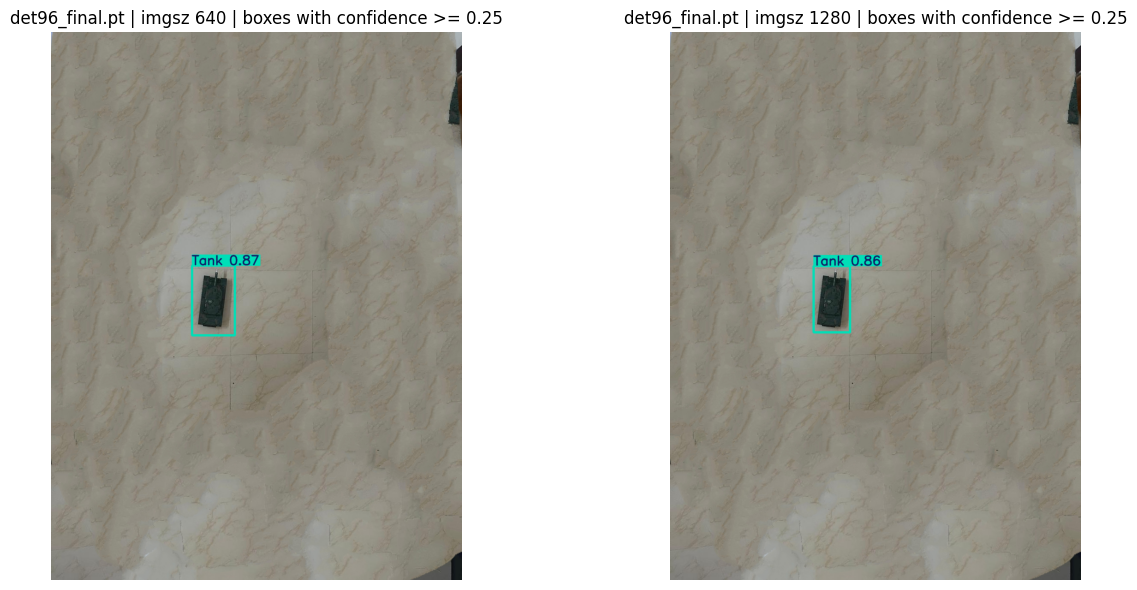

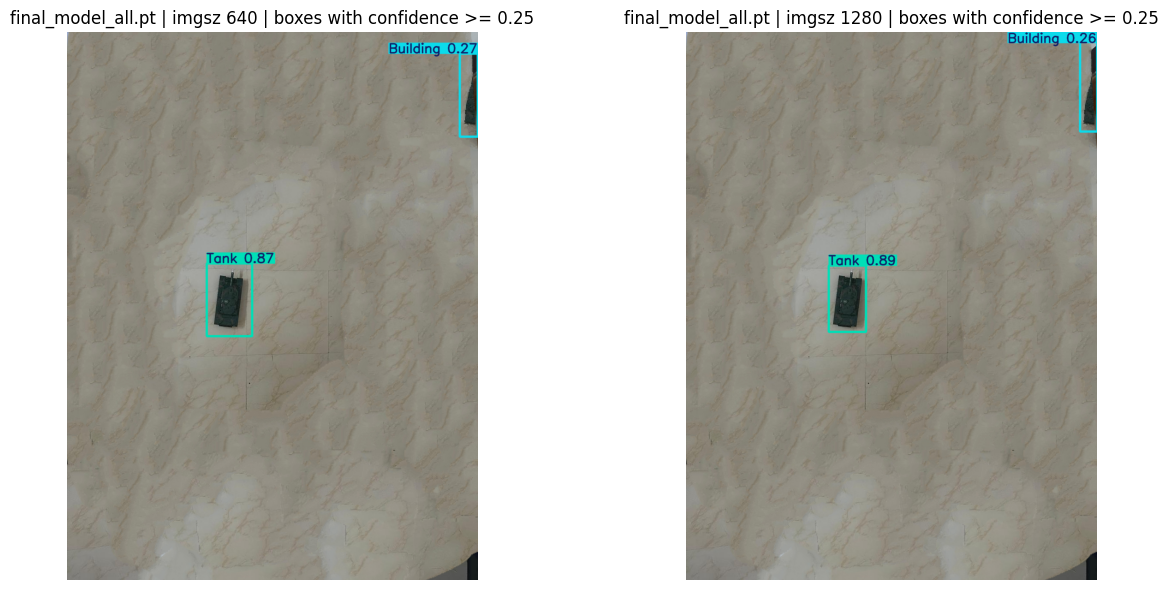

In [3]:
# ===== QUICK CHECK on ONE phone photo (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

IMG_PATH = "/kaggle/input/datasets/devrajkaransingh/saran-jpg/IMG_20261112_194659.jpg"
assert os.path.exists(IMG_PATH), f"Image not found: {IMG_PATH} (check Add Input -> the saran-jpg dataset)"

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))
print("testing only:", IMG_PATH)

img = ImageOps.exif_transpose(Image.open(IMG_PATH)).convert("RGB")      # fixes phone rotation
print("\n" + "=" * 90); print(os.path.basename(IMG_PATH), img.size)
for mname, model in MODELS.items():
    for sz in (640, 1280):
        r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
        dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
        air = [s for c, s in dets if c == 0]
        head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
        print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")

# one figure per loaded model (640 | 1280)
for mname, model in MODELS.items():
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = model.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{mname} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()

models loaded: ['det96_final.pt', 'final_model_all.pt']
photos found: ['IMG_20261111_144725.jpg', '1000180082.jpg', '1000180083.jpg', '1000180087.jpg', '1000180088.jpg', '1000180089.jpg', '1000180090.jpg', '1000180091.jpg', '1000180092.jpg', '1000180093.jpg', '1000180094.jpg', '1000180095.jpg', '1000180096.jpg', 'IMG20261110232430.jpg', 'IMG_20261111_001252.jpg', 'IMG_20261112_194659.jpg']

IMG_20261111_144725.jpg (3679, 2711)
det96_final.pt       imgsz  640: aircraft best confidence 0.65 | all (>=0.05): [('Aircraft', 0.65), ('Aircraft', 0.47), ('Aircraft', 0.1)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.61 | all (>=0.05): [('Aircraft', 0.61), ('Building', 0.3)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.56 | all (>=0.05): [('Aircraft', 0.56)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.69 | all (>=0.05): [('Aircraft', 0.69), ('Aircraft', 0.12), ('Building', 0.07)]


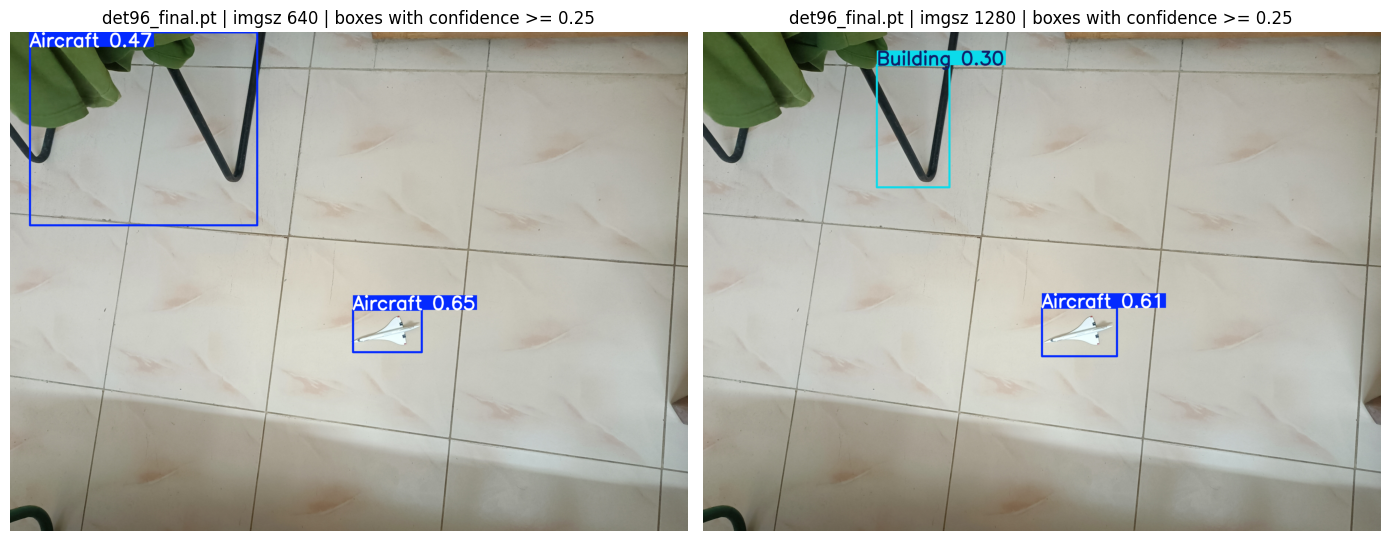


1000180082.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.66 | all (>=0.05): [('Aircraft', 0.66), ('Tank', 0.17), ('Building', 0.07), ('Aircraft', 0.05)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.76 | all (>=0.05): [('Aircraft', 0.76), ('Tank', 0.27)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.74 | all (>=0.05): [('Aircraft', 0.74), ('Tank', 0.26), ('Aircraft', 0.19), ('Building', 0.13), ('Aircraft', 0.08), ('Tank', 0.07)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.81 | all (>=0.05): [('Aircraft', 0.81), ('Building', 0.53), ('Aircraft', 0.11), ('Tank', 0.09)]


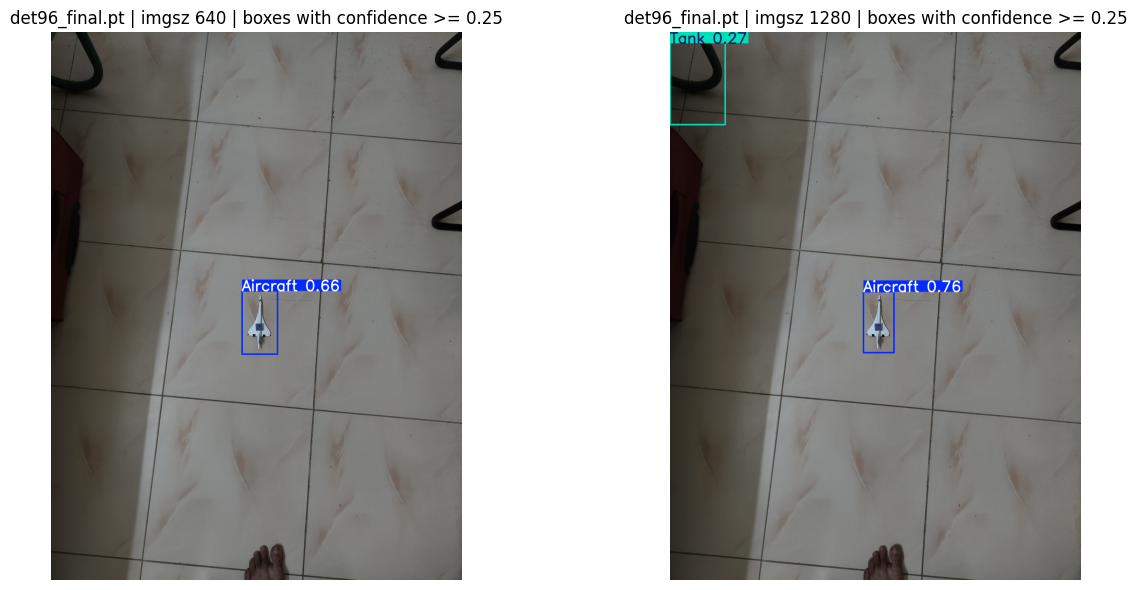


1000180083.jpg (8192, 6144)
det96_final.pt       imgsz  640: aircraft best confidence 0.79 | all (>=0.05): [('Aircraft', 0.79), ('Tank', 0.65), ('Building', 0.31), ('Aircraft', 0.21), ('Aircraft', 0.15), ('Tank', 0.09)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.81 | all (>=0.05): [('Aircraft', 0.81), ('Building', 0.59), ('Building', 0.14), ('Tank', 0.1)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.80 | all (>=0.05): [('Aircraft', 0.8), ('Aircraft', 0.4), ('Building', 0.28), ('Aircraft', 0.16), ('Aircraft', 0.14), ('Aircraft', 0.08)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.81 | all (>=0.05): [('Aircraft', 0.81), ('Aircraft', 0.33), ('Aircraft', 0.3), ('Aircraft', 0.2), ('Aircraft', 0.18), ('Aircraft', 0.12)]


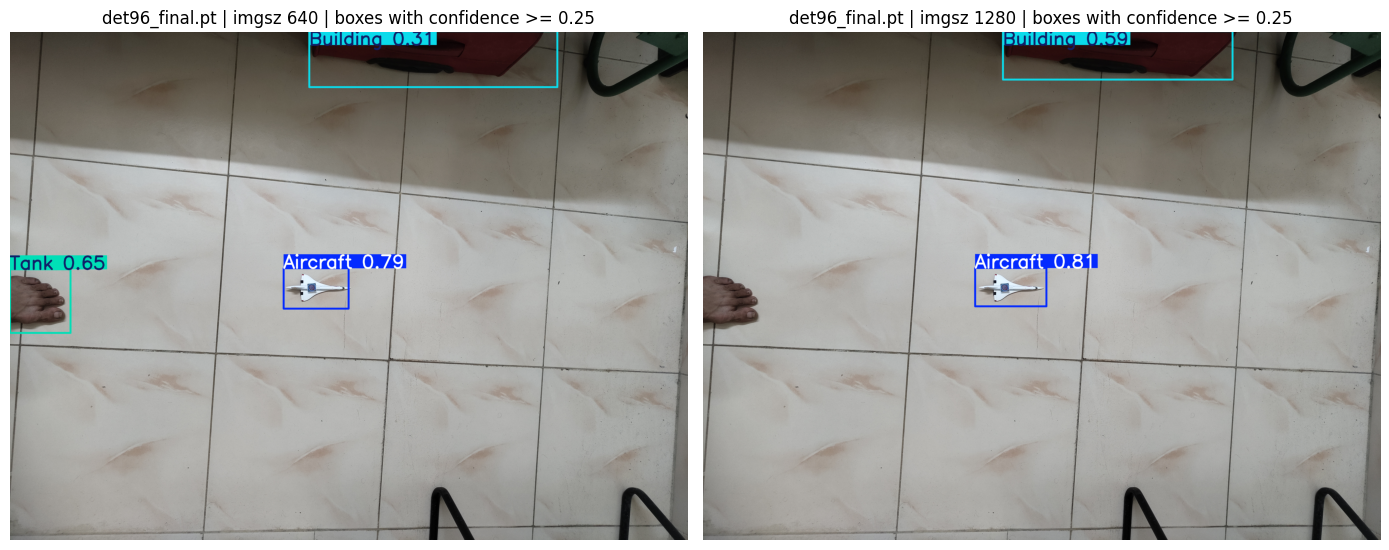


1000180087.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.76 | all (>=0.05): [('Aircraft', 0.76)]
det96_final.pt       imgsz 1280: no aircraft detected | all (>=0.05): [('Tank', 0.21)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.58 | all (>=0.05): [('Aircraft', 0.58)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.51 | all (>=0.05): [('Aircraft', 0.51), ('Aircraft', 0.13), ('Aircraft', 0.12), ('Aircraft', 0.09), ('Aircraft', 0.08), ('Aircraft', 0.08)]


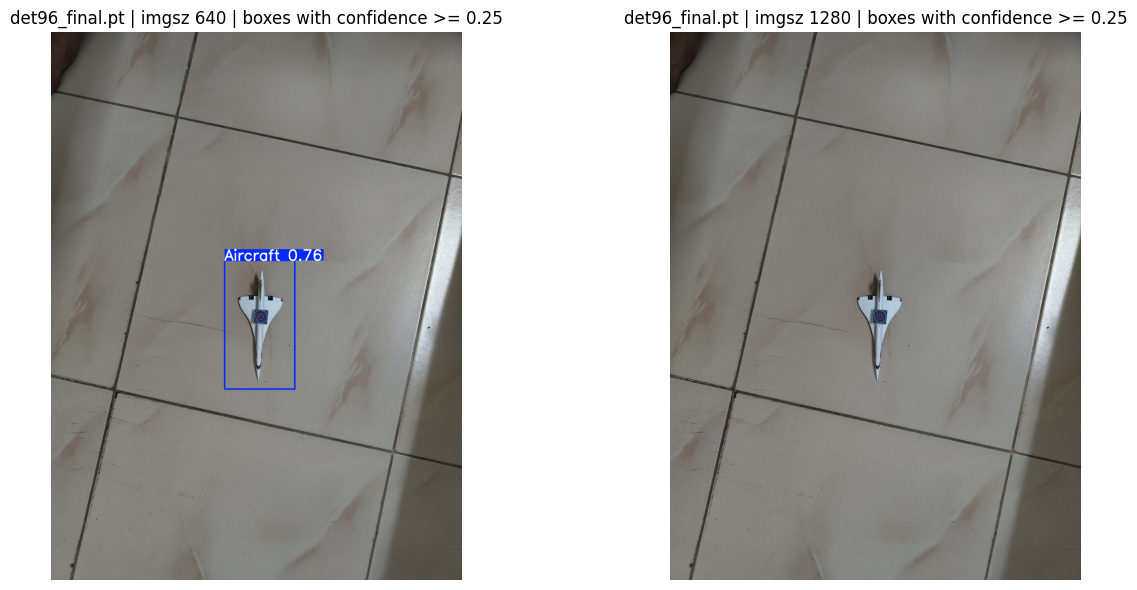


1000180088.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.64 | all (>=0.05): [('Aircraft', 0.64)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.41 | all (>=0.05): [('Aircraft', 0.41)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.81 | all (>=0.05): [('Aircraft', 0.81)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.79 | all (>=0.05): [('Aircraft', 0.79), ('Aircraft', 0.17), ('Aircraft', 0.15), ('Aircraft', 0.11), ('Aircraft', 0.08), ('Aircraft', 0.07)]


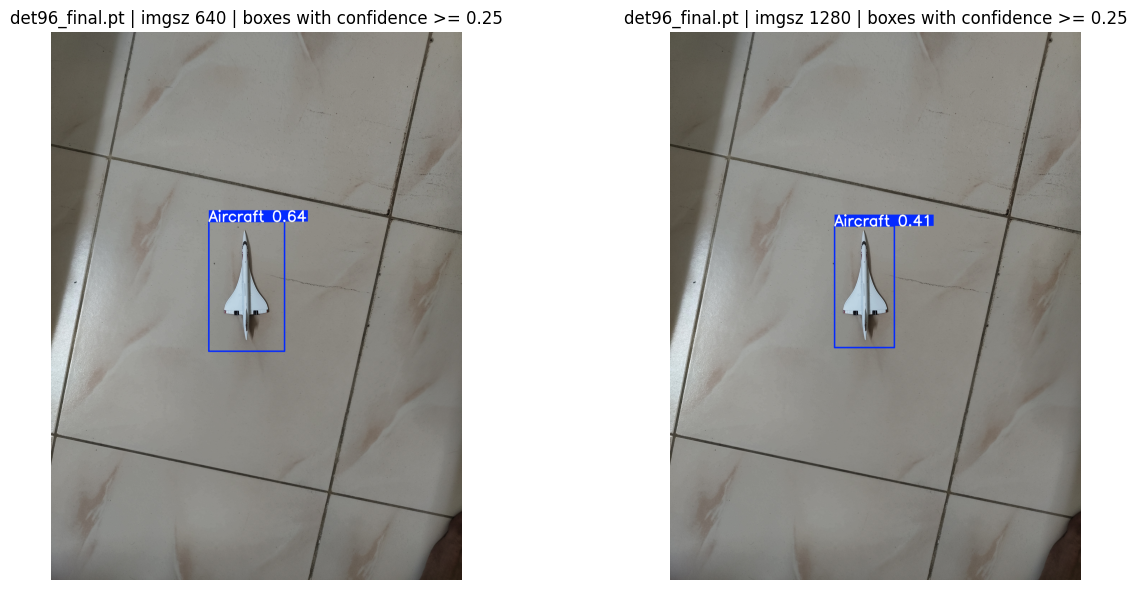


1000180089.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.40 | all (>=0.05): [('Aircraft', 0.4)]
det96_final.pt       imgsz 1280: no aircraft detected | all (>=0.05): [('Tank', 0.38)]
final_model_all.pt   imgsz  640: no aircraft detected | all (>=0.05): [('Tank', 0.71)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.15 | all (>=0.05): [('Aircraft', 0.15), ('Aircraft', 0.07)]


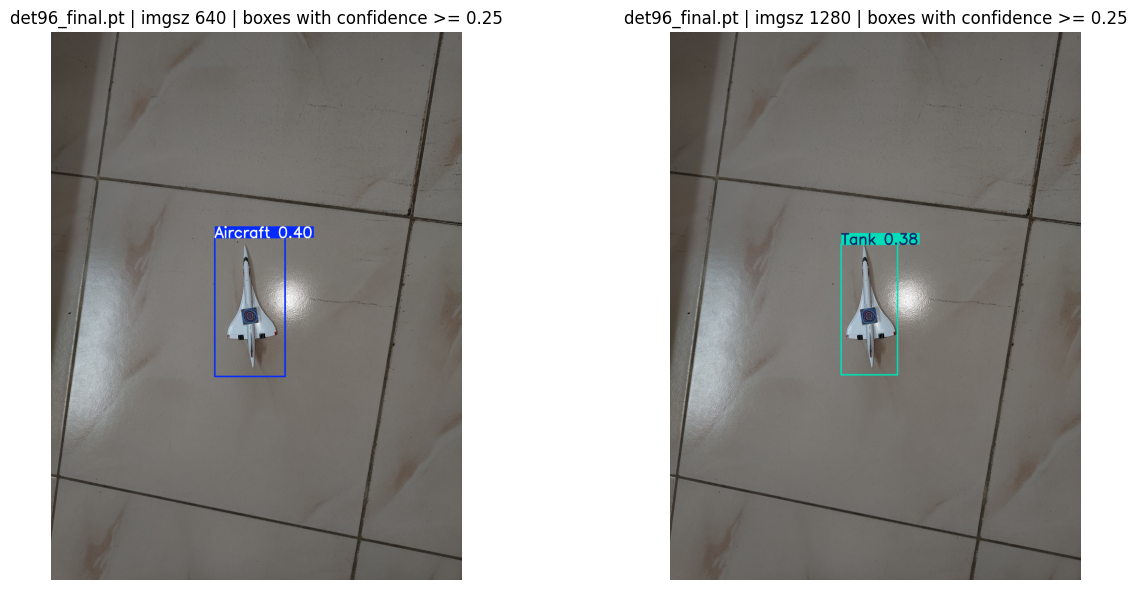


1000180090.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.58 | all (>=0.05): [('Aircraft', 0.58)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.07 | all (>=0.05): [('Tank', 0.1), ('Aircraft', 0.07)]
final_model_all.pt   imgsz  640: no aircraft detected | all (>=0.05): [('Tank', 0.58)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.12 | all (>=0.05): [('Aircraft', 0.12), ('Tank', 0.1), ('Aircraft', 0.09), ('Aircraft', 0.07)]


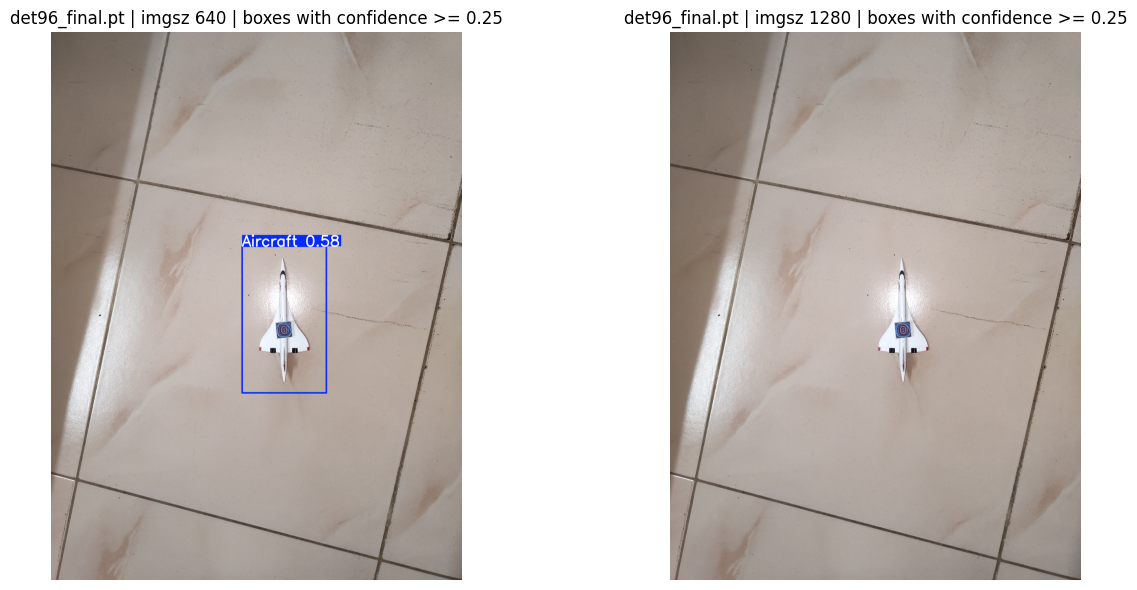


1000180091.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.34 | all (>=0.05): [('Aircraft', 0.34), ('Tank', 0.17)]
det96_final.pt       imgsz 1280: no aircraft detected | all (>=0.05): [('Tank', 0.09)]
final_model_all.pt   imgsz  640: no aircraft detected | all (>=0.05): [('Tank', 0.84)]
final_model_all.pt   imgsz 1280: no aircraft detected | all (>=0.05): [('Tank', 0.14), ('Building', 0.05)]


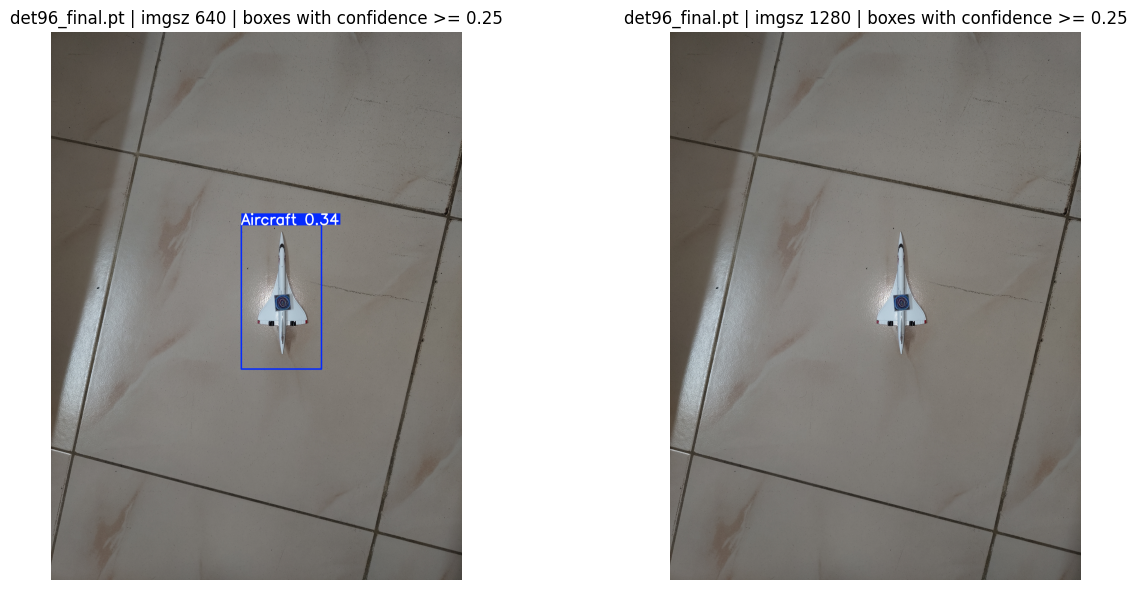


1000180092.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.83 | all (>=0.05): [('Aircraft', 0.83)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.45 | all (>=0.05): [('Aircraft', 0.45), ('Tank', 0.1), ('Tank', 0.08)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.73 | all (>=0.05): [('Aircraft', 0.73)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.75 | all (>=0.05): [('Aircraft', 0.75), ('Aircraft', 0.07), ('Aircraft', 0.06)]


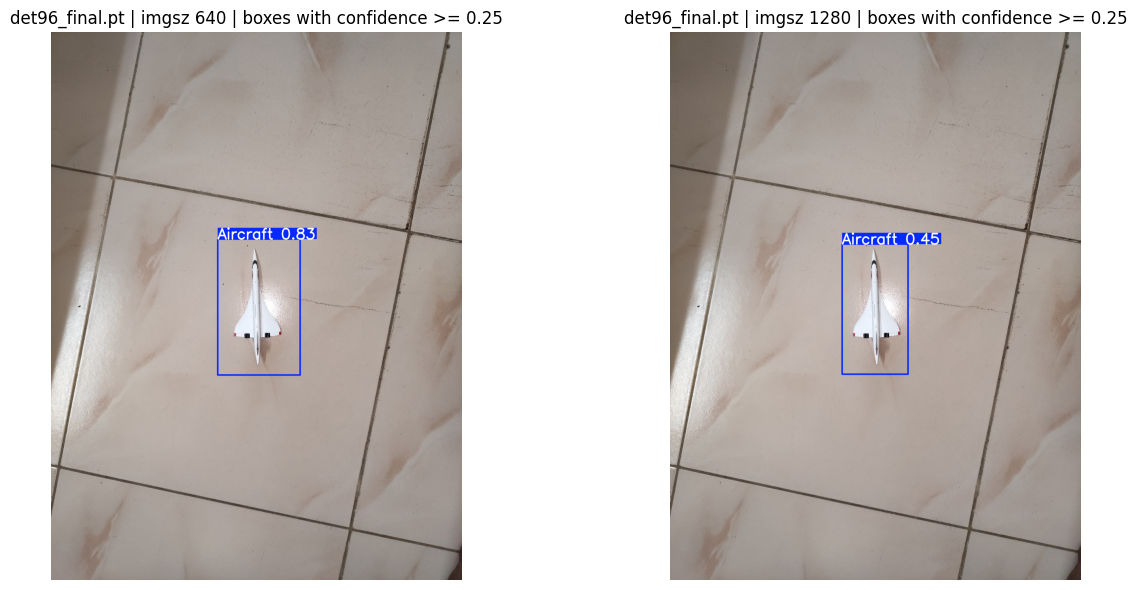


1000180093.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.66 | all (>=0.05): [('Aircraft', 0.66), ('Tank', 0.07)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.08 | all (>=0.05): [('Aircraft', 0.08), ('Tank', 0.06)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.47 | all (>=0.05): [('Aircraft', 0.47), ('Aircraft', 0.18), ('Tank', 0.06)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.11 | all (>=0.05): [('Aircraft', 0.11), ('Aircraft', 0.11), ('Aircraft', 0.06), ('Tank', 0.05)]


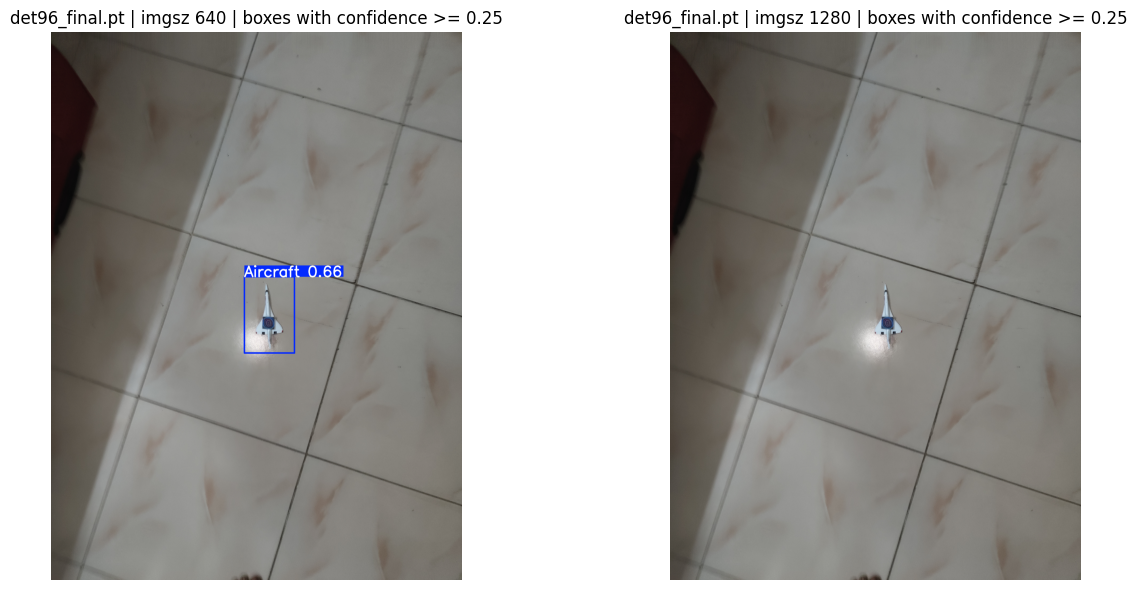


1000180094.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.74 | all (>=0.05): [('Aircraft', 0.74), ('Tank', 0.58), ('Aircraft', 0.53), ('Tank', 0.29), ('Aircraft', 0.08)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.31 | all (>=0.05): [('Tank', 0.71), ('Aircraft', 0.31), ('Tank', 0.16), ('Aircraft', 0.14)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.68 | all (>=0.05): [('Aircraft', 0.68), ('Tank', 0.52), ('Tank', 0.36), ('Tank', 0.13), ('Tank', 0.06)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.14 | all (>=0.05): [('Tank', 0.61), ('Tank', 0.35), ('Aircraft', 0.14), ('Tank', 0.05)]


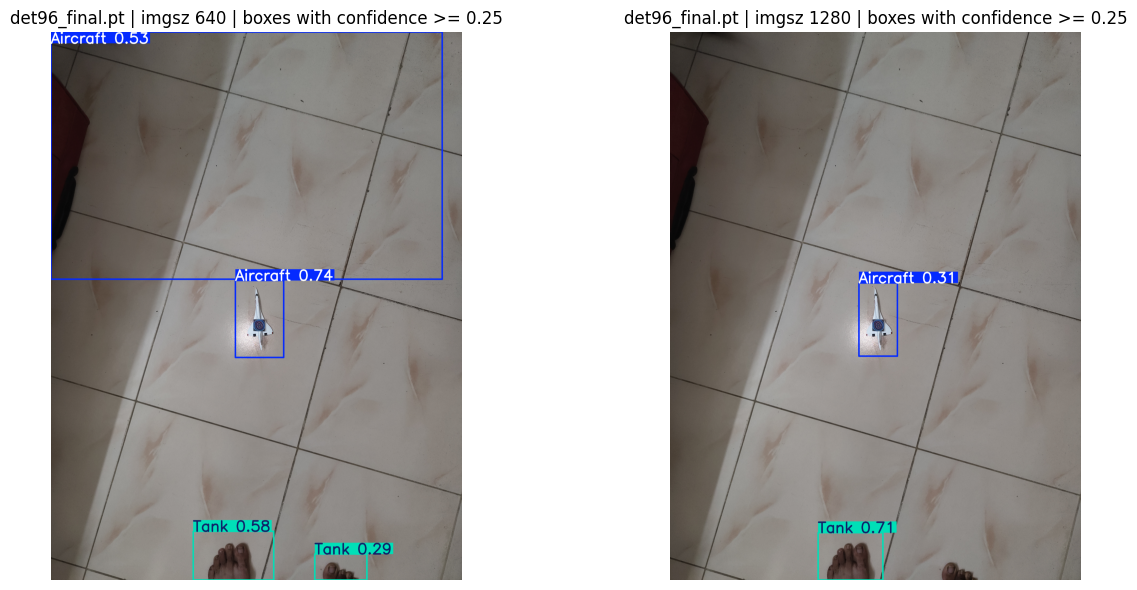


1000180095.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.71 | all (>=0.05): [('Aircraft', 0.71), ('Tank', 0.51), ('Tank', 0.41), ('Tank', 0.06)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.21 | all (>=0.05): [('Tank', 0.74), ('Tank', 0.33), ('Aircraft', 0.21), ('Aircraft', 0.06)]
final_model_all.pt   imgsz  640: no aircraft detected | all (>=0.05): [('Tank', 0.8), ('Tank', 0.66), ('Tank', 0.19), ('Tank', 0.06)]
final_model_all.pt   imgsz 1280: no aircraft detected | all (>=0.05): [('Tank', 0.82), ('Tank', 0.33), ('Tank', 0.3), ('Tank', 0.15), ('Tank', 0.07)]


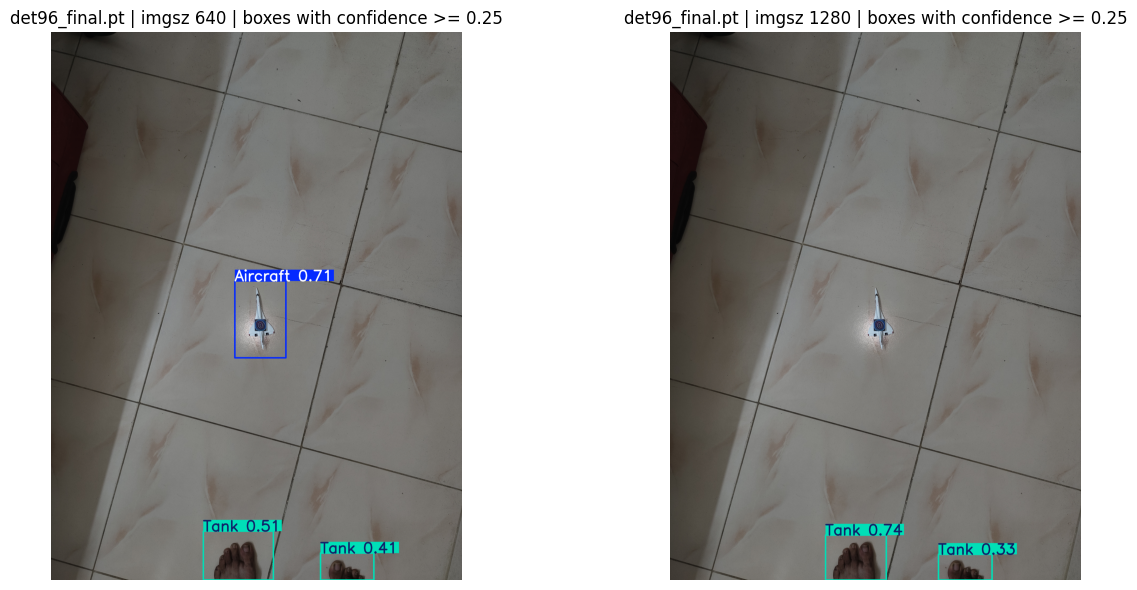


1000180096.jpg (6144, 8192)
det96_final.pt       imgsz  640: aircraft best confidence 0.75 | all (>=0.05): [('Aircraft', 0.75), ('Tank', 0.56), ('Tank', 0.47), ('Tank', 0.1)]
det96_final.pt       imgsz 1280: aircraft best confidence 0.34 | all (>=0.05): [('Tank', 0.6), ('Aircraft', 0.34), ('Aircraft', 0.13), ('Tank', 0.1), ('Tank', 0.07), ('Tank', 0.05)]
final_model_all.pt   imgsz  640: aircraft best confidence 0.29 | all (>=0.05): [('Tank', 0.5), ('Tank', 0.48), ('Tank', 0.38), ('Aircraft', 0.29), ('Tank', 0.23)]
final_model_all.pt   imgsz 1280: aircraft best confidence 0.70 | all (>=0.05): [('Aircraft', 0.7), ('Tank', 0.22), ('Tank', 0.16), ('Aircraft', 0.13), ('Tank', 0.11), ('Aircraft', 0.1)]


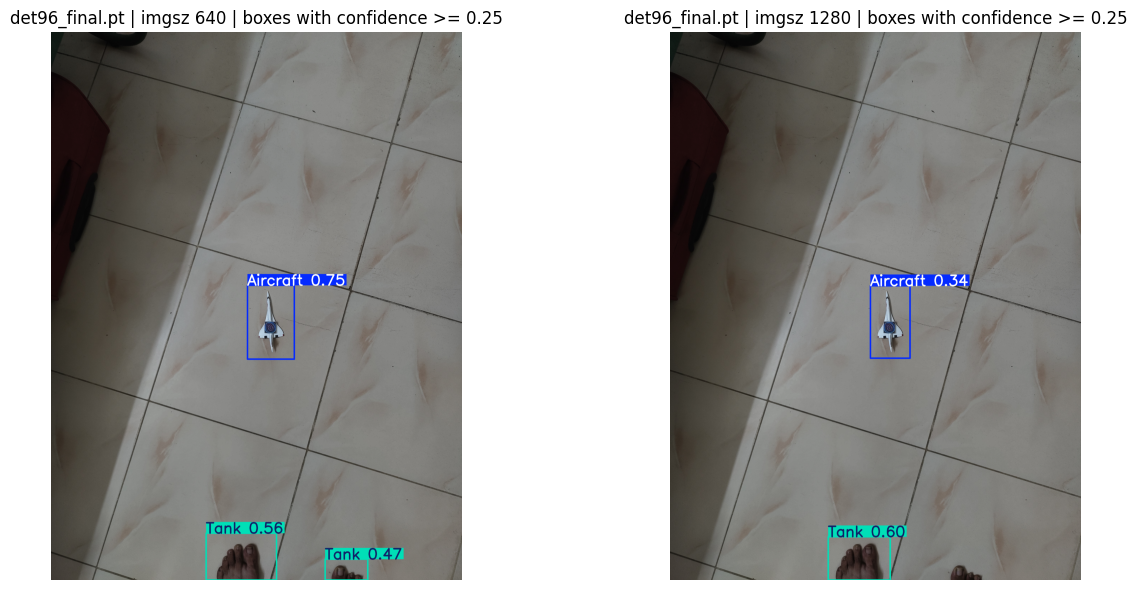


IMG20261110232430.jpg (4000, 3000)
det96_final.pt       imgsz  640: no aircraft detected | all (>=0.05): [('Building', 0.53), ('Building', 0.51), ('Building', 0.5), ('Building', 0.49), ('Building', 0.49), ('Building', 0.49)]
det96_final.pt       imgsz 1280: no aircraft detected | all (>=0.05): [('Building', 0.69), ('Building', 0.69), ('Building', 0.68), ('Building', 0.68), ('Building', 0.68), ('Building', 0.67)]
final_model_all.pt   imgsz  640: no aircraft detected | all (>=0.05): [('Building', 0.59), ('Building', 0.53), ('Building', 0.52), ('Building', 0.5), ('Building', 0.5), ('Building', 0.49)]
final_model_all.pt   imgsz 1280: no aircraft detected | all (>=0.05): [('Military Truck', 0.8), ('Military Truck', 0.76), ('Building', 0.76), ('Military Truck', 0.73), ('Building', 0.72), ('Military Truck', 0.7)]


In [ ]:
# ===== QUICK CHECK: does our trained YOLO detect the aircraft in my phone photo? (CPU) =====
import os, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
import matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps
from ultralytics import YOLO
NAMES = {0: "Aircraft", 1: "Building", 2: "Military Truck", 3: "Tank"}

def find(name):
    return [os.path.join(r, name) for r, d, f in os.walk("/kaggle/input") if name in f]
MODELS = {}
for fn in ["det96_final.pt", "final_model_all.pt"]:
    p = find(fn)
    if p:
        MODELS[fn] = YOLO(sorted(p, key=lambda q: "FINAL_PROJECT_BACKUP" not in q)[0])
assert MODELS, "No model found: add uas-final-backup (det96_final.pt) or uas-models (final_model_all.pt) with Add Input"
print("models loaded:", list(MODELS))

SKIP = ("training data", "validation data", "testing data", "backup", "uas-aerial", "uas-final", "uas-models", "review3")
IMGS = [os.path.join(r, f) for r, d, fs in os.walk("/kaggle/input") for f in fs
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not any(k in r.lower() for k in SKIP)]
print("photos found:", [os.path.basename(p) for p in IMGS])
assert IMGS, "No phone photo found: use Input -> Upload and upload your JPG"

for p in IMGS:
    img = ImageOps.exif_transpose(Image.open(p)).convert("RGB")      # fixes phone rotation
    print("\n" + "=" * 90); print(os.path.basename(p), img.size)
    for mname, model in MODELS.items():
        for sz in (640, 1280):                                        # 1280 helps when the object is small in a big photo
            r = model.predict(img, conf=0.05, imgsz=sz, device="cpu", verbose=False)[0]
            dets = sorted(zip(r.boxes.cls.int().tolist(), r.boxes.conf.tolist()), key=lambda t: -t[1])
            air = [s for c, s in dets if c == 0]
            head = f"aircraft best confidence {max(air):.2f}" if air else "no aircraft detected"
            print(f"{mname:20s} imgsz {sz:4d}: {head} | all (>=0.05): {[(NAMES[c], round(s, 2)) for c, s in dets[:6]]}")
    first = next(iter(MODELS.values()))
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, sz in zip(ax, (640, 1280)):
        r = first.predict(img, conf=0.25, imgsz=sz, device="cpu", verbose=False)[0]
        a.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{list(MODELS)[0]} | imgsz {sz} | boxes with confidence >= 0.25")
    plt.tight_layout(); plt.show()